<a href="https://colab.research.google.com/github/Euripedes357/GMSF/blob/main/BRAIN_TUMOR_MRI_Quando_uma_Rede_Convolucional_Aprende_a_Olhar_o_Cerebro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Passo 1 — Conectar o Google Drive e localizar o arquivo

O conjunto de dados foi baixado do Kaggle como `archive.zip` e guardado no Google Drive do autor, na pasta `BRAIN TUMOR MRI - by Euripedes Gomes`. O comando `drive.mount` conecta o Drive ao Colab (pede autorização da conta Google na primeira execução), e o Drive passa a ser acessível como uma pasta em `/content/drive/MyDrive/`.

As duas linhas de `print` conferem que o arquivo foi encontrado e que o tamanho bate com o esperado (cerca de 164,7 MB). Essa conferência evita trabalhar, sem perceber, com um arquivo diferente do que foi auditado.

In [119]:
# Passo 1 — Conectar o Google Drive ao Colab e localizar o archive.zip
import os
from google.colab import drive

drive.mount('/content/drive')

ZIP_DRIVE = '/content/drive/MyDrive/BRAIN TUMOR MRI - by Euripedes Gomes/archive.zip'

print('Arquivo existe?', os.path.exists(ZIP_DRIVE))
print('Tamanho (MB)  :', round(os.path.getsize(ZIP_DRIVE) / 1e6, 1))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Arquivo existe? True
Tamanho (MB)  : 164.7


## Passo 2 — Descompactar as imagens e preparar a pasta do relatório

O Drive montado é lento para ler milhares de arquivos pequenos. Por isso o zip é copiado para o disco local da máquina do Colab (`/content/`) e descompactado em `/content/data`. Esse disco é apagado ao fim da sessão, mas o zip original permanece no Drive, bastando repetir os Passos 1 e 2 para reconstruir tudo.

A célula também cria a pasta `relatorio/` dentro da pasta do projeto no Drive. Todas as figuras (`fig01_...png`) e tabelas (`tab01_...csv`) geradas ao longo do notebook serão gravadas nela, prontas para o relatório final.

Como alguns zips do Kaggle trazem uma pasta-raiz extra, as pastas `Training` e `Testing` são localizadas com `glob` em qualquer nível. A lista de classes vem dos nomes das subpastas — no dataset, o nome da pasta é o rótulo.

In [120]:
# Passo 2 — Descompactar o archive.zip no disco local do Colab e criar a pasta do relatório
import zipfile, shutil, glob

PASTA_PROJETO = '/content/drive/MyDrive/BRAIN TUMOR MRI - by Euripedes Gomes'
RELATORIO_DIR = PASTA_PROJETO + '/relatorio'   # figuras e tabelas para o Word
ZIP_LOCAL     = '/content/archive.zip'
DATA_DIR      = '/content/data'

os.makedirs(RELATORIO_DIR, exist_ok=True)
shutil.copy(ZIP_DRIVE, ZIP_LOCAL)             # copia o zip do Drive para o disco do Colab
zipfile.ZipFile(ZIP_LOCAL).extractall(DATA_DIR)

TRAIN_DIR = glob.glob(DATA_DIR + '/**/Training', recursive=True)[0]
TEST_DIR  = glob.glob(DATA_DIR + '/**/Testing',  recursive=True)[0]
CLASSES   = sorted(os.listdir(TRAIN_DIR))

print('Pasta do relatório:', RELATORIO_DIR)
print('Training          :', TRAIN_DIR)
print('Testing           :', TEST_DIR)
print('Classes           :', CLASSES)

Pasta do relatório: /content/drive/MyDrive/BRAIN TUMOR MRI - by Euripedes Gomes/relatorio
Training          : /content/data/Training
Testing           : /content/data/Testing
Classes           : ['glioma', 'meningioma', 'notumor', 'pituitary']


**Observação:** a cópia e a descompactação levaram cerca de 8 segundos. O zip não traz pasta-raiz extra: `Training` e `Testing` ficaram diretamente em `/content/data/`. As quatro classes foram reconhecidas a partir dos nomes das subpastas, em ordem alfabética — `glioma`, `meningioma`, `notumor`, `pituitary` — e essa será a ordem dos rótulos (0, 1, 2, 3) em todo o notebook. A pasta `relatorio/` foi criada no Drive, ainda vazia.

## Passo 3 — Ambiente de execução, versões e sementes

O critério 1 do professor pede linguagem, versões, bibliotecas e ambiente. Esta célula importa as bibliotecas que serão usadas em todo o notebook (NumPy, Pandas, Matplotlib, Pillow, scikit-learn e TensorFlow/Keras) e imprime a versão de cada uma, além de verificar se há GPU disponível.

A célula também fixa a semente (`SEED = 42`) no Python, no NumPy e no TensorFlow. A semente controla tudo o que envolve sorteio — embaralhamento das imagens, divisão treino/validação, inicialização dos pesos da rede — para que uma nova execução reproduza os mesmos resultados. A reprodutibilidade completa em GPU não é garantida (algumas operações da GPU são não determinísticas), e isso será declarado como limitação no relatório.

**Observação:** a cópia e a descompactação levaram cerca de 8 segundos. O zip não traz pasta-raiz extra: `Training` e `Testing` ficaram diretamente em `/content/data/`. As quatro classes foram reconhecidas a partir dos nomes das subpastas, em ordem alfabética — `glioma`, `meningioma`, `notumor`, `pituitary` — e essa será a ordem dos rótulos (0, 1, 2, 3) em todo o notebook. A pasta `relatorio/` foi criada no Drive, ainda vazia.

In [121]:
# Passo 3 — Ambiente de execução, versões das bibliotecas e sementes
import sys, random, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
import sklearn
import tensorflow as tf
from tensorflow import keras

# Sementes fixas para reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('Python       :', platform.python_version())
print('TensorFlow   :', tf.__version__)
print('Keras        :', keras.__version__)
print('NumPy        :', np.__version__)
print('Pandas       :', pd.__version__)
print('Matplotlib   :', matplotlib.__version__)
print('Pillow       :', PIL.__version__)
print('scikit-learn :', sklearn.__version__)
print('GPU          :', tf.config.list_physical_devices('GPU'))
print('Semente      :', SEED)

Python       : 3.13.16
TensorFlow   : 2.21.0
Keras        : 3.13.2
NumPy        : 2.4.6
Pandas       : 2.2.3
Matplotlib   : 3.10.0
Pillow       : 11.3.0
scikit-learn : 1.6.1
GPU          : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Semente      : 42


**Observação:** o ambiente é o Google Colab com GPU NVIDIA T4, Python 3.13.16, TensorFlow 2.21.0, Keras 3.13.2, NumPy 2.4.6, Pandas 2.2.3, Matplotlib 3.10.0, Pillow 11.3.0 e scikit-learn 1.6.1, com semente fixa 42. Estas versões são as que constarão na seção de ambiente do relatório e no README do repositório.

### Bibliotecas utilizadas

Cada biblioteca resolve um problema específico da cadeia que vai do arquivo de imagem ao resultado da rede.

**Python 3.13** — linguagem em que todo o notebook é escrito; padrão de fato em ciência de dados e aprendizado profundo.

**Pillow 11.3** (Clark et al., 2015) — *abrir as imagens.* Um JPEG é um formato comprimido; o Pillow o descompacta em pixels, lê dimensões e modo de cor, converte para tons de cinza e redimensiona. É a porta entre o arquivo no disco e a matemática.

**NumPy 2.4** (Harris et al., 2020) — *calcular.* Uma imagem 128×128 é uma matriz de 16.384 números; o NumPy opera sobre matrizes inteiras de uma só vez, o que torna viável o processamento de milhares de imagens. Todas as estatísticas da análise exploratória são calculadas com ele.

**Pandas 2.2** (McKinney, 2010) — *organizar em tabelas.* Equivale a uma planilha dentro do Python: contagens por classe, tabelas de qualidade dos dados e a comparação entre experimentos, exportadas em CSV para o relatório.

**Matplotlib 3.10** (Hunter, 2007) — *desenhar.* Transforma números em figuras com título, eixos e legenda: distribuição das classes, exemplos de imagens, curvas de treino e validação e matriz de confusão, gravadas em PNG.

**TensorFlow 2.21** (Abadi et al., 2016) — *treinar.* É o motor do aprendizado profundo: calcula automaticamente os gradientes de milhões de parâmetros (retropropagação) e executa as operações na GPU.

**Keras 3.13** (Chollet et al., 2015) — *descrever a rede.* Interface de alto nível sobre o TensorFlow: a CNN é definida camada a camada, com função de perda, otimizador e métricas, sem programar a matemática do treinamento.

**scikit-learn 1.6** (Pedregosa et al., 2011) — *dividir e avaliar.* Faz a divisão estratificada entre treino e validação e calcula as métricas com a definição correta: acurácia, precisão, revocação, F1 e matriz de confusão. Não treina a rede; atua antes e depois dela.

**Google Colab** — ambiente de execução em nuvem que hospeda o notebook e fornece a GPU NVIDIA T4.

As referências completas de cada biblioteca, no formato NBR 6023, constarão na lista final do relatório, na ordem da primeira citação.

## Definição do problema

**Tarefa.** Classificação de imagens de ressonância magnética cerebral em quatro categorias: *glioma*, *meningioma*, *pituitary* e *notumor*. Da mesma saída deriva-se a leitura binária entre presença e ausência de tumor, sem treinar outra rede. Ficam fora do escopo a segmentação, a localização do tumor, o grau, o prognóstico e qualquer uso clínico.

**Entrada e resposta.** A entrada é uma imagem de RM, padronizada para 128×128 pixels em tons de cinza. A resposta é a classe da imagem, codificada como um vetor de quatro probabilidades (uma por classe), cuja maior probabilidade define a predição.

**Por que uma CNN.** Uma imagem é uma matriz de pixels cuja informação está na relação espacial entre vizinhos. Achatá-la em vetor para uma rede densa descartaria essa estrutura e elevaria o número de parâmetros; filtros convolucionais com pesos compartilhados detectam padrões locais em qualquer posição, e o pooling resume a informação espacial.

**Pergunta de pesquisa.** Em que medida uma CNN simples, avaliada sem vazamento entre treinamento, validação e teste, classifica corretamente as quatro categorias, e como as decisões de treinamento e regularização contribuem para sua generalização?

**Objetivo geral.** Desenvolver e avaliar uma CNN para a classificação de imagens de RM cerebral em quatro categorias, com avaliação final em conjunto de teste preservado.

**Objetivos específicos.** (i) Caracterizar o conjunto e auditar sua qualidade, incluindo duplicidades e possível vazamento entre os subconjuntos; (ii) construir a rede e treiná-la com validação independente; (iii) comparar configurações de taxa de aprendizado, Early Stopping, Dropout e aumento de dados; (iv) avaliar o desempenho com acurácia, precisão, revocação, F1 e matriz de confusão, incluindo a leitura binária.

## Passo 4 — Distribuição das imagens por subconjunto e classe

O critério 1 pede o número de observações e a distribuição das classes. Esta célula conta as imagens de cada classe em `Training` e `Testing`, monta a tabela de contagem e desenha o primeiro gráfico do trabalho.

A contagem serve a dois propósitos. Primeiro, conferir se o arquivo analisado reproduz o levantamento do documento de definição (1.400 imagens por classe no Training e 400 no Testing, 7.200 no total). Segundo, verificar o balanceamento: classes equilibradas dispensam técnicas de compensação (pesos de classe ou reamostragem) e permitem usar a acurácia como métrica principal sem distorção.

A tabela é gravada em `relatorio/tab01_distribuicao_classes.csv` e o gráfico em `relatorio/fig01_distribuicao_classes.png`, os primeiros itens do relatório final.

Subconjunto  Training  Testing  Total
Classe                               
glioma           1400      400   1800
meningioma       1400      400   1800
notumor          1400      400   1800
pituitary        1400      400   1800
Total            5600     1600   7200


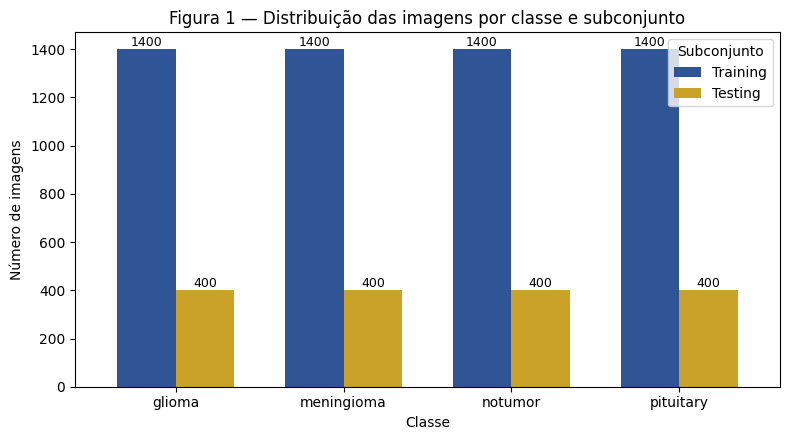

In [122]:
# Passo 4 — Contagem de imagens por subconjunto e classe, tabela e gráfico
SUBSETS = {'Training': TRAIN_DIR, 'Testing': TEST_DIR}

linhas = []
for nome, pasta in SUBSETS.items():
    for cls in CLASSES:
        n = len(os.listdir(os.path.join(pasta, cls)))
        linhas.append({'Subconjunto': nome, 'Classe': cls, 'Imagens': n})

contagem = (pd.DataFrame(linhas)
              .pivot(index='Classe', columns='Subconjunto', values='Imagens')
              [['Training', 'Testing']])
contagem['Total'] = contagem.sum(axis=1)
contagem.loc['Total'] = contagem.sum()

print(contagem)
contagem.to_csv(os.path.join(RELATORIO_DIR, 'tab01_distribuicao_classes.csv'))

# Gráfico de barras agrupadas (sem a linha Total)
dados = contagem.drop(index='Total')[['Training', 'Testing']]
fig, ax = plt.subplots(figsize=(8, 4.5))
dados.plot(kind='bar', ax=ax, color=['#2F5597', '#C9A227'], width=0.7)
ax.set_title('Figura 1 — Distribuição das imagens por classe e subconjunto')
ax.set_xlabel('Classe')
ax.set_ylabel('Número de imagens')
ax.legend(title='Subconjunto')
ax.tick_params(axis='x', rotation=0)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(RELATORIO_DIR, 'fig01_distribuicao_classes.png'), dpi=200)
plt.show()

**Observação:** a contagem reproduz integralmente o levantamento do documento de definição: 1.400 imagens por classe no Training (5.600) e 400 por classe no Testing (1.600), totalizando 7.200. As quatro classes são perfeitamente balanceadas nos dois subconjuntos, o que dispensa pesos de classe ou reamostragem e autoriza o uso da acurácia como métrica principal, complementada por precisão, revocação e F1 por classe. A contagem difere da descrição pública do dataset (7.023 imagens), e por isso todas as estatísticas deste trabalho se referem ao arquivo efetivamente analisado. Tabela e figura gravadas em `relatorio/tab01_distribuicao_classes.csv` e `relatorio/fig01_distribuicao_classes.png`.

# Fase 2 — Preparação e análise exploratória

Esta fase responde ao critério 2 do professor: conhecer os tipos de dado, procurar duplicidades e valores extremos, justificar as transformações e dividir treino, validação e teste sem vazamento. Antes de qualquer tratamento, a base é auditada como foi recebida.

## Passo 5 — Dimensões, modo de cor e integridade dos arquivos

Uma rede convolucional exige que todas as imagens tenham o mesmo tamanho e o mesmo número de canais, e o conjunto não garante isso. Esta célula abre o cabeçalho de cada uma das 7.200 imagens com o Pillow, sem carregar todos os pixels, e registra a largura, a altura e o modo de cor (`L` é um canal em tons de cinza, `RGB` são três canais, `RGBA` e `P` são variantes). Qualquer arquivo que não abrir é contabilizado como corrompido.

O objetivo é reproduzir no Colab o levantamento preliminar do documento de definição (Tabela 4) e verificar se tamanho e cor se associam à classe. Se isso acontecer, a rede pode aprender atributos do arquivo, como o tamanho ou a codificação de cor, em vez da anatomia do cérebro, e a acurácia ficaria inflada sem o modelo saber ler uma ressonância.

O resultado é gravado em `relatorio/tab02_dimensoes_modos.csv`, e os números do notebook prevalecem sobre os do levantamento feito fora dele.

In [123]:
# Passo 5 — Dimensões, modo de cor e integridade de todas as imagens
from PIL import Image

registros = []
corrompidos = []

for sub, pasta in SUBSETS.items():
    for cls in CLASSES:
        pasta_cls = os.path.join(pasta, cls)
        for arq in sorted(os.listdir(pasta_cls)):
            caminho = os.path.join(pasta_cls, arq)
            try:
                with Image.open(caminho) as img:      # lê só o cabeçalho, não os pixels
                    largura, altura = img.size
                    modo = img.mode
                registros.append({'subconjunto': sub, 'classe': cls, 'arquivo': arq,
                                  'largura': largura, 'altura': altura, 'modo': modo})
            except Exception as erro:
                corrompidos.append((caminho, str(erro)))

df = pd.DataFrame(registros)
df['dimensao'] = df['largura'].astype(str) + '×' + df['altura'].astype(str)

# Tabela-resumo por subconjunto e classe (equivale à Tabela 4 do documento de definição)
linhas = []
for sub in SUBSETS:
    for cls in CLASSES:
        g = df[(df['subconjunto'] == sub) & (df['classe'] == cls)]
        dims = g['dimensao'].value_counts()
        modos = g['modo'].value_counts()
        linhas.append({
            'Subconjunto': sub,
            'Classe': cls,
            'Dimensões distintas': g['dimensao'].nunique(),
            'Mais frequente (n)': f'{dims.index[0]} ({dims.iloc[0]})',
            'Modo de cor (n)': '; '.join(f'{m} {n}' for m, n in modos.items()),
        })
tabela = pd.DataFrame(linhas)

print(f'Imagens lidas      : {len(df)}')
print(f'Arquivos corrompidos: {len(corrompidos)}')
print()
print(tabela.to_string(index=False))

tabela.to_csv(os.path.join(RELATORIO_DIR, 'tab02_dimensoes_modos.csv'), index=False)

Imagens lidas      : 7200
Arquivos corrompidos: 0

Subconjunto     Classe  Dimensões distintas Mais frequente (n)             Modo de cor (n)
   Training     glioma                    1     512×512 (1400)             L 1173; RGB 227
   Training meningioma                  116     512×512 (1267)              RGB 845; L 555
   Training    notumor                  250      225×225 (240) RGB 1373; L 23; RGBA 3; P 1
   Training  pituitary                   27     512×512 (1328)              RGB 793; L 607
    Testing     glioma                   62      512×512 (324)              L 226; RGB 174
    Testing meningioma                   99      512×512 (283)              RGB 246; L 154
    Testing    notumor                   55       225×225 (77)                RGB 394; L 6
    Testing  pituitary                    2      512×512 (392)               L 323; RGB 77


**Observação:** as 7.200 imagens foram lidas sem nenhum arquivo corrompido, e os números reproduzem integralmente o levantamento preliminar do documento de definição (Tabela 4). O tamanho das imagens não é único: o glioma do Training tem uma única dimensão (512×512), o meningioma tem 116, o pituitary tem 27 e o notumor tem 250, com apenas 240 imagens no tamanho mais frequente (225×225). O modo de cor também se associa à classe: no Training, 98% das imagens notumor estão em RGB (1.373 de 1.400), contra 16% no glioma (227), 60% no meningioma (845) e 57% no pituitary (793); há ainda quatro imagens notumor em modos raros (3 em RGBA e 1 em P). Training e Testing também diferem entre si, como no pituitary (57% em RGB no Training e 19% no Testing) e no glioma (16% contra 44%). Como tamanho e cor revelam parte da classe, a rede poderia aprender atributos do arquivo em vez da anatomia; a padronização para um único tamanho e para tons de cinza, prevista no Passo 10, reduz essas pistas, mas não necessariamente todas, e isso será declarado como limitação.

### Figura 2 — Modo de cor por classe e subconjunto

A tabela acima é precisa, mas difícil de comparar de relance. O gráfico abaixo mostra, para cada combinação de subconjunto e classe, a proporção de imagens em cada modo de cor (tons de cinza `L`, `RGB`, `RGBA` e `P`). Se o modo de cor fosse independente da classe, as oito barras teriam a mesma composição; diferenças marcantes entre elas indicam que a cor funciona como pista para a classe.

O gráfico é gravado em `relatorio/fig02_modo_cor_por_classe.png`.

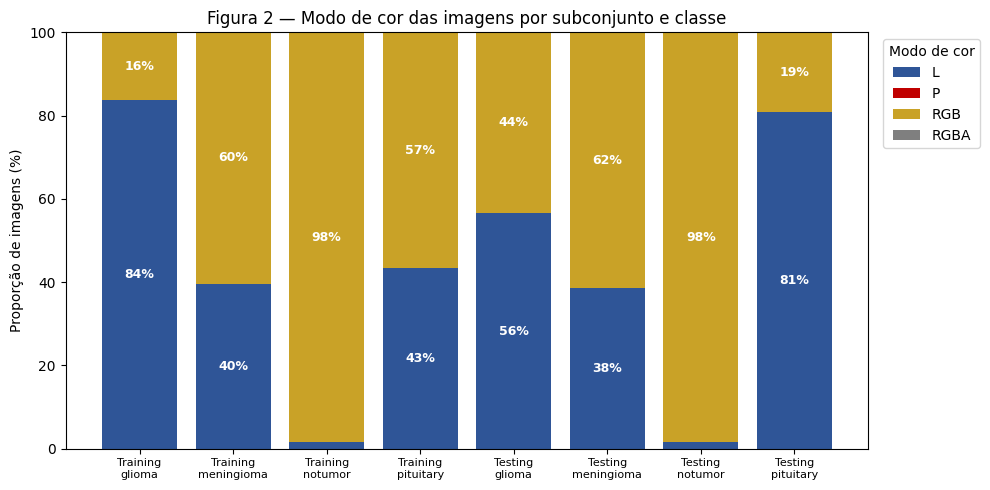

In [124]:
# Figura 2 — Proporção de imagens por modo de cor, por subconjunto e classe
prop = (pd.crosstab([df['subconjunto'], df['classe']], df['modo'], normalize='index') * 100)
prop = prop.reindex([(s, c) for s in SUBSETS for c in CLASSES])   # ordem fixa
prop.index = [f'{s}\n{c}' for s, c in prop.index]

cores = {'L': '#2F5597', 'RGB': '#C9A227', 'RGBA': '#7F7F7F', 'P': '#C00000'}
fig, ax = plt.subplots(figsize=(10, 5))
base = np.zeros(len(prop))
for modo in prop.columns:
    ax.bar(prop.index, prop[modo], bottom=base, label=modo, color=cores.get(modo, '#999999'))
    for i, v in enumerate(prop[modo]):
        if v >= 6:
            ax.text(i, base[i] + v / 2, f'{v:.0f}%', ha='center', va='center',
                    color='white', fontsize=9, fontweight='bold')
    base += prop[modo].values

ax.set_title('Figura 2 — Modo de cor das imagens por subconjunto e classe')
ax.set_ylabel('Proporção de imagens (%)')
ax.set_ylim(0, 100)
ax.legend(title='Modo de cor', loc='upper left', bbox_to_anchor=(1.01, 1))
plt.xticks(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(RELATORIO_DIR, 'fig02_modo_cor_por_classe.png'), dpi=200, bbox_inches='tight')
plt.show()

**Observação:** o modo de cor separa as classes com clareza. O `notumor` é quase inteiramente RGB nos dois subconjuntos (98% no Training e 98% no Testing), ao passo que as classes com tumor misturam tons de cinza e RGB em proporções variadas: glioma com 16% de RGB no Training e 44% no Testing, meningioma com 60% e 62%, e pituitary com 57% e 19%. Se o modo de cor fosse independente da classe, as oito barras teriam composição semelhante, e isso não ocorre. Além disso, a mesma classe muda de composição entre Training e Testing (glioma e pituitary de forma marcante), o que sugere que os dois subconjuntos foram montados a partir de misturas diferentes de fontes de imagem. Em consequência, tamanho e cor são atalhos disponíveis para a rede, e o Testing pode não ter a mesma distribuição do Training. A conversão de todas as imagens para um único tamanho e para tons de cinza (Passo 10) remove essas duas pistas, mas não outras associadas à origem das imagens, como recorte e contraste, e essa limitação será declarada no relatório. Figura gravada em `relatorio/fig02_modo_cor_por_classe.png`.

## Passo 6 — Duplicatas exatas (hash MD5)

Imagens idênticas dentro do mesmo conjunto fazem a rede ver o mesmo exemplo várias vezes, o que dá mais peso a ele no treino. Pior: se uma cópia cair no treino e outra na validação, a validação deixa de ser independente e a acurácia fica inflada.

Esta célula calcula, para cada arquivo, o hash MD5, uma "impressão digital" de 32 caracteres calculada sobre todos os bytes do arquivo: dois arquivos com bytes idênticos geram o mesmo hash. Agrupando as imagens pelo hash, encontramos os grupos de cópias exatas e verificamos em que subconjunto e em que classe cada grupo está, em particular se existe alguma cópia entre Training e Testing.

O MD5 só detecta cópias byte a byte. Imagens que mostram o mesmo corte com recorte, compressão ou contraste diferentes têm hashes distintos, e por isso a busca por quase-duplicatas é feita separadamente, no Passo 7.

O resultado é gravado em `relatorio/tab03_duplicatas_md5.csv`. O levantamento preliminar do documento de definição encontrou 153 grupos, com 340 imagens envolvidas, todos dentro do mesmo subconjunto e da mesma classe; o notebook deve reproduzir esses números.

In [125]:
# Passo 6 — Duplicatas exatas por hash MD5
import hashlib

def md5_arquivo(caminho):
    h = hashlib.md5()
    with open(caminho, 'rb') as f:
        for bloco in iter(lambda: f.read(1024 * 1024), b''):   # lê em blocos de 1 MB
            h.update(bloco)
    return h.hexdigest()

# Caminho completo de cada imagem e o hash do arquivo
df['caminho'] = [os.path.join(SUBSETS[s], c, a)
                 for s, c, a in zip(df['subconjunto'], df['classe'], df['arquivo'])]
df['md5'] = df['caminho'].apply(md5_arquivo)

# Grupos de hash que aparecem mais de uma vez
contagem_hash = df['md5'].value_counts()
hashes_dup = contagem_hash[contagem_hash > 1].index
dup = df[df['md5'].isin(hashes_dup)].copy()

n_grupos = len(hashes_dup)
n_imagens = len(dup)
print(f'Grupos de imagens idênticas        : {n_grupos}')
print(f'Imagens envolvidas nos grupos      : {n_imagens}')
print(f'Cópias excedentes (além da 1ª)     : {n_imagens - n_grupos}')

# Algum grupo atravessa subconjuntos ou classes?
escopo = dup.groupby('md5').agg(subconjuntos=('subconjunto', 'nunique'),
                                classes=('classe', 'nunique'))
print(f'Grupos entre Training e Testing    : {(escopo["subconjuntos"] > 1).sum()}')
print(f'Grupos com classes diferentes      : {(escopo["classes"] > 1).sum()}')

# Resumo por subconjunto e classe
resumo = (dup.groupby(['subconjunto', 'classe'])
             .agg(Grupos=('md5', 'nunique'), Imagens=('md5', 'size'))
             .reset_index())
resumo['Cópias excedentes'] = resumo['Imagens'] - resumo['Grupos']
print()
print(resumo.to_string(index=False))

resumo.to_csv(os.path.join(RELATORIO_DIR, 'tab03_duplicatas_md5.csv'), index=False)
dup[['md5', 'subconjunto', 'classe', 'arquivo']].sort_values(['md5', 'subconjunto']).to_csv(
    os.path.join(RELATORIO_DIR, 'lista_duplicatas_md5.csv'), index=False)

Grupos de imagens idênticas        : 153
Imagens envolvidas nos grupos      : 340
Cópias excedentes (além da 1ª)     : 187
Grupos entre Training e Testing    : 0
Grupos com classes diferentes      : 0

subconjunto     classe  Grupos  Imagens  Cópias excedentes
    Testing     glioma      13       27                 14
    Testing meningioma       2        4                  2
   Training meningioma      13       27                 14
   Training    notumor      97      216                119
   Training  pituitary      28       66                 38


### Figura 3 — Cópias exatas por subconjunto e classe

O gráfico abaixo mostra, em cada combinação de subconjunto e classe, o número de cópias excedentes (imagens idênticas a outra do mesmo grupo, além da primeira) e o percentual que elas representam do total de imagens daquela combinação. O percentual permite comparar grupos de tamanhos diferentes.

O gráfico é gravado em `relatorio/fig03_duplicatas_md5.png`.

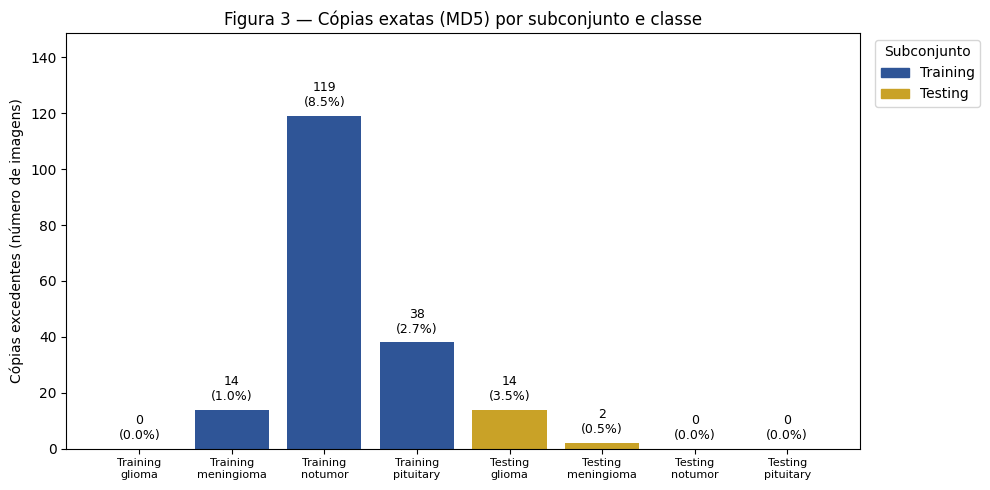

In [126]:
# Figura 3 — Cópias exatas (MD5) por subconjunto e classe
from matplotlib.patches import Patch

chaves = [(s, c) for s in SUBSETS for c in CLASSES]
total = df.groupby(['subconjunto', 'classe']).size().reindex(chaves)
exc = resumo.set_index(['subconjunto', 'classe'])['Cópias excedentes'].reindex(chaves, fill_value=0)
pct = exc / total * 100

cores = ['#2F5597' if s == 'Training' else '#C9A227' for s, c in chaves]
rotulos = [f'{s}\n{c}' for s, c in chaves]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(rotulos, exc.values, color=cores)
for i, (n, p) in enumerate(zip(exc.values, pct.values)):
    ax.text(i, n + exc.max() * 0.02, f'{n}\n({p:.1f}%)', ha='center', va='bottom', fontsize=9)

ax.set_title('Figura 3 — Cópias exatas (MD5) por subconjunto e classe')
ax.set_ylabel('Cópias excedentes (número de imagens)')
ax.set_ylim(0, exc.max() * 1.25)
ax.legend(handles=[Patch(color='#2F5597', label='Training'), Patch(color='#C9A227', label='Testing')],
          title='Subconjunto', loc='upper left', bbox_to_anchor=(1.01, 1))
plt.xticks(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(RELATORIO_DIR, 'fig03_duplicatas_md5.png'), dpi=200, bbox_inches='tight')
plt.show()

**Observação:** a busca por hash MD5 reproduz o levantamento preliminar do documento de definição: 153 grupos de imagens idênticas, envolvendo 340 imagens, ou seja, 187 cópias excedentes. Nenhum grupo atravessa Training e Testing, e nenhum reúne imagens de classes diferentes; portanto não há vazamento por cópia exata entre os subconjuntos, e os rótulos são coerentes entre as cópias. As duplicatas se concentram no Training, sobretudo no notumor (119 cópias excedentes, 8,5% da classe), seguido do pituitary (38, 2,7%) e do meningioma (14, 1,0%); o glioma do Training não tem nenhuma. No Testing há 14 cópias excedentes no glioma (3,5%) e 2 no meningioma (0,5%). Dentro do Training, as cópias dariam peso extra a certos exemplos e, numa divisão aleatória entre treino e validação, deixariam uma cópia de cada lado, o que inflaria a validação; por isso a divisão será feita por grupos de imagens semelhantes (Passo 9), e as cópias exatas ficarão sempre do mesmo lado. O MD5 não detecta o mesmo corte com recorte ou contraste diferentes, o que será examinado no Passo 7. Tabela e figura gravadas em `relatorio/tab03_duplicatas_md5.csv` e `relatorio/fig03_duplicatas_md5.png`; a lista dos arquivos duplicados está em `relatorio/lista_duplicatas_md5.csv`.

## Passo 7 — Quase-duplicatas entre Training e Testing

O MD5 só encontra cópias idênticas byte a byte. O mesmo corte de ressonância salvo com outro recorte, outra compressão ou outro contraste tem um hash completamente diferente, mas continua sendo, para a rede, a mesma imagem. Se uma imagem do Testing tem uma "gêmea" no Training, o modelo já a viu no treino, e a acurácia medida no Testing fica superestimada.

Para medir isso sem depender do arquivo, cada imagem é convertida para tons de cinza, reduzida a 48×48 pixels e normalizada (média zero e norma unitária). A similaridade entre duas imagens passa a ser a correlação de Pearson entre esses vetores: 1,0 significa imagens idênticas no padrão de intensidades, e valores próximos de 1 indicam o mesmo corte com pequenas diferenças. Para cada imagem do Testing, procuramos a imagem mais parecida no Training e registramos a correlação máxima e se as duas pertencem à mesma classe.

Os resultados são resumidos por limiar de correlação (0,999, 0,99, 0,98 e 0,95) e gravados em `relatorio/tab04_quase_duplicatas.csv`. Como não há identificação de paciente, a correlação é um substituto imperfeito: cortes diferentes do mesmo paciente podem não ser detectados, e imagens distintas muito parecidas podem ser tratadas como cópias. O levantamento preliminar do documento de definição encontrou 420 imagens do Testing (26,3%) com correlação acima de 0,999, 451 (28,2%) acima de 0,99 e 492 (30,8%) acima de 0,98; o notebook deve reproduzir esses números.

In [127]:
# Passo 7 — Quase-duplicatas: correlação de Pearson entre imagens 48x48 em tons de cinza
def vetor_48(caminho):
    with Image.open(caminho) as img:
        a = np.asarray(img.convert('L').resize((48, 48), Image.BILINEAR), dtype=np.float32).ravel()
    a = a - a.mean()                      # média zero
    n = np.linalg.norm(a)
    return a / n if n > 0 else a          # norma unitária: o produto escalar vira a correlação

tr = df[df['subconjunto'] == 'Training'].reset_index(drop=True)
te = df[df['subconjunto'] == 'Testing'].reset_index(drop=True)

X_tr = np.stack([vetor_48(c) for c in tr['caminho']])
X_te = np.stack([vetor_48(c) for c in te['caminho']])
print('Matrizes de vetores:', X_tr.shape, X_te.shape)

# Testing x Training: para cada imagem do Testing, a mais parecida do Training
C = X_te @ X_tr.T
melhor = C.argmax(axis=1)
te['corr_max'] = C.max(axis=1)
te['vizinho_caminho'] = tr['caminho'].values[melhor]
te['classe_vizinho'] = tr['classe'].values[melhor]
te['mesma_classe'] = te['classe'] == te['classe_vizinho']

# Visto do lado do Training: quantas imagens têm gêmea no Testing
tr['corr_max_testing'] = C.max(axis=0)

# Resumo por limiar de correlação
linhas = []
for t in [0.999, 0.99, 0.98, 0.95]:
    m = te['corr_max'] > t
    linhas.append({'Correlação maior que': t,
                   'Imagens do Testing com vizinho no Training': int(m.sum()),
                   '% das 1.600 imagens': round(100 * m.mean(), 1),
                   'Vizinho da mesma classe': int((m & te['mesma_classe']).sum())})
tab04 = pd.DataFrame(linhas)
print()
print(tab04.to_string(index=False))

# Dentro do Training: imagens com outra imagem muito parecida
C2 = X_tr @ X_tr.T
np.fill_diagonal(C2, -1)
tr['corr_max_training'] = C2.max(axis=1)
del C2
n_in = int((tr['corr_max_training'] > 0.99).sum())
n_out = int((tr['corr_max_testing'] > 0.99).sum())
print()
print(f'Training com outra imagem do Training (corr > 0,99): {n_in} de {len(tr)} ({100*n_in/len(tr):.1f}%)')
print(f'Training com imagem do Testing (corr > 0,99)       : {n_out} de {len(tr)} ({100*n_out/len(tr):.1f}%)')

tab04.to_csv(os.path.join(RELATORIO_DIR, 'tab04_quase_duplicatas.csv'), index=False)

Matrizes de vetores: (5600, 2304) (1600, 2304)

 Correlação maior que  Imagens do Testing com vizinho no Training  % das 1.600 imagens  Vizinho da mesma classe
                0.999                                         420                 26.2                      418
                0.990                                         451                 28.2                      449
                0.980                                         492                 30.8                      490
                0.950                                         802                 50.1                      798

Training com outra imagem do Training (corr > 0,99): 1170 de 5600 (20.9%)
Training com imagem do Testing (corr > 0,99)       : 733 de 5600 (13.1%)


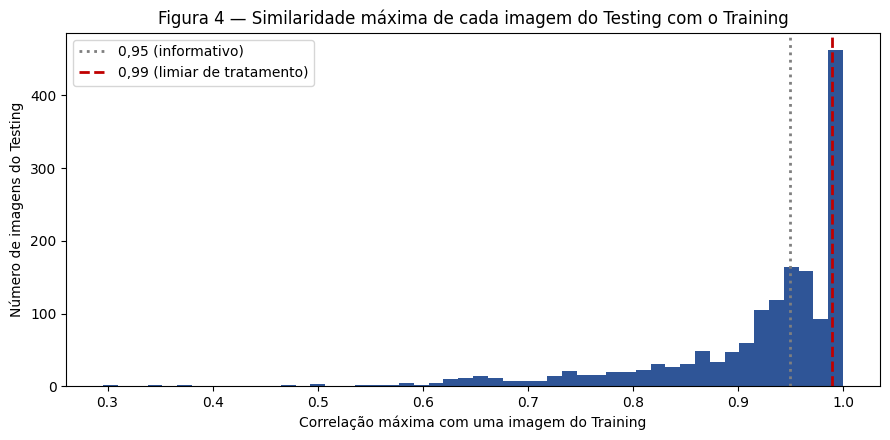

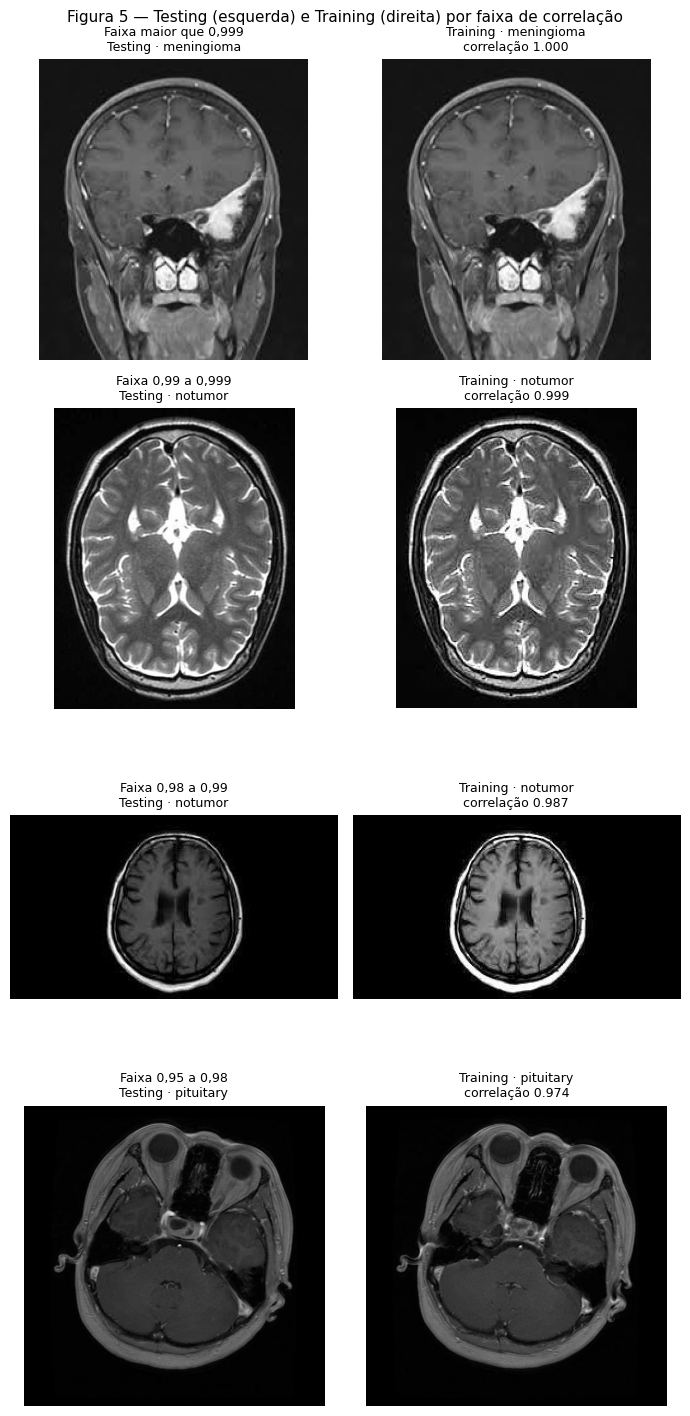

In [128]:
# Figuras 4 e 5 — Quase-duplicatas entre Testing e Training
rng = np.random.default_rng(SEED)

# Figura 4 — distribuição da correlação máxima (Testing x Training)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(te['corr_max'], bins=50, color='#2F5597')
ax.axvline(0.95, color='#7F7F7F', linestyle=':', linewidth=2, label='0,95 (informativo)')
ax.axvline(0.99, color='#C00000', linestyle='--', linewidth=2, label='0,99 (limiar de tratamento)')
ax.set_title('Figura 4 — Similaridade máxima de cada imagem do Testing com o Training')
ax.set_xlabel('Correlação máxima com uma imagem do Training')
ax.set_ylabel('Número de imagens do Testing')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(RELATORIO_DIR, 'fig04_distribuicao_correlacao.png'), dpi=200)
plt.show()

# Figura 5 — um par sorteado em cada faixa de correlação
faixas = [('maior que 0,999', 0.999, 1.1),
          ('0,99 a 0,999', 0.99, 0.999),
          ('0,98 a 0,99', 0.98, 0.99),
          ('0,95 a 0,98', 0.95, 0.98)]
fig, eixos = plt.subplots(len(faixas), 2, figsize=(7, 3.6 * len(faixas)))
for linha, (nome, lo, hi) in enumerate(faixas):
    cand = te[(te['corr_max'] > lo) & (te['corr_max'] <= hi)]
    if len(cand) == 0:
        eixos[linha, 0].axis('off'); eixos[linha, 1].axis('off')
        continue
    r = cand.iloc[int(rng.integers(len(cand)))]
    eixos[linha, 0].imshow(Image.open(r['caminho']).convert('L'), cmap='gray')
    eixos[linha, 0].set_title(f"Faixa {nome}\nTesting · {r['classe']}", fontsize=9)
    eixos[linha, 1].imshow(Image.open(r['vizinho_caminho']).convert('L'), cmap='gray')
    eixos[linha, 1].set_title(f"Training · {r['classe_vizinho']}\ncorrelação {r['corr_max']:.3f}", fontsize=9)
    eixos[linha, 0].axis('off'); eixos[linha, 1].axis('off')
fig.suptitle('Figura 5 — Testing (esquerda) e Training (direita) por faixa de correlação', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(RELATORIO_DIR, 'fig05_pares_quase_duplicatas.png'), dpi=200, bbox_inches='tight')
plt.show()

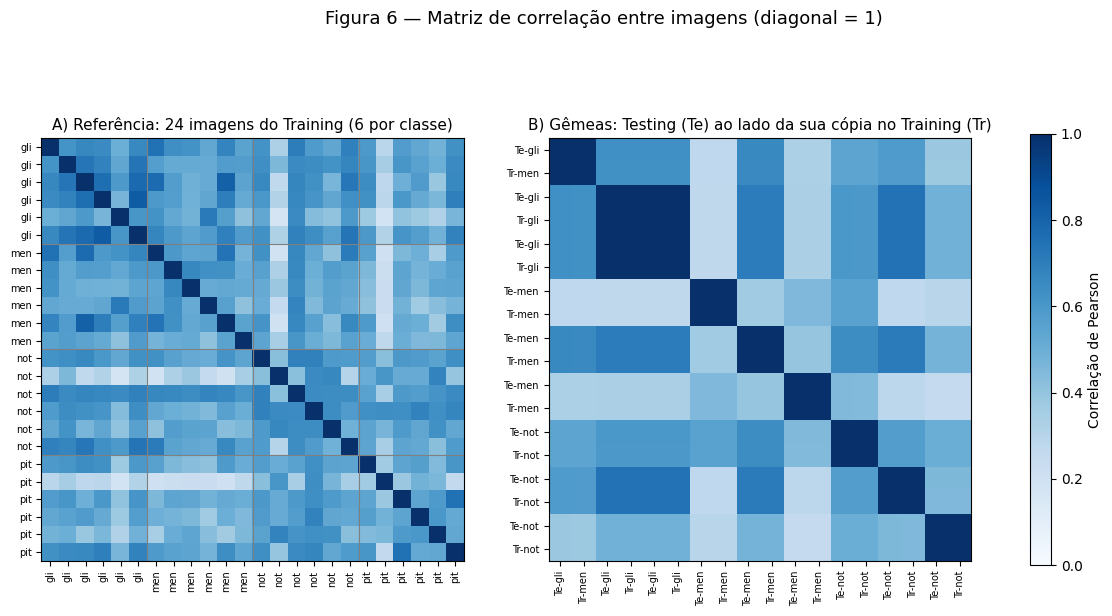

Painel A — correlação média fora da diagonal: 0.537 | máxima: 0.830
Painel B — correlação dos pares Testing×Training: mín 1.000 | média 1.000


In [129]:
# Figura 6 — Matriz de correlação: amostra de referência (A) e pares Testing×Training (B)
rng = np.random.default_rng(SEED)

# Painel A: 6 imagens do Training por classe, ordenadas por classe
idx_a = []
for c in CLASSES:
    pos = np.where(tr['classe'].values == c)[0]
    idx_a += list(rng.choice(pos, 6, replace=False))
V_a = X_tr[idx_a]
M_a = V_a @ V_a.T                      # vetores normalizados: produto escalar = Pearson
rot_a = [tr['classe'].iloc[i][:3] for i in idx_a]

# Painel B: 3 imagens do Testing por classe com corr_max > 0,99, cada uma seguida da sua gêmea do Training
pares = []
for c in CLASSES:
    cand = te.index[(te['classe'] == c) & (te['corr_max'] > 0.99)].values
    pares += list(rng.choice(cand, min(3, len(cand)), replace=False))
V_b, rot_b = [], []
for i in pares:
    V_b += [X_te[i], X_tr[melhor[i]]]
    rot_b += ['Te-' + te['classe'].iloc[i][:3], 'Tr-' + tr['classe'].iloc[melhor[i]][:3]]
V_b = np.stack(V_b)
M_b = V_b @ V_b.T

fig, eixos = plt.subplots(1, 2, figsize=(15, 7))
paineis = [(M_a, rot_a, 'A) Referência: 24 imagens do Training (6 por classe)'),
           (M_b, rot_b, 'B) Gêmeas: Testing (Te) ao lado da sua cópia no Training (Tr)')]
for ax, (M, rot, titulo) in zip(eixos, paineis):
    im = ax.imshow(M, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(rot)))
    ax.set_yticks(range(len(rot)))
    ax.set_xticklabels(rot, rotation=90, fontsize=7)
    ax.set_yticklabels(rot, fontsize=7)
    ax.set_title(titulo, fontsize=11)
# separadores de classe no painel A (a cada 6 imagens)
for k in range(6, 24, 6):
    eixos[0].axhline(k - 0.5, color='gray', lw=0.8)
    eixos[0].axvline(k - 0.5, color='gray', lw=0.8)
fig.colorbar(im, ax=eixos, shrink=0.8, label='Correlação de Pearson')
fig.suptitle('Figura 6 — Matriz de correlação entre imagens (diagonal = 1)', fontsize=13)
fig.savefig(f'{RELATORIO_DIR}/fig06_matriz_correlacao.png', dpi=200, bbox_inches='tight')
plt.show()

# Números para a Observação
fora_a = M_a[~np.eye(len(M_a), dtype=bool)]
print(f'Painel A — correlação média fora da diagonal: {fora_a.mean():.3f} | máxima: {fora_a.max():.3f}')
corr_pares = [M_b[2*k, 2*k + 1] for k in range(len(pares))]
print(f'Painel B — correlação dos pares Testing×Training: mín {min(corr_pares):.3f} | média {np.mean(corr_pares):.3f}')

Entre as 451 imagens do Testing com gêmea acima de 0,99 no Training, 449 (99,6%) têm o mesmo rótulo da gêmea e 2 têm rótulo divergente (glioma no Testing e meningioma no Training), indício de ruído de rotulagem no próprio conjunto; as gêmeas concentram-se em notumor (340) e meningioma (104), com 7 em glioma e nenhuma em pituitary.

In [130]:
# Conferência: as gêmeas do Testing (corr > 0,99) têm o mesmo rótulo no Training?
gemeas = te[te['corr_max'] > 0.99]
print(gemeas['mesma_classe'].value_counts())
print()
print(pd.crosstab(gemeas['classe'], gemeas['classe_vizinho'],
                  rownames=['classe no Testing'], colnames=['classe da gêmea no Training']))


mesma_classe
True     449
False      2
Name: count, dtype: int64

classe da gêmea no Training  glioma  meningioma  notumor
classe no Testing                                       
glioma                            5           2        0
meningioma                        0         104        0
notumor                           0           0      340


**Observação:** a medição por correlação reproduz o levantamento preliminar do documento de definição. Das 1.600 imagens do Testing, 420 (26,3%) têm no Training uma imagem com correlação superior a 0,999, 451 (28,2%) superior a 0,99, 492 (30,8%) superior a 0,98 e 802 (50,1%) superior a 0,95. Mais de um quarto do Testing, portanto, não é inédito para o modelo, o que tende a superestimar a acurácia medida nele; a Figura 4 mostra essa concentração de imagens nas correlações mais altas, à direita do limiar de 0,99. No sentido inverso, 733 das 5.600 imagens do Training (13,1%) têm uma imagem muito parecida (correlação acima de 0,99) no Testing, número maior que 451 porque uma mesma imagem do Testing pode ter várias parecidas no Training. Dentro do próprio Training, 1.170 imagens (20,9%) têm outra imagem com correlação acima de 0,99, de modo que uma divisão aleatória entre treino e validação também deixaria cópias dos dois lados. Na Figura 5, o par sorteado na faixa de 0,98 a 0,99 (notumor, correlação 0,987) mostra o mesmo corte com enquadramento ligeiramente diferente, e não uma cópia idêntica. O limiar de 0,95 inclui cortes apenas semelhantes e, por isso, não é tratado como duplicidade. Como não há identificação de paciente, a correlação é um substituto imperfeito: pode deixar passar cortes diferentes do mesmo paciente e pode tratar imagens distintas muito parecidas como cópias. O tratamento proposto será aplicado no Passo 8, removendo do Training as imagens com correlação superior a 0,99 com alguma imagem do Testing, e no Passo 9, com a divisão entre treino e validação por grupos de imagens semelhantes. Tabela e figuras gravadas em `relatorio/tab04_quase_duplicatas.csv`, `relatorio/fig04_distribuicao_correlacao.png` e `relatorio/fig05_pares_quase_duplicatas.png`.

## Passo 8 — Tratamento da sobreposição: remoção, do Training, das imagens com gêmea no Testing

O Passo 7 mostrou que parte do Testing já aparece no Training, o que faria a acurácia final parecer melhor do que a capacidade real do modelo de reconhecer imagens inéditas. Para corrigir isso, este passo remove do Training toda imagem cuja correlação com alguma imagem do Testing seja superior a 0,99. A escolha foi retirar as cópias do Training, e não do Testing, por dois motivos: o Testing publicado permanece intacto, com 1.600 imagens, o que mantém os resultados comparáveis a outros trabalhos com o mesmo dataset; e as imagens removidas são cópias, de modo que o Training perde pouca informação nova. O custo é um Training menor.

O código separa as imagens a manter e as removidas, monta uma tabela por classe com as contagens antes e depois da limpeza, salva a tabela e a lista das imagens removidas em `relatorio/`, e faz uma verificação final: recalcula a maior correlação entre o Training limpo e o Testing, que deve ficar abaixo do limiar. As variáveis `tr_limpo` e `X_tr_limpo` guardam o Training limpo para os próximos passos.

In [131]:
# Passo 8 — Remoção, do Training, das imagens com gêmea no Testing (correlação > 0,99)
LIMIAR = 0.99
manter = (tr['corr_max_testing'] <= LIMIAR).values
tr_limpo = tr[manter].reset_index(drop=True)
X_tr_limpo = X_tr[manter]
removidas = tr[~manter]

# Tabela por classe: antes, removidas, depois
antes = tr['classe'].value_counts().reindex(CLASSES)
rem = removidas['classe'].value_counts().reindex(CLASSES).fillna(0).astype(int)
depois = tr_limpo['classe'].value_counts().reindex(CLASSES)
tab05 = pd.DataFrame({'Training original': antes,
                      'Removidas': rem,
                      'Training após limpeza': depois})
tab05['% removido'] = (100 * tab05['Removidas'] / tab05['Training original']).round(1)
tab05.loc['Total'] = [antes.sum(), rem.sum(), depois.sum(),
                      round(100 * rem.sum() / antes.sum(), 1)]
display(tab05)

# Verificação: nenhuma imagem do Training limpo pode ter correlação > limiar com o Testing
maior = (X_te @ X_tr_limpo.T).max()
print(f'\nMaior correlação Testing x Training limpo: {maior:.4f} (limiar {LIMIAR})')
print(f'Testing intacto: {len(te)} imagens')

# Salvar tabela e lista das imagens removidas
tab05.to_csv(f'{RELATORIO_DIR}/tab05_remocao_training.csv')
removidas[['classe', 'arquivo', 'caminho', 'corr_max_testing']].to_csv(
    f'{RELATORIO_DIR}/lista_removidas_training.csv', index=False)

,Training original,Removidas,Training após limpeza,% removido
classe,,,,
glioma,1400.0,4.0,1396.0,0.3
meningioma,1400.0,106.0,1294.0,7.6
notumor,1400.0,623.0,777.0,44.5
pituitary,1400.0,0.0,1400.0,0.0
Total,5600.0,733.0,4867.0,13.1



Maior correlação Testing x Training limpo: 0.9899 (limiar 0.99)
Testing intacto: 1600 imagens


**Figura 7 — Imagens mantidas e removidas do Training, por classe.** Cada barra representa as 1.400 imagens originais de uma classe no Training; a parte azul-escura é o que permanece após a limpeza e a parte azul-clara, no topo, é o que foi removido por ter uma gêmea (correlação superior a 0,99) no Testing. O texto acima de cada barra indica o número e a porcentagem removidos.

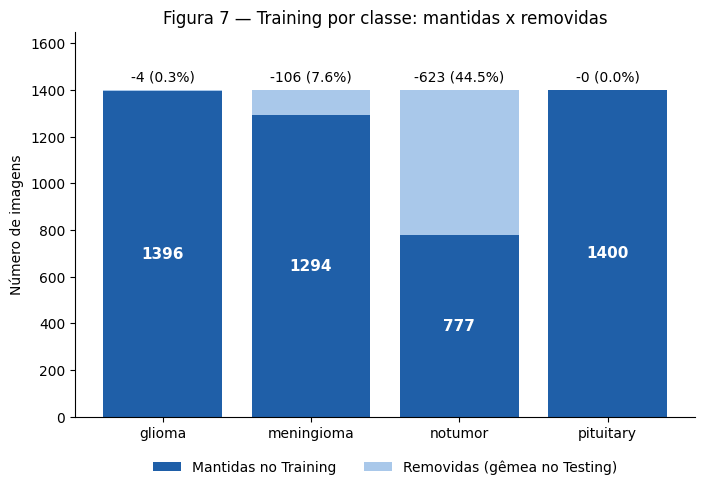

In [132]:
# Figura 7 — Training por classe: mantidas x removidas
mantidas = tab05.loc[CLASSES, 'Training após limpeza'].astype(int).values
removid = tab05.loc[CLASSES, 'Removidas'].astype(int).values
pct = tab05.loc[CLASSES, '% removido'].values
x = np.arange(len(CLASSES))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x, mantidas, color='#1f5fa8', label='Mantidas no Training')
ax.bar(x, removid, bottom=mantidas, color='#a9c8ea', label='Removidas (gêmea no Testing)')
for i in range(len(CLASSES)):
    ax.text(x[i], mantidas[i] / 2, f'{mantidas[i]}', ha='center', va='center',
            color='white', fontsize=11, fontweight='bold')
    ax.text(x[i], mantidas[i] + removid[i] + 25, f'-{removid[i]} ({pct[i]:.1f}%)',
            ha='center', va='bottom', fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(CLASSES)
ax.set_ylabel('Número de imagens')
ax.set_ylim(0, 1650)
ax.set_title('Figura 7 — Training por classe: mantidas x removidas', fontsize=12)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.savefig(f'{RELATORIO_DIR}/fig07_remocao_training.png', dpi=200, bbox_inches='tight')
plt.show()

## Passo 9 — Divisão treino/validação (80/20) por grupos de imagens semelhantes

O conjunto de validação serve para acompanhar o aprendizado durante o treino e escolher o número de épocas, por isso precisa conter imagens que a rede não viu. Se a divisão fosse sorteada imagem a imagem, cópias e quase-cópias do próprio Training (1.170 imagens com gêmea interna, Passo 7) ficariam dos dois lados, e a acurácia de validação sairia inflada, escondendo o momento em que a rede passa a decorar. Para evitar isso, as imagens do Training limpo são agrupadas por semelhança: duas imagens com correlação superior a 0,98 pertencem ao mesmo grupo, e os grupos são formados pelos componentes conexos desse critério (se A é parecida com B e B com C, as três ficam juntas). A divisão 80/20 é então feita por grupos, de modo que um grupo inteiro vai para o treino ou para a validação, mantendo aproximadamente a proporção de cada classe, com semente fixa (42) para reprodutibilidade. A proporção 80/20 é uma convenção amplamente utilizada que equilibra dados para o aprendizado e confiabilidade da estimativa de validação.

O código forma os grupos e descreve seus tamanhos, faz a divisão, apresenta a tabela por classe, verifica que nenhum grupo aparece nos dois lados e compara com o que ocorreria num sorteio aleatório simples. Não há identificação de paciente no dataset, de modo que a correlação continua sendo um substituto imperfeito: imagens diferentes do mesmo paciente podem não ser agrupadas.

In [133]:
# Passo 9 — Divisão treino/validação (80/20) por grupos de imagens semelhantes
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

LIMIAR_GRUPO = 0.98

# 1) Grupos: componentes conexos do critério "correlação > limiar"
C_tr = X_tr_limpo @ X_tr_limpo.T
n_grupos, rotulo_grupo = connected_components(csr_matrix(C_tr > LIMIAR_GRUPO), directed=False)
tr_limpo['grupo'] = rotulo_grupo

tam = tr_limpo.groupby('grupo').size()
print(f'Grupos formados: {n_grupos} (para {len(tr_limpo)} imagens)')
print(f'Grupos com 1 imagem: {(tam == 1).sum()} | com 2: {(tam == 2).sum()} | '
      f'com 3 a 5: {((tam >= 3) & (tam <= 5)).sum()} | com mais de 5: {(tam > 5).sum()}')
print(f'Maior grupo: {tam.max()} imagens')
misto = (tr_limpo.groupby('grupo')['classe'].nunique() > 1).sum()
print(f'Grupos com mais de uma classe: {misto}')

# 2) Divisão 80/20 por grupos, estratificada por classe (1 fold de 5 = 20%)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_tr, idx_val = next(sgkf.split(np.zeros(len(tr_limpo)), tr_limpo['classe'], tr_limpo['grupo']))
tr_limpo['particao'] = 'treino'
tr_limpo.loc[idx_val, 'particao'] = 'validacao'

# 3) Tabela por classe
tab06 = pd.crosstab(tr_limpo['classe'], tr_limpo['particao']).reindex(CLASSES)[['treino', 'validacao']]
tab06['total'] = tab06['treino'] + tab06['validacao']
tab06['% validação'] = (100 * tab06['validacao'] / tab06['total']).round(1)
tab06.loc['Total'] = [tab06['treino'].sum(), tab06['validacao'].sum(), tab06['total'].sum(),
                      round(100 * tab06['validacao'].sum() / tab06['total'].sum(), 1)]
display(tab06)

# 4) Verificações
g_tr, g_val = set(tr_limpo.loc[idx_tr, 'grupo']), set(tr_limpo.loc[idx_val, 'grupo'])
print(f'\nGrupos em comum entre treino e validação: {len(g_tr & g_val)}')
print(f'Maior correlação validação x treino (divisão por grupos): {C_tr[np.ix_(idx_val, idx_tr)].max():.4f}')

# 5) Comparação: o que um sorteio aleatório simples 80/20 faria
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(tr_limpo))
val_a, tr_a = perm[:len(idx_val)], perm[len(idx_val):]
frac = (C_tr[np.ix_(val_a, tr_a)].max(axis=1) > LIMIAR_GRUPO).mean()
print(f'Num sorteio aleatório, {100 * frac:.1f}% das imagens de validação teriam gêmea '
      f'(correlação > {LIMIAR_GRUPO}) no treino')

# 6) Salvar
tab06.to_csv(f'{RELATORIO_DIR}/tab06_divisao_treino_validacao.csv')
tr_limpo[['classe', 'arquivo', 'caminho', 'grupo', 'particao']].to_csv(
    f'{RELATORIO_DIR}/particao_treino_validacao.csv', index=False)

Grupos formados: 4415 (para 4867 imagens)
Grupos com 1 imagem: 4168 | com 2: 158 | com 3 a 5: 75 | com mais de 5: 14
Maior grupo: 14 imagens
Grupos com mais de uma classe: 0


particao,treino,validacao,total,% validação
classe,,,,
glioma,1120.0,276.0,1396.0,19.8
meningioma,1036.0,258.0,1294.0,19.9
notumor,629.0,148.0,777.0,19.0
pituitary,1124.0,276.0,1400.0,19.7
Total,3909.0,958.0,4867.0,19.7



Grupos em comum entre treino e validação: 0
Maior correlação validação x treino (divisão por grupos): 0.9798
Num sorteio aleatório, 14.1% das imagens de validação teriam gêmea (correlação > 0.98) no treino


**Observação:** as 4.867 imagens do Training limpo formaram 4.415 grupos: 4.168 com uma só imagem, 158 com duas, 75 com três a cinco e 14 com mais de cinco, sendo o maior de 14 imagens; não houve, portanto, formação de um grupo gigante por encadeamento de semelhanças, e nenhum grupo reúne imagens de classes diferentes. A divisão por grupos resultou em 3.909 imagens de treino e 958 de validação (19,7%), com a validação entre 19,0% e 19,9% em cada classe (glioma 276, meningioma 258, notumor 148 e pituitary 276); a proporção ficou ligeiramente abaixo de 20% porque grupos inteiros precisam ficar do mesmo lado. Nenhum grupo aparece nos dois conjuntos e a maior correlação entre uma imagem de validação e uma de treino é 0,9798, abaixo do limiar de 0,98. Num sorteio aleatório simples 80/20, 14,1% das imagens de validação teriam uma gêmea no treino, o que inflaria a acurácia de validação (Figura 8B); com a divisão por grupos esse vazamento é nulo pelo critério adotado. Com isso, os três conjuntos ficam definidos: treino (3.909), validação (958) e teste (1.600, o Testing publicado e intacto). Persistem duas limitações: a correlação é um substituto imperfeito da identificação de paciente, que o dataset não fornece, e a classe notumor tem a menor validação (148 imagens), de modo que a estimativa de desempenho nela é a menos estável. Tabela e partição gravadas em `relatorio/tab06_divisao_treino_validacao.csv` e `relatorio/particao_treino_validacao.csv`, e figura em `relatorio/fig08_divisao_treino_validacao.png`.

**Figura 8 — Divisão treino/validação por grupos.** O Painel A mostra, para cada classe, quantas imagens foram para o treino (azul-escuro) e para a validação (azul-claro). O Painel B compara o vazamento entre os dois conjuntos: a porcentagem das imagens de validação que teriam uma gêmea (correlação superior a 0,98) no treino se a divisão fosse um sorteio aleatório simples, contra a divisão por grupos adotada.

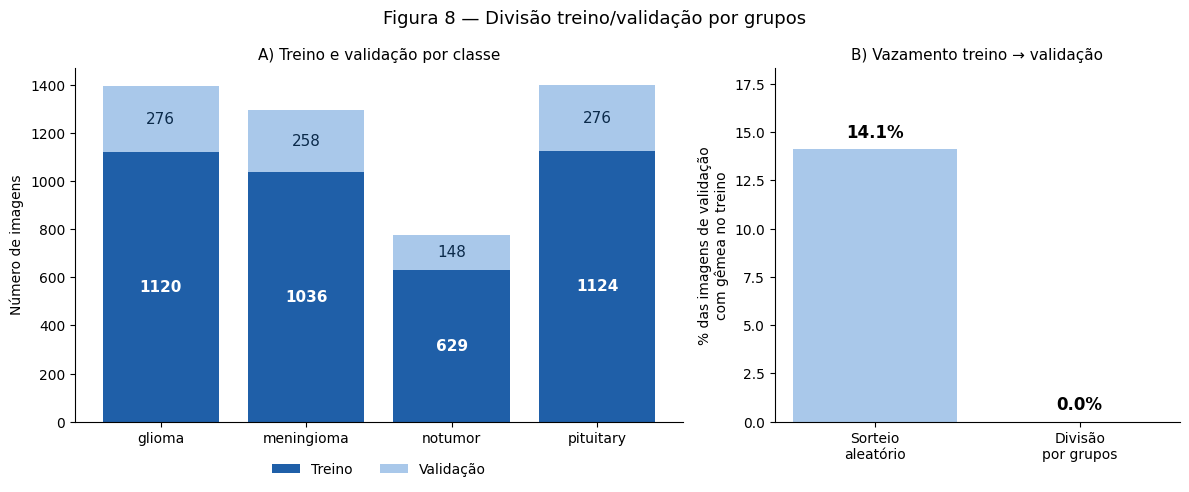

In [134]:
# Figura 8 — Divisão treino/validação por classe e comparação do vazamento
ntr = tab06.loc[CLASSES, 'treino'].astype(int).values
nva = tab06.loc[CLASSES, 'validacao'].astype(int).values
x = np.arange(len(CLASSES))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [3, 2]})

# Painel A: treino e validação por classe
ax1.bar(x, ntr, color='#1f5fa8', label='Treino')
ax1.bar(x, nva, bottom=ntr, color='#a9c8ea', label='Validação')
for i in range(len(CLASSES)):
    ax1.text(x[i], ntr[i] / 2, f'{ntr[i]}', ha='center', va='center',
             color='white', fontsize=11, fontweight='bold')
    ax1.text(x[i], ntr[i] + nva[i] / 2, f'{nva[i]}', ha='center', va='center',
             color='#0b2a4a', fontsize=11)
ax1.set_xticks(x)
ax1.set_xticklabels(CLASSES)
ax1.set_ylabel('Número de imagens')
ax1.set_title('A) Treino e validação por classe', fontsize=11)
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
ax1.spines[['top', 'right']].set_visible(False)

# Painel B: vazamento (imagens de validação com gêmea no treino)
valores = [100 * frac, 0.0]
ax2.bar(['Sorteio\naleatório', 'Divisão\npor grupos'], valores, color=['#a9c8ea', '#1f5fa8'])
for i, v in enumerate(valores):
    ax2.text(i, v + 0.4, f'{v:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax2.set_ylim(0, max(valores) * 1.3)
ax2.set_ylabel('% das imagens de validação\ncom gêmea no treino')
ax2.set_title('B) Vazamento treino → validação', fontsize=11)
ax2.spines[['top', 'right']].set_visible(False)

fig.suptitle('Figura 8 — Divisão treino/validação por grupos', fontsize=13)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig08_divisao_treino_validacao.png', dpi=200, bbox_inches='tight')
plt.show()

## Passo 10 — Padronização das imagens: 128×128 em tons de cinza

A rede neural recebe sempre entradas do mesmo tamanho, mas as imagens do dataset têm dimensões e modos de cor variados (Passo 5). Este passo as converte para uma grade única de 128×128 pixels em tons de cinza, valor definido no documento de projeto. O tamanho é um compromisso: imagens maiores preservam mais detalhe, o que ajuda a ver tumores pequenos, mas exigem mais memória e tempo de treino; em 128×128 parte do detalhe se perde, o que será registrado como limitação.

Antes de converter, é preciso decidir como tratar as imagens que não são quadradas: redimensioná-las diretamente (simples, mas achata a imagem) ou acrescentar bordas pretas até ficarem quadradas e só então reduzir (preserva as proporções, mas o fundo preto passa a ter tamanhos diferentes). A decisão depende de quantas imagens não são quadradas e do quanto se afastam do quadrado, por isso a primeira etapa apenas mede o formato de todas as imagens, por classe, sem alterar nada.

In [135]:
# Passo 10 (parte 1) — Formato das imagens: quão longe do quadrado elas estão?
df['razao'] = df['largura'] / df['altura']          # 1,00 = quadrada
df['formato'] = pd.cut(df['razao'],
                       bins=[0, 0.90, 0.99, 1.01, 1.10, 10],
                       labels=['bem mais alta (<0,90)', 'um pouco mais alta',
                               'quadrada (±1%)', 'um pouco mais larga', 'bem mais larga (>1,10)'])

print(f"Razão largura/altura: mínima {df['razao'].min():.2f} | mediana {df['razao'].median():.2f} | máxima {df['razao'].max():.2f}")
print(f"Imagens exatamente quadradas: {(df['razao'] == 1).sum()} de {len(df)} ({100 * (df['razao'] == 1).mean():.1f}%)\n")

display(pd.crosstab(df['classe'], df['formato'], margins=True))

Razão largura/altura: mínima 0.64 | mediana 1.00 | máxima 1.79
Imagens exatamente quadradas: 5667 de 7200 (78.7%)



formato,"bem mais alta (<0,90)",um pouco mais alta,quadrada (±1%),um pouco mais larga,"bem mais larga (>1,10)",All
classe,,,,,,
glioma,31,16,1738,9,6,1800
meningioma,99,61,1593,29,18,1800
notumor,580,222,620,276,102,1800
pituitary,5,6,1768,18,3,1800
All,715,305,5719,332,129,7200


**Observação:** das 7.200 imagens, 5.719 (79,4%) são quadradas (razão largura/altura dentro de ±1%) e 1.481 (20,6%) não são. A falta de quadratura está muito concentrada em uma classe: 1.180 das 1.800 imagens de notumor (65,6%) fogem do quadrado, contra 207 de meningioma (11,5%), 62 de glioma (3,4%) e 32 de pituitary (1,8%). A maior parte das imagens fora do quadrado é mais alta que larga: 715 têm razão inferior a 0,90, das quais 580 são notumor. Isso reforça o achado do Passo 5 de que características técnicas do arquivo se associam à classe: o formato da imagem, por si só, já traz uma pista sobre o rótulo, e a forma como as imagens não quadradas forem tratadas pode transmitir essa pista à rede. O fato será registrado como limitação e verificado na avaliação final, comparando o desempenho nas imagens quadradas e nas não quadradas.

**Conversão das imagens (Passo 10, parte 2).** Seguindo a opção escolhida para as imagens não quadradas, cada imagem passa pelas seguintes etapas: conversão para tons de cinza (o que também uniformiza os modos de cor do Passo 5); acréscimo de bordas pretas, de modo centralizado, até a imagem ficar quadrada, sem distorcer a anatomia nem descartar pixels; e redução para 128×128 pixels pelo método de Lanczos, que preserva bem os detalhes na redução. Os pixels ficam guardados como inteiros de 0 a 255; a divisão por 255 será feita dentro da própria rede, na primeira camada (Rescaling), como previsto no desenho da CNN.

A conversão é aplicada apenas às imagens que permaneceram nos três conjuntos definidos nos passos anteriores: treino (3.909) e validação (958), vindos do Training limpo, e teste (1.600), o Testing publicado. As 733 imagens removidas no Passo 8 não são convertidas. Os rótulos são guardados como números inteiros de 0 a 3, na ordem glioma, meningioma, notumor e pituitary. Nenhuma transformação aleatória (data augmentation) é feita aqui: ela só será aplicada ao treino, na Fase 4.

In [136]:
# Passo 10 (parte 2) — Conversão: tons de cinza + bordas pretas até ficar quadrada + redução para 128x128
TAM = 128

def preparar(caminho):
    with Image.open(caminho) as img:
        img = img.convert('L')                                  # tons de cinza
        w, h = img.size
        lado = max(w, h)
        quadrada = Image.new('L', (lado, lado), 0)              # fundo preto
        quadrada.paste(img, ((lado - w) // 2, (lado - h) // 2)) # imagem centralizada
        return np.asarray(quadrada.resize((TAM, TAM), Image.LANCZOS), dtype=np.uint8)

mapa = {c: i for i, c in enumerate(CLASSES)}                    # glioma=0, meningioma=1, notumor=2, pituitary=3
conjuntos = {
    'treino':    tr_limpo[tr_limpo['particao'] == 'treino'],
    'validacao': tr_limpo[tr_limpo['particao'] == 'validacao'],
    'teste':     te,
}

X, y = {}, {}
for nome, d in conjuntos.items():
    X[nome] = np.stack([preparar(c) for c in d['caminho']])[..., np.newaxis]   # (n, 128, 128, 1)
    y[nome] = d['classe'].map(mapa).values.astype(np.int64)

# Conferência dos formatos e das contagens por classe
for nome in X:
    print(f"{nome:10s} X{X[nome].shape} {X[nome].dtype} | pixels de {X[nome].min()} a {X[nome].max()}")

tab07 = pd.DataFrame({nome: np.bincount(y[nome], minlength=4) for nome in X}, index=CLASSES)
tab07.loc['Total'] = tab07.sum()
display(tab07)
tab07.to_csv(f'{RELATORIO_DIR}/tab07_conjuntos_finais.csv')

treino     X(3909, 128, 128, 1) uint8 | pixels de 0 a 255
validacao  X(958, 128, 128, 1) uint8 | pixels de 0 a 255
teste      X(1600, 128, 128, 1) uint8 | pixels de 0 a 255


,treino,validacao,teste
glioma,1120,276,400
meningioma,1036,258,400
notumor,629,148,400
pituitary,1124,276,400
Total,3909,958,1600


**Figura 9 — Antes e depois da padronização.** A linha de cima mostra uma imagem original de cada classe, escolhida entre as que mais fogem do quadrado, com suas dimensões e a razão largura/altura; a linha de baixo mostra o resultado em 128×128 pixels, em tons de cinza e com bordas pretas acrescentadas onde foi preciso.

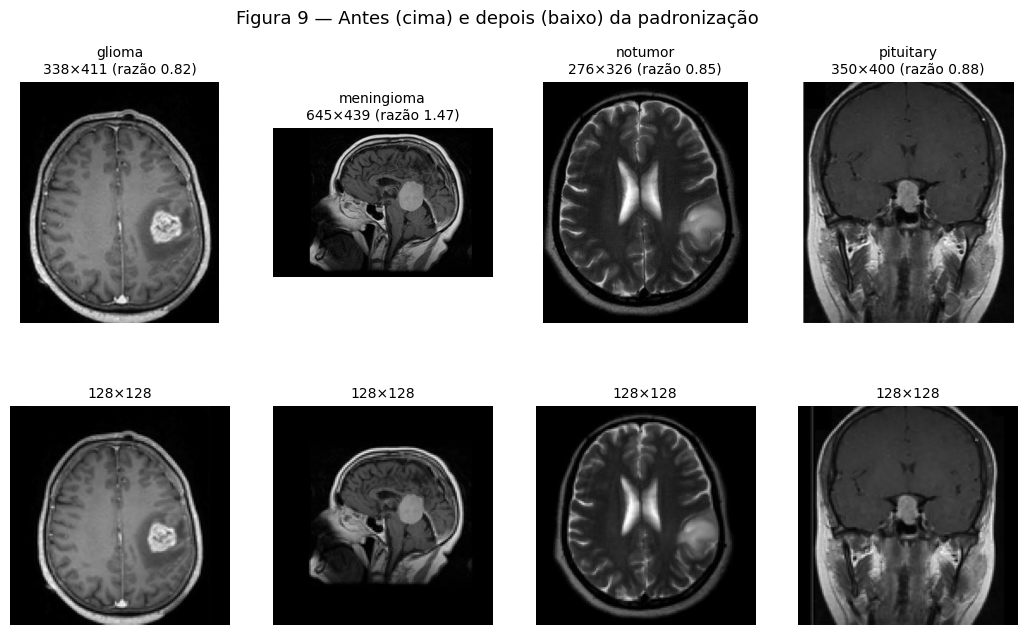

In [137]:
# Figura 9 — Antes e depois da padronização (uma imagem não quadrada por classe)
rng = np.random.default_rng(SEED)
fig, eixos = plt.subplots(2, 4, figsize=(13, 7.2))
for j, c in enumerate(CLASSES):
    cand = df[(df['classe'] == c) & ((df['razao'] - 1).abs() > 0.10)]
    if len(cand) == 0:
        cand = df[(df['classe'] == c) & ((df['razao'] - 1).abs() > 0.01)]
    linha = cand.iloc[rng.integers(len(cand))]
    with Image.open(linha['caminho']) as img:
        original = img.convert('L')
    eixos[0, j].imshow(original, cmap='gray', vmin=0, vmax=255)
    eixos[0, j].set_title(f"{c}\n{linha['largura']}×{linha['altura']} (razão {linha['razao']:.2f})", fontsize=10)
    eixos[1, j].imshow(preparar(linha['caminho']), cmap='gray', vmin=0, vmax=255)
    eixos[1, j].set_title(f'{TAM}×{TAM}', fontsize=10)
for ax in eixos.ravel():
    ax.axis('off')
fig.suptitle('Figura 9 — Antes (cima) e depois (baixo) da padronização', fontsize=13)
fig.subplots_adjust(hspace=0.3)
fig.savefig(f'{RELATORIO_DIR}/fig09_padronizacao.png', dpi=200, bbox_inches='tight')
plt.show()

# Fase 3 — Desenvolvimento da rede neural convolucional

Com os conjuntos de treino (3.909 imagens), validação (958) e teste (1.600) definidos e padronizados em 128×128 pixels, esta fase constrói a rede que aprenderá a distinguir as quatro classes. A escolha de uma rede convolucional (CNN) para imagens tem uma razão prática. Uma rede densa comum ligaria cada um dos 16.384 pixels de uma imagem a cada neurônio da primeira camada: com apenas 128 neurônios, seriam 2.097.280 pesos só nessa camada, e a rede trataria cada pixel como se fosse independente de seus vizinhos, quando o significado de um pixel depende do que o cerca. Além disso, um tumor deslocado alguns pixels seria um padrão novo para ela.

A CNN resolve esses problemas com filtros: pequenas janelas de 3×3 pixels que deslizam por toda a imagem em busca de um padrão específico, como uma borda ou uma mancha clara. O mesmo filtro é reutilizado em todas as posições, de modo que o padrão é encontrado onde quer que esteja e o número de pesos é pequeno. As primeiras camadas detectam elementos simples (bordas, contrastes), as seguintes os combinam em formas (contornos, texturas) e as últimas em estruturas mais complexas, de maneira análoga a um radiologista que primeiro percebe contrastes, depois formas e, por fim, o conjunto. Entre as camadas de filtros, uma operação de pooling reduz a imagem preservando as respostas mais fortes de cada região, e uma camada final com função Softmax converte o resultado em quatro probabilidades, uma para cada classe.

A arquitetura proposta no documento de projeto (quatro blocos de convolução, com 32, 64, 128 e 256 filtros, seguidos de uma camada de decisão) ainda está sujeita a confirmação. Cada peça será construída, explicada e decidida em um passo próprio: o ambiente de deep learning (Passo 11), a camada de convolução e seus filtros, a função de ativação ReLU, o pooling, a camada final com Softmax, a função de perda, o otimizador, o tamanho do lote e o número de épocas, e a conferência do modelo completo e de seu número de parâmetros.

## Passo 11 — Preparar o ambiente de deep learning

Este passo importa as bibliotecas usadas para construir e treinar a rede: o TensorFlow, que faz os cálculos (inclusive na placa de vídeo, a GPU, o que acelera muito o treino), e o Keras, que oferece as peças da rede (camadas, funções de perda, otimizadores) de forma organizada. Fixa-se também a semente aleatória (42) nas três bibliotecas que sorteiam números (Python, NumPy e TensorFlow), para que o treino seja reproduzível: os pesos iniciais da rede são sorteados, e sem semente fixa cada execução partiria de um ponto diferente. Por fim, o código confere se a GPU está disponível, pois sem ela o treino levaria muito mais tempo.

In [138]:
# Passo 11 — Preparar o TensorFlow/Keras e conferir a GPU
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEED)    # fixa as sementes do Python, NumPy e TensorFlow

print('TensorFlow:', tf.__version__)
print('Keras:', keras.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPUs disponíveis:', gpus if gpus else 'nenhuma (o treino será muito lento)')

TensorFlow: 2.21.0
Keras: 3.13.2
GPUs disponíveis: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Observação:** o ambiente conta com TensorFlow 2.21.0 e Keras 3.13.2, e a GPU do Colab (GPU:0, tipo T4) foi encontrada, de modo que o treino será acelerado. A semente 42 foi fixada, o que torna os resultados reproduzíveis em linhas gerais; pequenas variações entre execuções ainda são possíveis, porque algumas operações da GPU não são estritamente determinísticas. As versões das bibliotecas ficam registradas aqui para a seção de reprodutibilidade do relatório.

## Passo 12 — Primeira camada de convolução: 32 filtros 3×3

A camada de convolução é a peça central da CNN. Ela contém um conjunto de filtros, cada um uma pequena tabela de números (aqui, 3×3), que desliza sobre a imagem: em cada posição, multiplica-se cada número do filtro pelo pixel que está sob ele, somam-se os nove produtos e acrescenta-se um valor de ajuste (o viés), obtendo um único número. O conjunto desses números, um por posição, forma um mapa de ativação, que indica onde o padrão do filtro aparece na imagem. Por exemplo, um filtro com colunas (-1, 0, 1) aplicado sobre pixels de brilho 10, 10, 10 dá resultado 0, pois não há variação, e aplicado sobre 10, 10, 80 dá 210, pois há uma borda vertical. Os valores dos filtros não são escolhidos à mão: começam aleatórios e o treino os ajusta, de modo que a própria rede descobre quais padrões valem a pena procurar.

Quatro decisões definem a camada. O tamanho do filtro é 3×3, padrão consagrado, porque dois filtros 3×3 empilhados enxergam a mesma região que um 5×5 com menos pesos. O primeiro bloco tem 32 filtros, e os blocos seguintes terão 64, 128 e 256: as primeiras camadas procuram poucos padrões simples, e as seguintes combinam esses padrões em estruturas cada vez mais variadas; como o pooling reduz a imagem à metade a cada bloco, dobrar os filtros mantém o custo de cálculo equilibrado. O padding é "same", que acrescenta uma moldura de zeros para que o mapa tenha o mesmo tamanho da entrada e o contorno do crânio não seja perdido. O passo (stride) é 1, de modo que o filtro avança um pixel por vez, sem pular informação.

O número de parâmetros da camada é 3 × 3 × 1 (canal de entrada) × 32 (filtros) + 32 (um viés por filtro) = 320. Neste passo a camada é montada isoladamente, em um mini-modelo, apenas para observar seu funcionamento ainda sem treino; a função de ativação e a inicialização dos pesos serão tratadas no Passo 13, e a rede completa será montada ao final da fase.

In [139]:
# Passo 12 — Primeira camada de convolução, montada isoladamente para observação
keras.utils.set_random_seed(SEED)

entrada = keras.Input(shape=(128, 128, 1), name='imagem')
x = layers.Rescaling(1.0 / 255, name='escala')(entrada)           # pixels de 0-255 para 0-1
x = layers.Conv2D(filters=32, kernel_size=3, strides=1, padding='same', name='conv1')(x)
modelo_c1 = keras.Model(entrada, x, name='so_a_conv1')

modelo_c1.summary()

camada = modelo_c1.get_layer('conv1')
pesos, vieses = camada.get_weights()
print('\nForma dos pesos dos filtros:', pesos.shape, '= (altura, largura, canais de entrada, filtros)')
print('Forma dos vieses:', vieses.shape)
print('Parâmetros da camada: 3 x 3 x 1 x 32 + 32 =', camada.count_params())

Model: "so_a_conv1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ escala (Rescaling)              │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           320 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320 (1.25 KB)

 Trainable params: 320 (1.25 KB)

 Non-trainable params: 0 (0.00 B)


Forma dos pesos dos filtros: (3, 3, 1, 32) = (altura, largura, canais de entrada, filtros)
Forma dos vieses: (32,)
Parâmetros da camada: 3 x 3 x 1 x 32 + 32 = 320


**Figura 10 — Filtros e mapas da primeira camada, antes do treino.** À esquerda, uma imagem de glioma do conjunto de treino. Na linha de cima, oito dos 32 filtros 3×3 da camada conv1, em que o azul indica pesos positivos e o vermelho, negativos; na linha de baixo, os mapas de ativação que cada um desses filtros gera ao varrer a imagem. Como os filtros ainda são aleatórios, os mapas não têm significado especial; a mesma figura será repetida após o treino para mostrar o que a rede aprendeu a procurar.

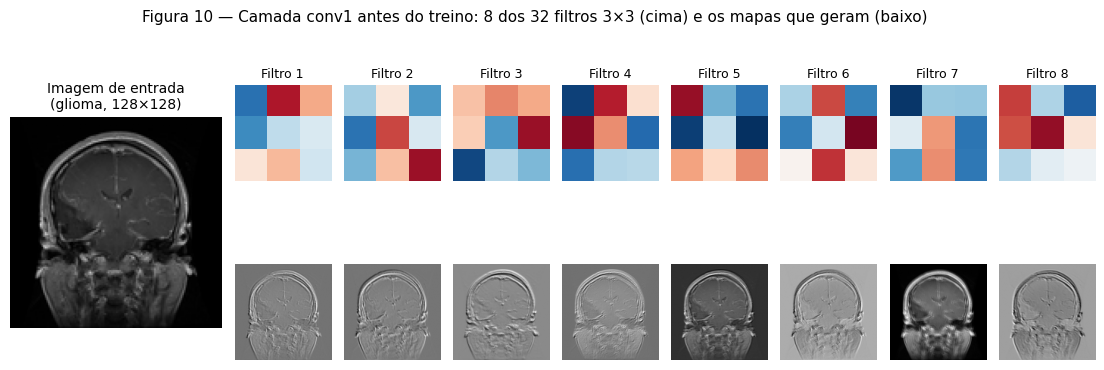

In [140]:
# Figura 10 — Filtros 3x3 e mapas de ativação da camada conv1 (ainda sem treino)
amostra = X['treino'][np.where(y['treino'] == 0)[0][0]]            # 1ª imagem de glioma do treino
mapas = modelo_c1.predict(amostra[np.newaxis].astype('float32'), verbose=0)[0]   # (128, 128, 32)
lim = np.abs(pesos[:, :, 0, :8]).max()

fig = plt.figure(figsize=(14, 4.4))
gs = fig.add_gridspec(2, 9, width_ratios=[2.2] + [1] * 8, hspace=0.12, wspace=0.12)

ax0 = fig.add_subplot(gs[:, 0])
ax0.imshow(amostra[:, :, 0], cmap='gray', vmin=0, vmax=255)
ax0.set_title('Imagem de entrada\n(glioma, 128×128)', fontsize=10)
ax0.axis('off')

for k in range(8):
    a1 = fig.add_subplot(gs[0, k + 1])
    a1.imshow(pesos[:, :, 0, k], cmap='RdBu', vmin=-lim, vmax=lim)
    a1.set_title(f'Filtro {k + 1}', fontsize=9)
    a1.axis('off')
    a2 = fig.add_subplot(gs[1, k + 1])
    a2.imshow(mapas[:, :, k], cmap='gray')
    a2.axis('off')

fig.suptitle('Figura 10 — Camada conv1 antes do treino: 8 dos 32 filtros 3×3 (cima) e os mapas que geram (baixo)', fontsize=11)
fig.savefig(f'{RELATORIO_DIR}/fig10_conv1_filtros_mapas.png', dpi=200, bbox_inches='tight')
plt.show()

**Observação:** a camada conv1, montada isoladamente, recebe imagens 128×128×1 e devolve 32 mapas de 128×128, com 320 parâmetros (288 pesos e 32 vieses), valor que confere com a conta feita à mão; a camada Rescaling, que leva os pixels de 0–255 para 0–1, não tem parâmetros. A Figura 10 mostra que, mesmo antes de qualquer treino, cada filtro produz um mapa diferente da mesma imagem: pelo aspecto, alguns preservam a forma do crânio com contraste alterado, outros realçam contornos e outros resultam em mapas mais escuros. Como os pesos são aleatórios, essas diferenças ainda não representam padrões úteis, como bordas, texturas ou massas. O treino ajustará os 288 pesos e os 32 vieses para que cada filtro responda a um padrão relevante para distinguir as classes, e a figura será repetida após o treino. Figura gravada em `relatorio/fig10_conv1_filtros_mapas.png`.

## Passo 13 — Função de ativação ReLU e inicialização He

Depois da convolução, cada valor do mapa pode ser positivo (o padrão do filtro foi encontrado) ou negativo (não foi). A função de ativação decide o que passa adiante. A escolhida é a ReLU, definida como f(x) = max(0, x): mantém os valores positivos e zera os negativos (por exemplo, -3, 0, 2 e 5 viram 0, 0, 2 e 5). Ela é indispensável porque, sem uma função não linear entre as camadas, empilhar camadas equivaleria matematicamente a uma única camada, e a rede não aprenderia padrões complexos. A ReLU foi preferida à sigmoide e à tangente hiperbólica porque estas saturam (tornam-se quase planas nos extremos), o que desacelera o aprendizado em redes com várias camadas, ao passo que a ReLU é simples, rápida e é o padrão em redes convolucionais. Seu limite conhecido é o dos neurônios que passam a produzir sempre zero ("ReLU morta"), o que será monitorado; variantes como a Leaky ReLU permanecem como alternativa.

Os pesos dos filtros começam como números aleatórios, e a escala desses números importa: se forem pequenos demais, o sinal vai se apagando de camada em camada; se forem grandes demais, cresce até saturar. A inicialização He sorteia os pesos de uma distribuição normal cuja variância é 2 dividida pelo número de entradas de cada neurônio (3 × 3 × canais de entrada), valor calculado para compensar o fato de a ReLU zerar cerca de metade dos valores. O padrão do Keras, a inicialização Glorot, foi pensado para ativações simétricas e não leva em conta esse efeito. Os vieses começam em zero.

O código monta, sem treino, quatro blocos de convolução com ReLU e pooling (32, 64, 128 e 256 filtros), passa por eles um lote de 64 imagens de treino e mede o desvio-padrão do sinal após a ReLU de cada bloco e a porcentagem de valores iguais a zero, comparando as inicializações Glorot e He. Em seguida, uma figura mostra a função ReLU e seu efeito sobre os mapas da camada conv1.

In [141]:
# Passo 13 — ReLU e inicialização He: efeito sobre o sinal que atravessa os 4 blocos
def blocos_conv_relu(inicializador):
    keras.utils.set_random_seed(SEED)
    entrada = keras.Input(shape=(128, 128, 1))
    x = layers.Rescaling(1.0 / 255)(entrada)
    saidas = []
    for n_filtros in [32, 64, 128, 256]:
        x = layers.Conv2D(n_filtros, 3, padding='same', kernel_initializer=inicializador)(x)
        x = layers.ReLU()(x)
        saidas.append(x)                        # sinal logo após a ReLU de cada bloco
        x = layers.MaxPooling2D(2)(x)
    return keras.Model(entrada, saidas)

rng = np.random.default_rng(SEED)
lote = X['treino'][rng.choice(len(X['treino']), 64, replace=False)].astype('float32')

desvios, zeros = [], []
for nome, ini in [('Glorot (padrão do Keras)', 'glorot_uniform'), ('He (adotada)', 'he_normal')]:
    saidas = blocos_conv_relu(ini).predict(lote, verbose=0)
    desvios.append([nome] + [float(s.std()) for s in saidas])
    zeros.append([nome] + [100 * float((s == 0).mean()) for s in saidas])

colunas = ['Inicialização', 'Bloco 1', 'Bloco 2', 'Bloco 3', 'Bloco 4']
print('Desvio-padrão do sinal após a ReLU de cada bloco:')
display(pd.DataFrame(desvios, columns=colunas).set_index('Inicialização').round(4))
print('\n% de valores iguais a zero após a ReLU de cada bloco:')
display(pd.DataFrame(zeros, columns=colunas).set_index('Inicialização').round(1))

Desvio-padrão do sinal após a ReLU de cada bloco:


,Bloco 1,Bloco 2,Bloco 3,Bloco 4
Inicialização,,,,
Glorot (padrão do Keras),0.0362,0.0196,0.0121,0.0077
He (adotada),0.3083,0.3408,0.4286,0.4824



% de valores iguais a zero após a ReLU de cada bloco:


,Bloco 1,Bloco 2,Bloco 3,Bloco 4
Inicialização,,,,
Glorot (padrão do Keras),57.5,62.0,50.9,50.5
He (adotada),62.0,50.6,49.6,50.2


**Figura 11 — A função ReLU e seu efeito sobre os mapas.** À esquerda, o gráfico da função ReLU: valores negativos viram zero e valores positivos passam sem alteração. À direita, para quatro filtros da camada conv1 (inicializados pelo método He, ainda sem treino), os mapas antes da ReLU, em que o azul indica valores positivos e o vermelho, negativos, e os mesmos mapas depois da ReLU, em que tudo o que era negativo ficou preto (zero).

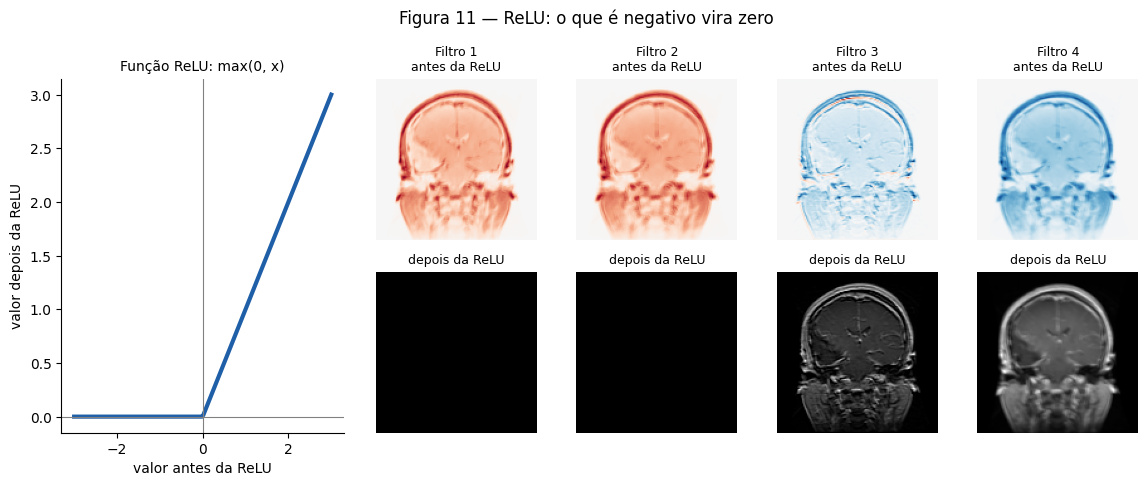

In [142]:
# Figura 11 — A função ReLU e seu efeito sobre os mapas da camada conv1
keras.utils.set_random_seed(SEED)
entrada = keras.Input(shape=(128, 128, 1))
x = layers.Rescaling(1.0 / 255)(entrada)
antes = layers.Conv2D(32, 3, padding='same', kernel_initializer='he_normal', name='conv1')(x)
depois = layers.ReLU(name='relu1')(antes)
modelo_relu = keras.Model(entrada, [antes, depois])
saida_antes, saida_depois = modelo_relu.predict(amostra[np.newaxis].astype('float32'), verbose=0)
m_antes, m_depois = saida_antes[0], saida_depois[0]

fig = plt.figure(figsize=(14, 4.6))
gs = fig.add_gridspec(2, 5, width_ratios=[1.6, 1, 1, 1, 1], hspace=0.2, wspace=0.12)

ax0 = fig.add_subplot(gs[:, 0])
v = np.linspace(-3, 3, 200)
ax0.plot(v, np.maximum(0, v), color='#1f5fa8', lw=3)
ax0.axhline(0, color='gray', lw=0.8)
ax0.axvline(0, color='gray', lw=0.8)
ax0.set_title('Função ReLU: max(0, x)', fontsize=10)
ax0.set_xlabel('valor antes da ReLU')
ax0.set_ylabel('valor depois da ReLU')
ax0.spines[['top', 'right']].set_visible(False)

for j in range(4):
    lim = np.abs(m_antes[:, :, j]).max()
    a1 = fig.add_subplot(gs[0, j + 1])
    a1.imshow(m_antes[:, :, j], cmap='RdBu', vmin=-lim, vmax=lim)   # azul = positivo, vermelho = negativo
    a1.set_title(f'Filtro {j + 1}\nantes da ReLU', fontsize=9)
    a1.axis('off')
    a2 = fig.add_subplot(gs[1, j + 1])
    a2.imshow(m_depois[:, :, j], cmap='gray', vmin=0, vmax=lim)
    a2.set_title('depois da ReLU', fontsize=9)
    a2.axis('off')

fig.suptitle('Figura 11 — ReLU: o que é negativo vira zero', fontsize=12, y=1.03)
fig.savefig(f'{RELATORIO_DIR}/fig11_relu_antes_depois.png', dpi=200, bbox_inches='tight')
plt.show()

**Observação — Passo 13 (ReLU e inicialização He)**

**Figura 11.** Nos filtros 1 e 2, todos os valores calculados eram negativos, então a ReLU os zerou por completo e os mapas ficaram pretos. Nos filtros 3 e 4, as regiões positivas passaram intactas e só as negativas viraram zero. A ReLU, portanto, guarda apenas a evidência positiva de cada filtro e descarta o resto.

**Glorot × He.** Passamos um lote de 64 imagens do treino por quatro blocos Conv + ReLU com pesos recém-sorteados (rede ainda sem treinar) e medimos o sinal após a ReLU de cada bloco:

| Inicialização | Bloco 1 | Bloco 2 | Bloco 3 | Bloco 4 |
|---|---|---|---|---|
| Glorot (desvio-padrão) | 0,0362 | 0,0196 | 0,0121 | 0,0077 |
| He (desvio-padrão) | 0,3083 | 0,3408 | 0,4286 | 0,4824 |
| Glorot (% de zeros) | 57,5 | 62,0 | 50,9 | 50,5 |
| He (% de zeros) | 62,0 | 50,6 | 49,6 | 50,2 |

A porcentagem de zeros é parecida nas duas (cerca de 50%, como se espera de uma ReLU sobre valores simétricos; o Bloco 1 tem mais zeros provavelmente por causa do fundo preto das imagens). A diferença está na força do sinal: com Glorot ele encolhe cerca de 4,7 vezes do Bloco 1 ao 4, enquanto com He se mantém estável (0,31 a 0,48). No Bloco 4, o sinal da He é cerca de 63 vezes maior. Um sinal que definha ao atravessar as camadas faz o início do treino ser lento, porque o ajuste dos pesos também chega fraco às primeiras camadas.

**Decisão.** Usaremos ReLU como ativação, inicialização He normal para os pesos e bias iniciado em zero. Este teste vale apenas para a rede no início, antes do treino, com um único lote e a semente 42.

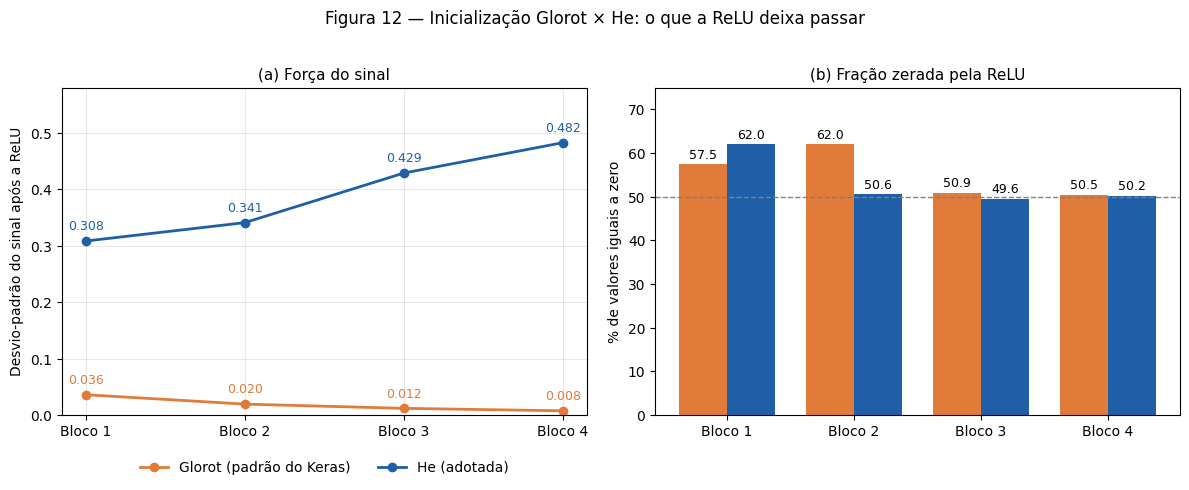

In [143]:
# Figura 12 — Glorot × He: força do sinal e zeros após a ReLU
blocos = ['Bloco 1', 'Bloco 2', 'Bloco 3', 'Bloco 4']
cores = {'Glorot (padrão do Keras)': '#E07B39', 'He (adotada)': '#1F5FA8'}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# (a) desvio-padrão do sinal
for linha in desvios:
    nome, valores = linha[0], linha[1:]
    ax1.plot(blocos, valores, marker='o', lw=2, color=cores[nome], label=nome)
    for b, v in zip(blocos, valores):
        ax1.annotate(f'{v:.3f}', (b, v), textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=9, color=cores[nome])
ax1.set_ylabel('Desvio-padrão do sinal após a ReLU')
ax1.set_title('(a) Força do sinal', fontsize=11)
ax1.set_ylim(0, 0.58)
ax1.grid(alpha=0.3)
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)

# (b) porcentagem de zeros
largura = 0.38
x = np.arange(4)
for i, linha in enumerate(zeros):
    nome, valores = linha[0], linha[1:]
    barras = ax2.bar(x + (i - 0.5) * largura, valores, largura, color=cores[nome])
    ax2.bar_label(barras, fmt='%.1f', fontsize=9, padding=2)
ax2.axhline(50, ls='--', color='gray', lw=1)
ax2.set_xticks(x)
ax2.set_xticklabels(blocos)
ax2.set_ylim(0, 75)
ax2.set_ylabel('% de valores iguais a zero')
ax2.set_title('(b) Fração zerada pela ReLU', fontsize=11)

fig.suptitle('Figura 12 — Inicialização Glorot × He: o que a ReLU deixa passar',
             fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig12_glorot_vs_he.png', dpi=200, bbox_inches='tight')
plt.show()

**Observação — Passo 13 (ReLU e inicialização He)**

**Figura 11.** Nos filtros 1 e 2, todos os valores calculados eram negativos, então a ReLU os zerou por completo e os mapas ficaram pretos. Nos filtros 3 e 4, as regiões positivas passaram intactas e só as negativas viraram zero. A ReLU, portanto, guarda apenas a evidência positiva de cada filtro e descarta o resto.

**Glorot × He.** Para comparar as duas inicializações, passamos um lote de 64 imagens sorteadas do conjunto de treino por quatro blocos Conv + ReLU com pesos recém-sorteados (rede ainda sem treinar, semente 42) e medimos o sinal após a ReLU de cada bloco. O desvio-padrão aqui não descreve as imagens: mede a força do sinal que sai de cada bloco. Nenhum rótulo foi usado, e validação e teste permaneceram intocados.

| Inicialização | Bloco 1 | Bloco 2 | Bloco 3 | Bloco 4 |
|---|---|---|---|---|
| Glorot (desvio-padrão) | 0,0362 | 0,0196 | 0,0121 | 0,0077 |
| He (desvio-padrão) | 0,3083 | 0,3408 | 0,4286 | 0,4824 |
| Glorot (% de zeros) | 57,5 | 62,0 | 50,9 | 50,5 |
| He (% de zeros) | 62,0 | 50,6 | 49,6 | 50,2 |

**Figura 12.** O painel (a) mostra que, com Glorot, o sinal encolhe cerca de 4,7 vezes do Bloco 1 ao 4, enquanto com He ele se mantém estável (0,31 a 0,48); no Bloco 4, o sinal da He é cerca de 63 vezes maior. O painel (b) mostra que a fração zerada pela ReLU é parecida nas duas (cerca de 50%, como se espera de uma ReLU sobre valores simétricos; o Bloco 1 tem mais zeros provavelmente por causa do fundo preto das imagens). Ou seja, a diferença está na força do sinal, não na quantidade de zeros. Um sinal que definha ao atravessar as camadas atrasa o início do treino, porque o ajuste dos pesos também chega fraco às primeiras camadas.

**Decisão.** Usaremos ReLU como ativação, inicialização He normal para os pesos e bias iniciado em zero. Este teste vale apenas para a rede no início, antes do treino, com um único lote; ele mostra que a He mantém o sinal saudável, mas não prova, por si só, melhor acurácia final.

## Passo 14 — Pooling: resumindo os mapas

Depois da convolução e da ReLU, cada filtro entrega um mapa do tamanho da imagem (128×128), com muita informação redundante: se um pixel acusa uma borda, o vizinho quase sempre acusa também. O pooling resume o mapa dividindo-o em janelas e guardando um único valor por janela.

**Decisão: MaxPooling 2×2, com passo 2.** Cada janela de 2×2 pixels (sem sobreposição) vira um só valor: o maior. Numa janela com os valores 1, 3, 5 e 2, o max pooling guarda 5; o average pooling guardaria a média, 2,75.

**Por que max, e não a média?**
- **Combina com a ReLU.** A ReLU já guarda só a evidência positiva do filtro; o max guarda a evidência mais forte de cada vizinhança. A média diluiria um pico forte e localizado, e uma lesão pequena pode ser justamente um pico local.
- **É o padrão em CNNs de classificação**, o que facilita comparar nosso resultado com a literatura.
- **Mais adiante usaremos a média**, mas só no final da rede (GlobalAveragePooling, Passo 16), com outro papel: resumir o mapa inteiro em um número por filtro.

**Por que fazer pooling?**
1. **Menos contas:** o mapa passa a ter um quarto dos valores a cada bloco (128 → 64 → 32 → 16 → 8).
2. **Tolerância a pequenos deslocamentos:** se a mancha mudar um ou dois pixels de lugar, o maior valor da janela continua o mesmo.
3. **Visão mais ampla:** com o mapa menor, um filtro 3×3 do bloco seguinte enxerga uma região maior da imagem original, e a rede passa de bordas para formas.

O pooling **não tem pesos**: não aprende nada e não acrescenta parâmetros. O custo é jogar fora 75% dos valores e perder a posição exata dentro da janela, o que é aceitável para classificar, mas seria um problema para localizar o tumor com precisão (segmentação).

In [144]:
# Passo 14 — Pooling: MaxPooling 2×2 sobre os mapas de uma imagem real
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
idx = int(rng.integers(len(X['treino'])))
imagem = X['treino'][idx:idx + 1].astype('float32')
classe = CLASSES[int(y['treino'][idx])]

entrada = keras.Input(shape=(128, 128, 1))
x = layers.Rescaling(1.0 / 255)(entrada)
x = layers.Conv2D(4, 3, padding='same', kernel_initializer='he_normal')(x)
relu = layers.ReLU()(x)
maxp = layers.MaxPooling2D(2)(relu)
avgp = layers.AveragePooling2D(2)(relu)
modelo_p = keras.Model(entrada, [relu, maxp, avgp])
mapa_relu, mapa_max, mapa_avg = modelo_p.predict(imagem, verbose=0)

print(f'Imagem sorteada do treino: índice {idx}, classe {classe}')
print(f'Mapas após a ReLU:      {mapa_relu.shape[1:]}  -> {mapa_relu[0].size:,} valores')
print(f'Após MaxPooling 2×2:    {mapa_max.shape[1:]}  -> {mapa_max[0].size:,} valores '
      f'({100 * mapa_max[0].size / mapa_relu[0].size:.0f}% do original)')
print(f'Parâmetros do pooling:  {sum(l.count_params() for l in modelo_p.layers if isinstance(l, layers.MaxPooling2D))}')

manual = mapa_relu.reshape(1, 64, 2, 64, 2, 4).max(axis=(2, 4))
print(f'\nConfere com o cálculo manual (maior valor de cada janela)? {np.allclose(manual, mapa_max)}')
print(f'Maior valor do mapa: ReLU {mapa_relu.max():.3f} | max pooling {mapa_max.max():.3f} | '
      f'average pooling {mapa_avg.max():.3f}')

Imagem sorteada do treino: índice 348, classe glioma
Mapas após a ReLU:      (128, 128, 4)  -> 65,536 valores
Após MaxPooling 2×2:    (64, 64, 4)  -> 16,384 valores (25% do original)
Parâmetros do pooling:  0

Confere com o cálculo manual (maior valor de cada janela)? True
Maior valor do mapa: ReLU 1.206 | max pooling 1.206 | average pooling 0.825


Filtro 4, recorte começando na linha 78, coluna 56
Reduzido = maior valor de cada janela 2×2? True


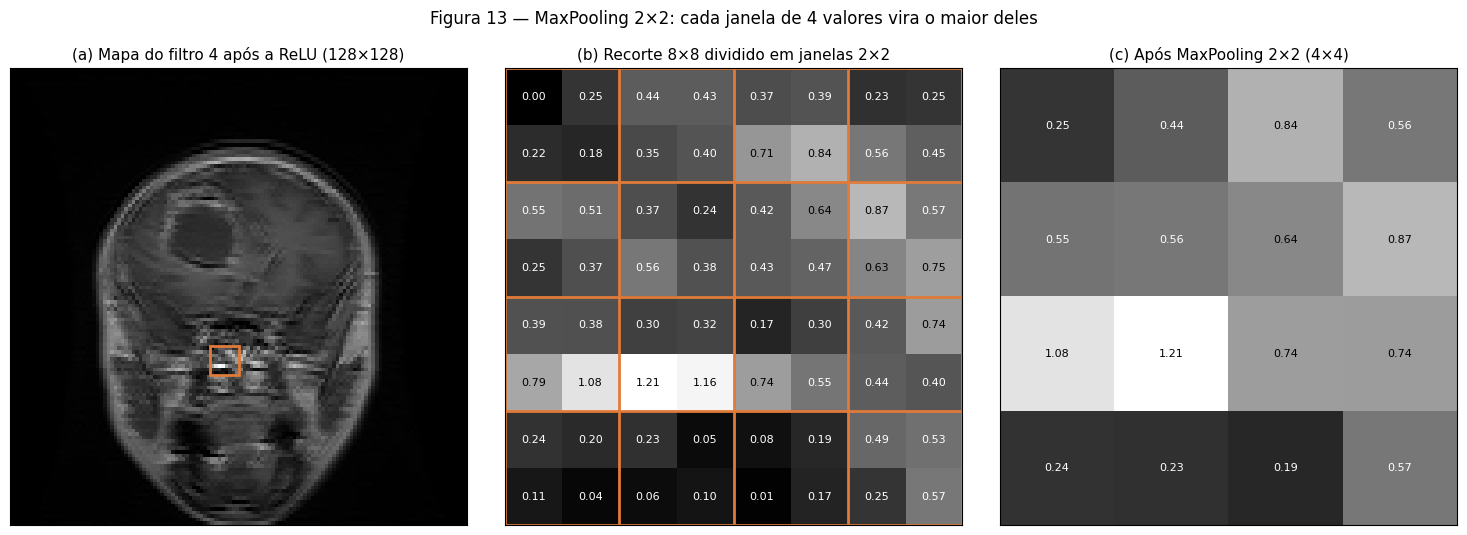

In [145]:
# Figura 13 — MaxPooling 2×2 na prática: um recorte 8×8 de um mapa real
from matplotlib.patches import Rectangle

f = int(np.argmax(mapa_relu[0].mean(axis=(0, 1))))
melhor_desvio, pos = -1, (0, 0)
for i in range(0, 128 - 8 + 1, 2):
    for j in range(0, 128 - 8 + 1, 2):
        d = mapa_relu[0, i:i + 8, j:j + 8, f].std()
        if d > melhor_desvio:
            melhor_desvio, pos = d, (i, j)
i, j = pos
bloco = mapa_relu[0, i:i + 8, j:j + 8, f]
reduzido = mapa_max[0, i // 2:i // 2 + 4, j // 2:j // 2 + 4, f]
print(f'Filtro {f + 1}, recorte começando na linha {i}, coluna {j}')
print('Reduzido = maior valor de cada janela 2×2?',
      np.allclose(reduzido, bloco.reshape(4, 2, 4, 2).max(axis=(1, 3))))

def anotar(ax, matriz, vmax):
    for (r, c), v in np.ndenumerate(matriz):
        ax.text(c, r, f'{v:.2f}', ha='center', va='center', fontsize=8,
                color='white' if v < 0.5 * vmax else 'black')

vmax = float(bloco.max())
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))

axes[0].imshow(mapa_relu[0, :, :, f], cmap='gray')
axes[0].add_patch(Rectangle((j - 0.5, i - 0.5), 8, 8, fill=False, ec='#E07B39', lw=2))
axes[0].set_title(f'(a) Mapa do filtro {f + 1} após a ReLU (128×128)', fontsize=11)

axes[1].imshow(bloco, cmap='gray', vmin=0, vmax=vmax)
for k in range(0, 9, 2):
    axes[1].axvline(k - 0.5, color='#E07B39', lw=2)
    axes[1].axhline(k - 0.5, color='#E07B39', lw=2)
anotar(axes[1], bloco, vmax)
axes[1].set_title('(b) Recorte 8×8 dividido em janelas 2×2', fontsize=11)

axes[2].imshow(reduzido, cmap='gray', vmin=0, vmax=vmax)
anotar(axes[2], reduzido, vmax)
axes[2].set_title('(c) Após MaxPooling 2×2 (4×4)', fontsize=11)

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle('Figura 13 — MaxPooling 2×2: cada janela de 4 valores vira o maior deles',
             fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig13_maxpool_exemplo.png', dpi=200, bbox_inches='tight')
plt.show()

**Observação — Passo 14 (MaxPooling 2×2)**

**Saída numérica.** Usando uma imagem de treino sorteada (índice 348, classe glioma) e 4 filtros, o mapa após a ReLU tinha 128×128×4 (65.536 valores) e, após o MaxPooling 2×2, 64×64×4 (16.384 valores), ou seja, 25% do original. A camada de pooling tem 0 parâmetros, pois não aprende nada. O resultado coincidiu com o cálculo manual do maior valor de cada janela (conferência `True`).

**O pico é preservado.** O maior valor do mapa foi 1,206 após a ReLU e continuou 1,206 após o max pooling, enquanto o average pooling o reduziu para cerca de 0,82, aproximadamente um terço a menos. Isso confirma o argumento da decisão: a média dilui picos fortes e localizados, o max os mantém.

**Figura 13.** No recorte 8×8 do mapa do filtro 4 (painel b), cada janela 2×2 virou um único valor no painel (c); por exemplo, a janela com 0,30, 0,32, 1,21 e 1,16 virou 1,21. O recorte foi escolhido por conter a maior variação de valores e inclui o pico do mapa. A estrutura geral se mantém no mapa reduzido (a região clara continua clara), só com metade da altura e da largura.

**Decisão mantida.** Usaremos MaxPooling 2×2 com passo 2 após cada bloco convolucional. Este exemplo usa uma única imagem e filtros ainda sem treino, então ilustra o mecanismo, não o desempenho.

## Passo 15 — Empilhando os 4 blocos

Cada **bloco** reúne três peças já estudadas: Conv 3×3 → ReLU → MaxPooling 2×2. Empilhando quatro blocos, a rede aprende em etapas, como quem lê um texto: primeiro letras (poucos tipos de pista, muitas posições), depois sílabas, palavras e frases (muitos tipos possíveis, poucas posições).

**Decisões de arquitetura**
- **Número de filtros: 32 → 64 → 128 → 256** (dobra a cada bloco). No início há poucos tipos de pista simples (bordas, claro/escuro, textura); adiante essas pistas se combinam em formas, e as combinações são muitas. Como o pooling descarta 75% dos pixels a cada bloco, o custo do mapa menor compensa os filtros extras.
- **Convolução 3×3, passo 1 e padding "same":** a convolução mantém o tamanho do mapa; só o pooling o reduz (128 → 64 → 32 → 16 → 8).
- **Ativação ReLU e pesos iniciais He normal** (Passos 12 e 13); **MaxPooling 2×2** (Passo 14).
- A saída dos 4 blocos tem forma 8×8×256 e ainda não é uma resposta: a transformação em 4 números (um por classe) é o Passo 16.

Abaixo, a tabela com as formas dos mapas e o número de parâmetros de cada bloco, e a Figura 14 com os mapas reais que saem de cada bloco para uma imagem de treino (rede ainda sem treino).

In [146]:
# Passo 15 — Os 4 blocos empilhados (Conv 3×3 + ReLU + MaxPool 2×2), pesos He normal
FILTROS = [32, 64, 128, 256]

keras.utils.set_random_seed(SEED)
entrada = keras.Input(shape=(128, 128, 1))
x = layers.Rescaling(1.0 / 255)(entrada)
convs, saidas_conv, saidas_pool = [], [], []
for n in FILTROS:
    conv = layers.Conv2D(n, 3, padding='same', kernel_initializer='he_normal')
    x = layers.ReLU()(conv(x))
    saidas_conv.append(x)
    x = layers.MaxPooling2D(2)(x)
    saidas_pool.append(x)
    convs.append(conv)
extrator = keras.Model(entrada, saidas_pool)

fmt = lambda s: '×'.join(str(d) for d in s)
linhas, forma_entrada = [], (128, 128, 1)
for i, n in enumerate(FILTROS):
    s_conv = tuple(saidas_conv[i].shape[1:])
    s_pool = tuple(saidas_pool[i].shape[1:])
    linhas.append({'Bloco': i + 1, 'Filtros': n, 'Entrada': fmt(forma_entrada),
                   'Após Conv+ReLU': fmt(s_conv), 'Após MaxPool': fmt(s_pool),
                   'Valores na saída': f'{int(np.prod(s_pool)):,}',
                   'Parâmetros (conv)': f'{convs[i].count_params():,}'})
    forma_entrada = s_pool
tab08 = pd.DataFrame(linhas)
tab08.to_csv(f'{RELATORIO_DIR}/tab08_blocos_empilhados.csv', index=False, encoding='utf-8-sig')
display(tab08.set_index('Bloco'))

total_conv = sum(c.count_params() for c in convs)
dense = FILTROS[-1] * 4 + 4
print(f'Parâmetros dos 4 blocos: {total_conv:,}')
print(f'Camada de saída (Dense 256×4 + 4), que vem no Passo 16: {dense:,}')
print(f'Total previsto do modelo: {total_conv + dense:,}')

# mapas reais de uma imagem de treino (a mesma da Figura 13)
rng = np.random.default_rng(SEED)
idx = int(rng.integers(len(X['treino'])))
imagem = X['treino'][idx:idx + 1].astype('float32')
classe = CLASSES[int(y['treino'][idx])]
mapas_blocos = [m[0] for m in extrator.predict(imagem, verbose=0)]
print(f'\nImagem de treino: índice {idx}, classe {classe}')

,Filtros,Entrada,Após Conv+ReLU,Após MaxPool,Valores na saída,Parâmetros (conv)
Bloco,,,,,,
1,32,128×128×1,128×128×32,64×64×32,"131,072",320
2,64,64×64×32,64×64×64,32×32×64,"65,536","18,496"
3,128,32×32×64,32×32×128,16×16×128,"32,768","73,856"
4,256,16×16×128,16×16×256,8×8×256,"16,384","295,168"


Parâmetros dos 4 blocos: 387,840
Camada de saída (Dense 256×4 + 4), que vem no Passo 16: 1,028
Total previsto do modelo: 388,868

Imagem de treino: índice 348, classe glioma


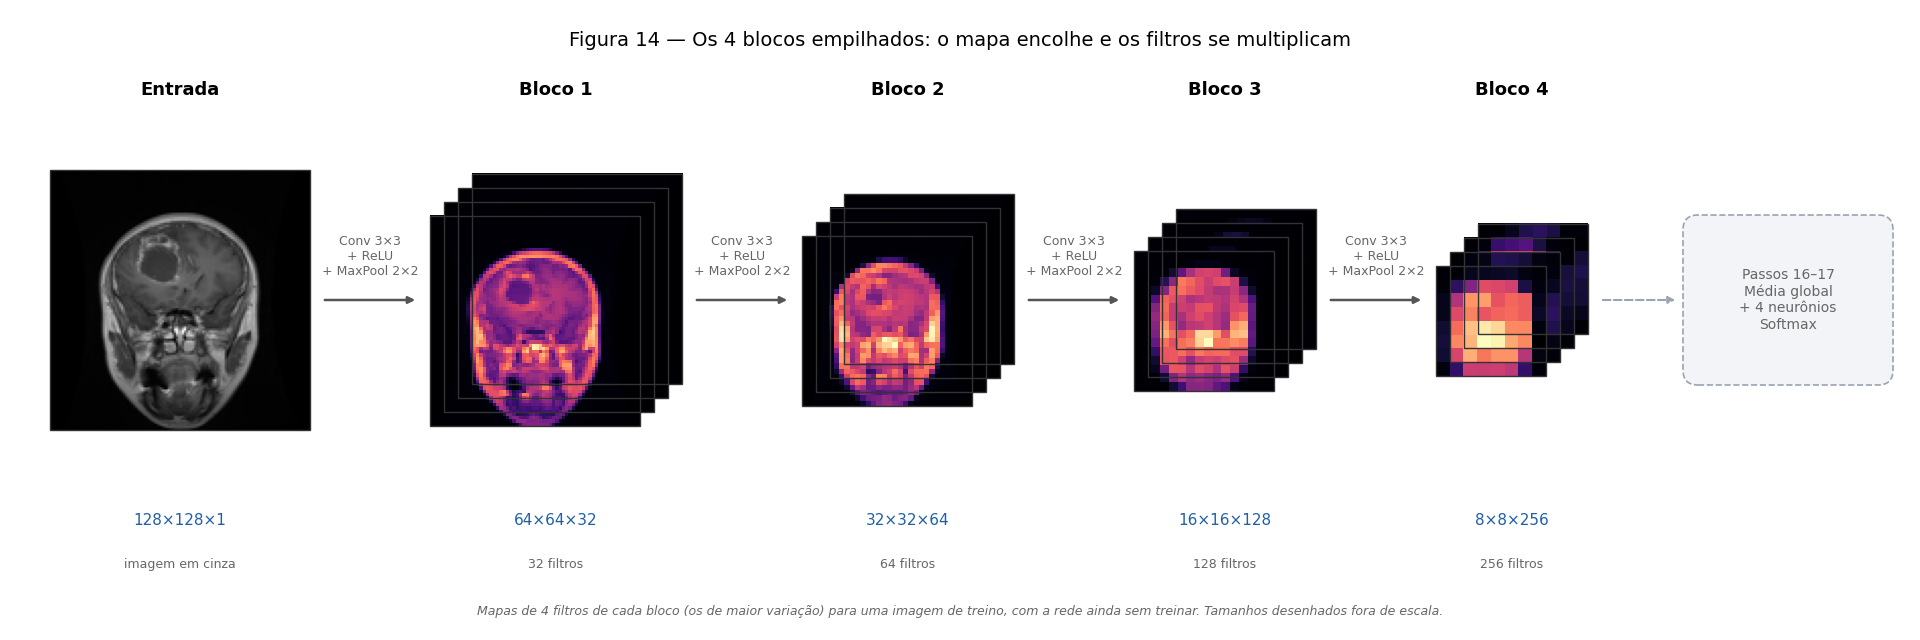

In [147]:
# Figura 14 — Os 4 blocos empilhados, com mapas reais de uma imagem de treino
from matplotlib.patches import Rectangle, FancyBboxPatch

lados = [2.6, 2.1, 1.7, 1.4, 1.1]      # tamanhos desenhados (fora de escala)
d, gap, yc = 0.14, 1.2, 3.3
AZUL, CINZA = '#1F5FA8', '#666666'

fig = plt.figure(figsize=(19, 6.2))
ax = fig.add_axes([0, 0, 1, 1])
ax.axis('off')

def carta(x, y, lado, mapa, cmap):
    vmax = float(mapa.max()) if mapa.max() > 0 else 1.0
    ax.imshow(mapa, cmap=cmap, extent=(x, x + lado, y, y + lado),
              aspect='auto', vmin=0, vmax=vmax, zorder=2)
    ax.add_patch(Rectangle((x, y), lado, lado, fill=False, ec='#333333', lw=1, zorder=3))

posicoes, x = [], 0.4
for k, lado in enumerate(lados):
    largura = lado if k == 0 else lado + 3 * d
    posicoes.append((x, largura))
    x += largura + gap

# entrada
x0, w = posicoes[0]
carta(x0, yc - lados[0] / 2, lados[0], imagem[0, :, :, 0], 'gray')
ax.text(x0 + w / 2, 5.35, 'Entrada', ha='center', fontsize=13, fontweight='bold')
ax.text(x0 + w / 2, 1.05, '128×128×1', ha='center', fontsize=11, color=AZUL)
ax.text(x0 + w / 2, 0.62, 'imagem em cinza', ha='center', fontsize=9, color=CINZA)

# blocos
for b in range(4):
    x0, w = posicoes[b + 1]
    lado = lados[b + 1]
    y0 = yc - (lado + 3 * d) / 2
    mapa = mapas_blocos[b]
    ordem = np.argsort(-mapa.std(axis=(0, 1)))[:4]
    for k in (3, 2, 1, 0):
        carta(x0 + k * d, y0 + k * d, lado, mapa[:, :, ordem[k]], 'magma')
    h, wd, c = mapa.shape
    ax.text(x0 + w / 2, 5.35, f'Bloco {b + 1}', ha='center', fontsize=13, fontweight='bold')
    ax.text(x0 + w / 2, 1.05, f'{h}×{wd}×{c}', ha='center', fontsize=11, color=AZUL)
    ax.text(x0 + w / 2, 0.62, f'{c} filtros', ha='center', fontsize=9, color=CINZA)

# setas entre as etapas
for k in range(4):
    xa = posicoes[k][0] + posicoes[k][1] + 0.12
    xb = posicoes[k + 1][0] - 0.12
    ax.annotate('', xy=(xb, yc), xytext=(xa, yc),
                arrowprops=dict(arrowstyle='-|>', lw=1.8, color='#555555'))
    ax.text((xa + xb) / 2, yc + 0.22, 'Conv 3×3\n+ ReLU\n+ MaxPool 2×2',
            ha='center', va='bottom', fontsize=9, color=CINZA)

# o que vem depois
fim = posicoes[-1][0] + posicoes[-1][1]
bx = fim + 1.0
ax.annotate('', xy=(bx - 0.1, yc), xytext=(fim + 0.12, yc),
            arrowprops=dict(arrowstyle='-|>', lw=1.5, color='#9AA3AF', ls='--'))
ax.add_patch(FancyBboxPatch((bx, yc - 0.8), 2.0, 1.6,
                            boxstyle='round,pad=0.05,rounding_size=0.15',
                            fc='#F2F4F7', ec='#9AA3AF', lw=1.2, ls='--'))
ax.text(bx + 1.0, yc, 'Passos 16–17\nMédia global\n+ 4 neurônios\nSoftmax',
        ha='center', va='center', fontsize=10, color=CINZA)

ax.text(9.5, 5.9, 'Figura 14 — Os 4 blocos empilhados: o mapa encolhe e os filtros se multiplicam',
        ha='center', va='center', fontsize=14)
ax.text(9.5, 0.15, 'Mapas de 4 filtros de cada bloco (os de maior variação) para uma imagem de treino, '
        'com a rede ainda sem treinar. Tamanhos desenhados fora de escala.',
        ha='center', fontsize=9, style='italic', color=CINZA)

ax.set_xlim(0, 19)
ax.set_ylim(0, 6.2)
fig.savefig(f'{RELATORIO_DIR}/fig14_blocos_empilhados.png', dpi=200,
            bbox_inches='tight', facecolor='white')
plt.show()

**Observação — Passo 15 (os 4 blocos empilhados)**

**Formas dos mapas.** A imagem de entrada (128×128×1) atravessa quatro blocos e chega a 8×8×256. A cada bloco, a altura e a largura caem pela metade (128 → 64 → 32 → 16 → 8) e o número de filtros dobra (32 → 64 → 128 → 256). Dentro de cada bloco, a convolução com padding "same" mantém o tamanho do mapa; só o MaxPooling o reduz.

| Bloco | Filtros | Entrada | Após Conv+ReLU | Após MaxPool | Valores na saída | Parâmetros (conv) |
|---|---|---|---|---|---|---|
| 1 | 32 | 128×128×1 | 128×128×32 | 64×64×32 | 131.072 | 320 |
| 2 | 64 | 64×64×32 | 64×64×64 | 32×32×64 | 65.536 | 18.496 |
| 3 | 128 | 32×32×64 | 32×32×128 | 16×16×128 | 32.768 | 73.856 |
| 4 | 256 | 16×16×128 | 16×16×256 | 8×8×256 | 16.384 | 295.168 |

**Valores e parâmetros.** Como o mapa perde 3/4 dos pixels a cada bloco e os filtros só dobram, o número de valores na saída cai pela metade a cada bloco (131.072 → 16.384). Já os parâmetros crescem cerca de quatro vezes por bloco, porque tanto os canais de entrada quanto os de saída dobram: o Bloco 4 concentra 295.168 dos 387.840 parâmetros das convoluções (cerca de 76%). A saída final (8×8×256 = 16.384 valores) tem o mesmo número de valores que a entrada (128×128 = 16.384), mas com outro significado: a rede troca "onde" (muitos pixels) por "o quê" (256 tipos de pista).

**Conferência com o plano.** Os 387.840 parâmetros dos blocos, somados aos 1.028 da camada de saída (Dense 256×4 + 4, Passo 16), totalizam 388.868, o valor previsto na arquitetura proposta.

**Figura 14.** Mostra a imagem de treino de índice 348 (glioma) entrando na rede e, em cada bloco, os mapas de 4 filtros (os de maior variação), com o mapa encolhendo e as "cartas" empilhadas representando os filtros. A rede ainda não foi treinada, então os mapas refletem filtros aleatórios e não devem ser interpretados; a figura ilustra a estrutura. Os mapas após o treino serão comparados na Fase 5.

## Passo 16 — A saída da rede: média global e Softmax

Os 4 blocos entregam um volume de 8×8×256 (16.384 valores), mas a rede precisa responder com 4 números: a probabilidade de cada classe. Isso é feito em duas etapas.

**1) GlobalAveragePooling.** Para cada um dos 256 filtros, calcula a média do mapa 8×8 e a reduz a um único número ("quanto desta pista aparece na imagem, em geral"). O resultado são 256 números por imagem. Não tem parâmetros.

**2) Dense com 4 neurônios e Softmax.** Cada neurônio (um por classe) pondera os 256 números com pesos aprendidos e soma um bias, gerando uma pontuação. O Softmax converte as 4 pontuações em probabilidades positivas que somam 100%: p_i = e^(z_i) / soma de e^(z_j). Exemplo: pontuações 2,0; 1,0; 0,1; −1,0 viram 63,8%; 23,5%; 9,5%; 3,2%.

**Decisões**
- **Média global em vez de Flatten.** Esticar os 16.384 valores direto nos 4 neurônios exigiria 65.540 parâmetros; com a média global, são 1.028 (256×4 + 4). Menos parâmetros reduzem o risco de overfitting. O custo é descartar a posição dentro do mapa 8×8, aceitável para classificação; a comparação com Flatten ficará como experimento da Fase 4.
- **Softmax com 4 neurônios**, pois cada imagem pertence a exatamente uma das 4 classes.
- **Inicialização da camada final:** padrão do Keras (Glorot uniforme, bias zero), pois não há ReLU depois dela; a He foi pensada para camadas seguidas de ReLU.

Abaixo, uma imagem de treino atravessa a saída da rede (ainda sem treino), com a Figura 15 mostrando os 256 números e as 4 probabilidades resultantes.

In [148]:
# Passo 16 — Saída da rede: GlobalAveragePooling + Dense(4, softmax)
keras.utils.set_random_seed(SEED)
saida_blocos = extrator.predict(imagem, verbose=0)[-1]          # (1, 8, 8, 256)
print(f'Saída dos 4 blocos: {saida_blocos.shape[1:]}  -> {saida_blocos[0].size:,} valores')

resumo = layers.GlobalAveragePooling2D()(saida_blocos).numpy()   # (1, 256)
print(f'Após GlobalAveragePooling: {resumo.shape[1:]}  -> {resumo[0].size} valores (um por filtro)')
print('Confere com a média manual de cada mapa 8×8?',
      np.allclose(resumo, saida_blocos.mean(axis=(1, 2)), atol=1e-6))

camada_saida = layers.Dense(4, activation='softmax')
probs = camada_saida(resumo).numpy()[0]
pesos_d, vies_d = camada_saida.get_weights()
pontuacoes = (resumo @ pesos_d + vies_d)[0]
softmax_manual = np.exp(pontuacoes - pontuacoes.max())
softmax_manual = softmax_manual / softmax_manual.sum()
print('Confere com o Softmax calculado à mão?', np.allclose(probs, softmax_manual, atol=1e-5))

tab09 = pd.DataFrame({'Classe': CLASSES,
                      'Pontuação (antes do Softmax)': pontuacoes.round(3),
                      'Probabilidade (%)': (100 * probs).round(1)})
display(tab09.set_index('Classe'))
print(f'Soma das probabilidades: {probs.sum():.4f}')

print(f'\nParâmetros da camada de saída (256×4 + 4): {camada_saida.count_params():,}')
print(f'Com Flatten (8×8×256 = 16.384 valores) direto nos 4 neurônios: {16384 * 4 + 4:,}')
print(f'Imagem usada: índice {idx}, classe real {classe} (rede ainda sem treino)')

Saída dos 4 blocos: (8, 8, 256)  -> 16,384 valores
Após GlobalAveragePooling: (256,)  -> 256 valores (um por filtro)
Confere com a média manual de cada mapa 8×8? True
Confere com o Softmax calculado à mão? True


,Pontuação (antes do Softmax),Probabilidade (%)
Classe,,
glioma,-0.108,20.299999
meningioma,-0.741,10.800000
notumor,0.215,28.100000
pituitary,0.588,40.799999


Soma das probabilidades: 1.0000

Parâmetros da camada de saída (256×4 + 4): 1,028
Com Flatten (8×8×256 = 16.384 valores) direto nos 4 neurônios: 65,540
Imagem usada: índice 348, classe real glioma (rede ainda sem treino)


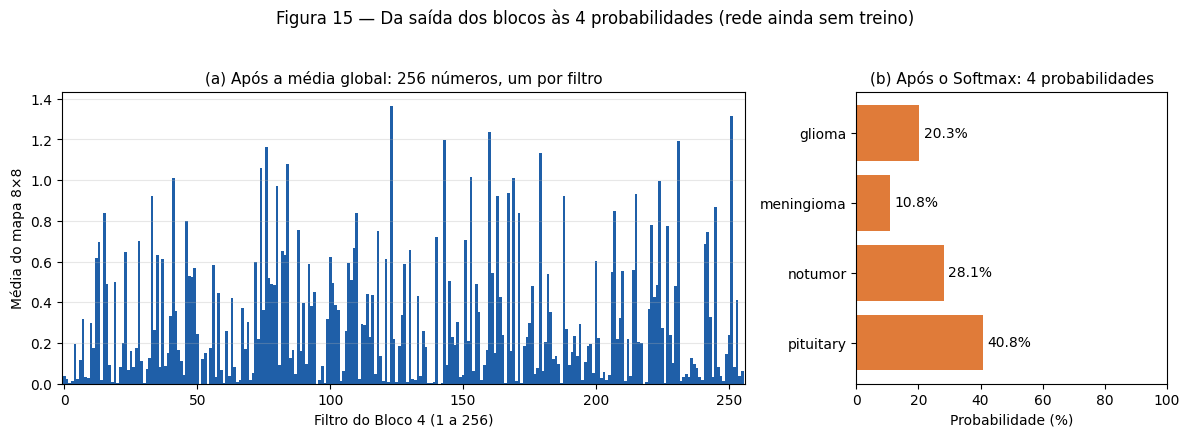

In [149]:
# Figura 15 — Da saída dos blocos às 4 probabilidades (rede ainda sem treino)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2),
                               gridspec_kw={'width_ratios': [2.2, 1]})

ax1.bar(range(256), resumo[0], color='#1F5FA8', width=1.0)
ax1.set_xlim(-1, 256)
ax1.set_xlabel('Filtro do Bloco 4 (1 a 256)')
ax1.set_ylabel('Média do mapa 8×8')
ax1.set_title('(a) Após a média global: 256 números, um por filtro', fontsize=11)
ax1.grid(axis='y', alpha=0.3)

barras = ax2.barh(CLASSES, 100 * probs, color='#E07B39')
ax2.bar_label(barras, fmt='%.1f%%', padding=3, fontsize=10)
ax2.set_xlim(0, 100)
ax2.invert_yaxis()
ax2.set_xlabel('Probabilidade (%)')
ax2.set_title('(b) Após o Softmax: 4 probabilidades', fontsize=11)

fig.suptitle('Figura 15 — Da saída dos blocos às 4 probabilidades (rede ainda sem treino)',
             fontsize=12, y=1.03)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig15_saida_da_rede.png', dpi=200, bbox_inches='tight')
plt.show()

**Observação — Passo 16 (média global e Softmax)**

**O caminho até a resposta.** A saída dos 4 blocos (8×8×256, ou 16.384 valores) passa pela média global e vira 256 números, um por filtro; a camada Dense com 4 neurônios e Softmax transforma esses 256 números em 4 probabilidades que somam 100%.

**Figura 15.** No painel (a), todos os 256 valores são positivos ou nulos, consequência da ReLU e do max pooling, que não deixam passar valores negativos. Alguns filtros respondem forte à imagem (picos acima de 1) e muitos respondem pouco, ou seja, cada filtro reage de um jeito. No painel (b), as probabilidades foram: glioma 20,3%, meningioma 10,8%, sem tumor 28,1% e hipófise 40,8%. A imagem usada é de um glioma, e a rede, ainda sem treino e com pesos finais aleatórios, atribui a maior probabilidade à hipófise. Isso é esperado: antes do treino, a "opinião" da rede não tem valor. A mesma figura será refeita após o treino, para a mesma imagem, na Fase 5.

**Parâmetros.** A camada de saída tem 256×4 + 4 = 1.028 parâmetros. Se esticássemos os 16.384 valores direto nos 4 neurônios (Flatten), seriam 16.384×4 + 4 = 65.540, cerca de 64 vezes mais, com maior risco de overfitting. A comparação entre as duas opções fica como experimento da Fase 4.

**Decisão mantida.** Média global seguida de Dense(4) com Softmax, inicialização padrão do Keras (Glorot) e bias zero na camada final.

## Passo 17 — O modelo completo

Juntamos as peças dos Passos 12 a 16 em um único modelo, do input à saída, dentro de uma função reutilizável (`construir_modelo`), para repetir o treino na Fase 4 mudando um fator de cada vez.

**Arquitetura:** Rescaling (÷255) → 4 blocos [Conv 3×3 (32, 64, 128, 256 filtros, padding "same", He normal) + ReLU + MaxPooling 2×2] → GlobalAveragePooling → Dense(4, Softmax).

O `model.summary()` abaixo lista cada camada, a forma da sua saída e o número de parâmetros. A conferência principal é que o total coincida com o previsto nos Passos 15 e 16: 387.840 (blocos) + 1.028 (saída) = 388.868 parâmetros, todos treináveis (a camada Rescaling não tem parâmetros).

In [150]:
# Passo 17 — O modelo completo (função reutilizável)
def construir_modelo(filtros=(32, 64, 128, 256), semente=SEED):
    keras.utils.set_random_seed(semente)
    entrada = keras.Input(shape=(128, 128, 1), name='imagem')
    x = layers.Rescaling(1.0 / 255, name='escala')(entrada)
    for i, n in enumerate(filtros, start=1):
        x = layers.Conv2D(n, 3, padding='same', kernel_initializer='he_normal', name=f'conv{i}')(x)
        x = layers.ReLU(name=f'relu{i}')(x)
        x = layers.MaxPooling2D(2, name=f'pool{i}')(x)
    x = layers.GlobalAveragePooling2D(name='media_global')(x)
    saida = layers.Dense(4, activation='softmax', name='saida')(x)
    return keras.Model(entrada, saida, name='cnn_tumor_cerebral')

modelo = construir_modelo()
modelo.summary()

total = modelo.count_params()
print(f'\nTotal de parâmetros: {total:,}  |  previsto: 388,868  |  confere? {total == 388868}')

# a rede aceita um lote e devolve 4 probabilidades por imagem
teste = modelo.predict(X['treino'][:5].astype('float32'), verbose=0)
print(f'Saída para 5 imagens: forma {teste.shape}; soma das probabilidades de cada imagem: {teste.sum(axis=1).round(4)}')

# tabela para o relatório
fmt = lambda s: '×'.join(str(d) for d in s)
tab_arq = pd.DataFrame([{'Camada': l.name, 'Tipo': l.__class__.__name__,
                         'Forma de saída': fmt(l.output.shape[1:]),
                         'Parâmetros': f'{l.count_params():,}'} for l in modelo.layers[1:]])
tab_arq.to_csv(f'{RELATORIO_DIR}/tab09_arquitetura_cnn.csv', index=False, encoding='utf-8-sig')
display(tab_arq.set_index('Camada'))

Model: "cnn_tumor_cerebral"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ escala (Rescaling)              │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (ReLU)                    │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ media_global                    │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,868 (1.48 MB)

 Trainable params: 388,868 (1.48 MB)

 Non-trainable params: 0 (0.00 B)


Total de parâmetros: 388,868  |  previsto: 388,868  |  confere? True
Saída para 5 imagens: forma (5, 4); soma das probabilidades de cada imagem: [1. 1. 1. 1. 1.]


,Tipo,Forma de saída,Parâmetros
Camada,,,
escala,Rescaling,128×128×1,0
conv1,Conv2D,128×128×32,320
relu1,ReLU,128×128×32,0
pool1,MaxPooling2D,64×64×32,0
conv2,Conv2D,64×64×64,"18,496"
relu2,ReLU,64×64×64,0
pool2,MaxPooling2D,32×32×64,0
conv3,Conv2D,32×32×128,"73,856"
relu3,ReLU,32×32×128,0


**Observação — Passo 17 (o modelo completo)**

**O modelo.** A função `construir_modelo` monta a rede do input às 4 probabilidades: Rescaling, 4 blocos (Conv 3×3 + ReLU + MaxPooling 2×2, com 32, 64, 128 e 256 filtros), média global e Dense(4) com Softmax, num total de 15 camadas (sem contar a entrada). A mesma função será chamada de novo na Fase 4, mudando um fator de cada vez.

**Parâmetros.** O `model.summary()` informa 388.868 parâmetros, todos treináveis (1,48 MB) e nenhum não treinável, exatamente o valor previsto nos Passos 15 e 16 (387.840 nos blocos + 1.028 na saída). Só as 4 camadas convolucionais e a camada final têm parâmetros; Rescaling, ReLU, pooling e média global têm 0. A quarta convolução sozinha concentra 295.168 parâmetros, cerca de 76% do total.

**Estado atual.** Os pesos ainda são os sorteados na inicialização: a rede está montada, mas não aprendeu nada. Os próximos passos definem como ela vai aprender (perda, otimizador e configuração do treino).

## Passo 18 — A função de perda: entropia cruzada

Para a rede aprender, precisa de uma nota que diga o quanto errou: a **perda** (loss). Quanto menor, melhor; treinar é ajustar os pesos para baixá-la.

**Decisão: entropia cruzada categórica.** Ela olha apenas para a probabilidade p que a rede deu à classe correta e calcula **−ln(p)**: p = 0,90 gera perda 0,105; p = 0,50, 0,693; p = 0,10, 2,303; p = 0,01, 4,605. A punição cresce rápido quando a rede está confiante e errada.

**Por que não a acurácia como perda?** Ela só diz "acertou ou errou", muda aos saltos e não indica para que lado ajustar os pesos; a entropia cruzada varia de forma suave e também premia o acerto confiante.

**Versão sparse.** Nossos rótulos são inteiros (0 a 3); a forma *sparse* faz a mesma conta sem exigir a conversão para vetores one-hot.

**Conferência de sanidade.** Uma rede que chuta (25% para cada uma das 4 classes) tem perda −ln(0,25) ≈ 1,386; antes do treino, a perda do nosso modelo deve ficar próxima disso.

Perda = -ln(probabilidade dada à classe correta)
  probabilidade  0.99  ->  perda 0.010
  probabilidade  0.90  ->  perda 0.105
  probabilidade  0.50  ->  perda 0.693
  probabilidade  0.25  ->  perda 1.386
  probabilidade  0.10  ->  perda 2.303
  probabilidade  0.01  ->  perda 4.605

Rede que chuta (25% para cada classe): perda = 1.386

Perda do modelo sem treino (256 imagens de treino):
  calculada à mão: 1.753  |  pelo Keras: 1.753  |  coincidem? True
  referência de uma rede que chuta: 1.386


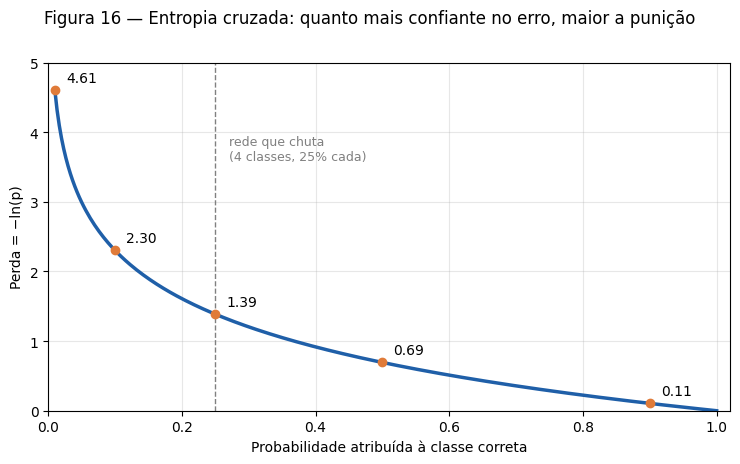

In [151]:
# Passo 18 — Função de perda: entropia cruzada (versão sparse)
import math

print('Perda = -ln(probabilidade dada à classe correta)')
for p in [0.99, 0.9, 0.5, 0.25, 0.1, 0.01]:
    print(f'  probabilidade {p:>5.2f}  ->  perda {-math.log(p):.3f}')
print(f'\nRede que chuta (25% para cada classe): perda = {-math.log(0.25):.3f}')

# perda do modelo ainda sem treino, em 256 imagens de treino
rng = np.random.default_rng(SEED)
ids = rng.choice(len(X['treino']), 256, replace=False)
lote_x = X['treino'][ids].astype('float32')
lote_y = y['treino'][ids].astype('int32')
probs_lote = modelo.predict(lote_x, verbose=0)

perda_manual = float(-np.mean(np.log(probs_lote[np.arange(256), lote_y])))
perda_keras = float(keras.losses.sparse_categorical_crossentropy(lote_y, probs_lote).numpy().mean())
print(f'\nPerda do modelo sem treino (256 imagens de treino):')
print(f'  calculada à mão: {perda_manual:.3f}  |  pelo Keras: {perda_keras:.3f}  |  coincidem? {np.isclose(perda_manual, perda_keras, atol=1e-4)}')
print(f'  referência de uma rede que chuta: {math.log(4):.3f}')

# Figura 16 — a curva da perda
p = np.linspace(0.01, 1, 300)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(p, -np.log(p), color='#1F5FA8', lw=2.5)
for q in [0.9, 0.5, 0.25, 0.1, 0.01]:
    ax.scatter(q, -np.log(q), color='#E07B39', zorder=3)
    ax.annotate(f'{-np.log(q):.2f}', (q, -np.log(q)), textcoords='offset points',
                xytext=(8, 6), fontsize=10)
ax.axvline(0.25, ls='--', color='gray', lw=1)
ax.text(0.27, 3.6, 'rede que chuta\n(4 classes, 25% cada)', fontsize=9, color='gray')
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 5)
ax.set_xlabel('Probabilidade atribuída à classe correta')
ax.set_ylabel('Perda = −ln(p)')
ax.grid(alpha=0.3)
fig.suptitle('Figura 16 — Entropia cruzada: quanto mais confiante no erro, maior a punição',
             fontsize=12, y=1.0)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig16_entropia_cruzada.png', dpi=200, bbox_inches='tight')
plt.show()

**Observação — Passo 18 (entropia cruzada)**

**A conta.** A perda é −ln(p), em que p é a probabilidade dada à classe correta: p = 0,99 gera 0,010; p = 0,90, 0,105; p = 0,50, 0,693; p = 0,25, 1,386; p = 0,10, 2,303; p = 0,01, 4,605.

**Figura 16.** A curva cai rápido à medida que p se aproxima de 1 e dispara quando p é pequena: a rede é pouco punida quando acerta com confiança e muito punida quando erra com confiança. O ponto p = 0,25 (1,39) marca a rede que chuta entre as 4 classes.

**Modelo sem treino.** Em 256 imagens de treino, a perda foi 1,753, com o mesmo valor calculado à mão e pelo Keras. Ela fica acima da referência de 1,386 porque os pesos aleatórios fazem a rede favorecer algumas classes de forma desigual, e uma previsão desigual tem perda média maior que a previsão uniforme. É um ponto de partida plausível, sem indício de erro na construção do modelo; no treino, a perda deve partir desse patamar e cair.

**Decisão mantida.** Entropia cruzada categórica na versão sparse (rótulos inteiros de 0 a 3), sem conversão para one-hot.

## Passo 19 — O otimizador: Adam

A perda mede o quanto a rede errou; o **otimizador** decide como ajustar os pesos para errar menos. A cada passo, ele calcula o **gradiente** (a direção em que a perda mais cai) e move cada peso um pouco nessa direção; o tamanho do passo é a **taxa de aprendizado** (learning rate). Se for pequena demais, o treino é lento; se for grande demais, os pesos "pulam" por cima do ponto ótimo e a perda pode até subir.

**Decisão: Adam, com taxa de aprendizado 0,001 (1e-3).** O Adam ajusta o passo de cada peso individualmente a partir do histórico dos gradientes (ganha velocidade quando o gradiente aponta sempre para o mesmo lado e freia quando oscila). Funciona bem com poucos ajustes e é um padrão em CNNs; 1e-3 é o valor padrão e serve como ponto de partida. Na Fase 4, testaremos 1e-2 e 1e-4 para medir o efeito.

**Teste de sanidade.** Antes de treinar de verdade, verificamos que a máquina funciona: um modelo novo deve conseguir reduzir a perda ao ser treinado repetidamente sobre um único lote pequeno (32 imagens). Isso não é aprendizado de verdade (a rede apenas decora o lote), mas prova que perda, otimizador e modelo estão ligados corretamente.

Mesmo lote de 32 imagens, 40 passos do Adam (lr = 0,001):
  passo  1: perda = 1.817
  passo  5: perda = 1.839
  passo 10: perda = 1.612
  passo 20: perda = 1.452
  passo 40: perda = 1.192
A perda caiu? True


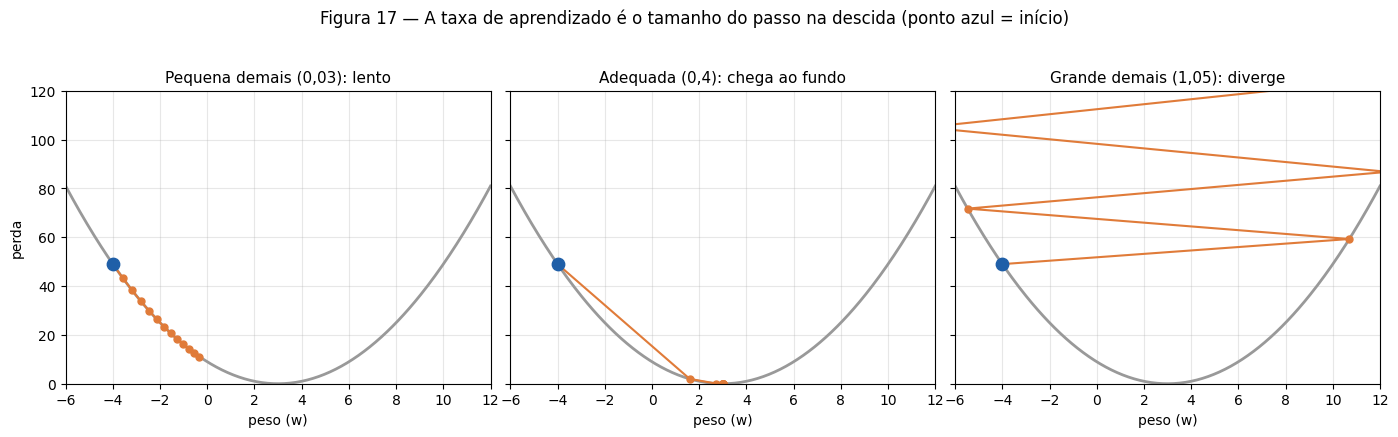

In [152]:
# Passo 19 — Otimizador Adam (lr = 1e-3): teste de sanidade e Figura 17
# 1) teste de sanidade: treinar um modelo novo repetidamente sobre 32 imagens
m = construir_modelo()                       # mesma inicialização do modelo do Passo 17
m.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
          loss='sparse_categorical_crossentropy', metrics=['accuracy'])
xb, yb = lote_x[:32], lote_y[:32]
perdas = [float(m.train_on_batch(xb, yb)[0]) for _ in range(40)]
print('Mesmo lote de 32 imagens, 40 passos do Adam (lr = 0,001):')
for passo in [1, 5, 10, 20, 40]:
    print(f'  passo {passo:>2}: perda = {perdas[passo - 1]:.3f}')
print(f'A perda caiu? {perdas[-1] < perdas[0]}')

# 2) Figura 17 — taxa de aprendizado como tamanho do passo (exemplo simples: perda = (w - 3)²)
def descer(lr, passos=12, w0=-4.0):
    ws = [w0]
    for _ in range(passos):
        ws.append(ws[-1] - lr * 2 * (ws[-1] - 3))
    return np.array(ws)

w = np.linspace(-6, 12, 300)
casos = [(0.03, 'Pequena demais (0,03): lento'),
         (0.4, 'Adequada (0,4): chega ao fundo'),
         (1.05, 'Grande demais (1,05): diverge')]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (lr, titulo) in zip(axes, casos):
    ax.plot(w, (w - 3) ** 2, color='#999999', lw=2)
    ws = descer(lr)
    ax.plot(ws, (ws - 3) ** 2, 'o-', color='#E07B39', lw=1.5, ms=5)
    ax.scatter(ws[0], (ws[0] - 3) ** 2, color='#1F5FA8', s=80, zorder=4)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel('peso (w)')
    ax.set_xlim(-6, 12)
    ax.set_ylim(0, 120)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('perda')
fig.suptitle('Figura 17 — A taxa de aprendizado é o tamanho do passo na descida (ponto azul = início)',
             fontsize=12, y=1.03)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig17_taxa_aprendizado.png', dpi=200, bbox_inches='tight')
plt.show()

**Observação — Passo 19 (otimizador Adam)**

**Teste de sanidade.** Treinando um modelo novo por 40 passos do Adam (taxa de aprendizado 0,001) sobre o mesmo lote de 32 imagens, a perda foi de 1,817 (passo 1) para 1,839 (passo 5), 1,612 (passo 10), 1,452 (passo 20) e 1,192 (passo 40), uma queda de cerca de 34%. Isso confirma que modelo, perda e otimizador estão ligados corretamente. A queda não é perfeitamente regular (no passo 5 a perda ficou um pouco acima da inicial), o que é comum nos primeiros passos do Adam, e é gradual porque 0,001 é um passo pequeno. Não é aprendizado de verdade: a rede apenas se ajusta ao mesmo lote.

**Figura 17.** Num exemplo simples, em que a perda é uma parábola com mínimo em w = 3, a taxa 0,03 é lenta (após 12 passos ainda está longe do fundo), a taxa 0,4 chega ao mínimo em poucos passos e a taxa 1,05 ultrapassa o mínimo a cada passo, cada vez mais longe, e a perda cresce. Na rede real são 388.868 pesos em vez de um, mas o princípio é o mesmo: a taxa ideal fica entre o passo tímido e o passo exagerado.

**Decisão mantida.** Adam com taxa de aprendizado 0,001, ponto de partida padrão. Os valores 0,01 e 0,0001 serão testados na Fase 4.

## Passo 20 — Configuração do treino

Este passo define como o treino vai rodar; o treino em si começa na Fase 4.

**Batch de 32.** A rede vê 32 imagens por vez, mede o erro no grupo e ajusta os pesos. Com 3.909 imagens de treino, são 123 ajustes por volta (122 lotes de 32 e um último de 5). Lotes pequenos dão mais ajustes por volta e o "ruído" de cada lote ajuda a evitar que a rede decore o treino; 32 é um valor clássico.

**Até 30 épocas, com seleção do melhor modelo.** Uma época é uma volta completa pelo treino. Em vez de adivinhar o número ideal, deixamos até 30 voltas e guardamos o modelo da melhor época, medida na validação (958 imagens que não participam do ajuste dos pesos). Se a rede começar a decorar o treino e piorar na validação, ficamos com a melhor versão. Critério: maior acurácia de validação (a perda de validação também será registrada e analisada nas curvas).

**Resumo:** Adam (taxa 0,001) · entropia cruzada sparse · métrica: acurácia · batch 32 · até 30 épocas · semente 42. O conjunto de teste (1.600 imagens) permanece intocado até a avaliação final.

A configuração fica empacotada em funções reutilizáveis (`compilar` e `callbacks_padrao`) para repetir o treino na Fase 4 mudando um fator de cada vez.

In [153]:
# Passo 20 — Configuração do treino (sem treinar ainda)
import os, math

CONFIG = dict(otimizador='Adam', taxa_aprendizado=1e-3,
              perda='sparse_categorical_crossentropy', metrica='accuracy',
              batch=32, epocas_max=30, monitor='val_accuracy')

PASTA_MODELOS = os.path.join(os.path.dirname(RELATORIO_DIR.rstrip('/')), 'modelos')
os.makedirs(PASTA_MODELOS, exist_ok=True)

def compilar(modelo, lr=CONFIG['taxa_aprendizado']):
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss=CONFIG['perda'], metrics=[CONFIG['metrica']])
    return modelo

def callbacks_padrao(nome):
    caminho = os.path.join(PASTA_MODELOS, f'{nome}.keras')
    return [keras.callbacks.ModelCheckpoint(caminho, monitor=CONFIG['monitor'], mode='max',
                                            save_best_only=True, verbose=0)]

modelo = compilar(construir_modelo())      # modelo novo, compilado, ainda sem treino

n_treino, n_val, n_teste = len(X['treino']), len(X['validacao']), len(X['teste'])
lotes = math.ceil(n_treino / CONFIG['batch'])
ultimo = n_treino - (lotes - 1) * CONFIG['batch']

tab10 = pd.DataFrame([
    ('Otimizador', f"Adam, taxa de aprendizado {CONFIG['taxa_aprendizado']}"),
    ('Função de perda', 'Entropia cruzada categórica (sparse)'),
    ('Métrica', 'Acurácia'),
    ('Tamanho do lote (batch)', CONFIG['batch']),
    ('Imagens de treino', f'{n_treino:,}'),
    ('Ajustes de pesos por época', f'{lotes} ({lotes - 1} lotes de {CONFIG["batch"]} e 1 de {ultimo})'),
    ('Épocas (máximo)', CONFIG['epocas_max']),
    ('Imagens de validação', f'{n_val:,}'),
    ('Escolha do melhor modelo', 'Maior acurácia de validação (ModelCheckpoint)'),
    ('Imagens de teste (usadas só no final)', f'{n_teste:,}'),
    ('Semente aleatória', SEED),
], columns=['Item', 'Configuração'])
tab10.to_csv(f'{RELATORIO_DIR}/tab10_configuracao_treino.csv', index=False, encoding='utf-8-sig')
display(tab10.set_index('Item'))

print(f'\nModelo compilado: {modelo.count_params():,} parâmetros | otimizador: {modelo.optimizer.__class__.__name__}')
print(f'Arquivo do melhor modelo ficará em: {PASTA_MODELOS}')

,Configuração
Item,
Otimizador,"Adam, taxa de aprendizado 0.001"
Função de perda,Entropia cruzada categórica (sparse)
Métrica,Acurácia
Tamanho do lote (batch),32
Imagens de treino,"3,909"
Ajustes de pesos por época,123 (122 lotes de 32 e 1 de 5)
Épocas (máximo),30
Imagens de validação,958
Escolha do melhor modelo,Maior acurácia de validação (ModelCheckpoint)



Modelo compilado: 388,868 parâmetros | otimizador: Adam
Arquivo do melhor modelo ficará em: /content/drive/MyDrive/BRAIN TUMOR MRI - by Euripedes Gomes/modelos


**Observação — Passo 20 (configuração do treino)**

**Configuração.** O treino usará o otimizador Adam (taxa 0,001), a entropia cruzada categórica (sparse) como perda e a acurácia como métrica, com lotes de 32 imagens e no máximo 30 épocas. Com 3.909 imagens de treino, cada época tem 123 ajustes de pesos (122 lotes de 32 e um último de 5 imagens), ou seja, no máximo 3.690 ajustes em 30 épocas. A cada época, o desempenho é medido nas 958 imagens de validação, e o modelo da época com maior acurácia de validação é o que fica guardado (ModelCheckpoint).

**Separação dos conjuntos.** Treino ajusta os pesos; validação escolhe a melhor época e, na Fase 4, os experimentos; as 1.600 imagens de teste permanecem intocadas até a avaliação final, que será feita uma única vez.

**Reprodutibilidade.** Semente 42 em todo o processo. A configuração está empacotada nas funções `compilar` e `callbacks_padrao`, que serão reutilizadas na Fase 4 mudando um fator de cada vez, e o melhor modelo de cada treino será salvo na pasta `modelos/` do projeto.

**Estado atual.** O modelo está montado e compilado, com 388.868 parâmetros ainda sem treino. Falta apenas o diagrama completo da arquitetura (Passo 21) para fechar a Fase 3.

## Passo 21 — Diagrama da arquitetura

Com a rede montada (Passo 17) e configurada (Passos 18 a 20), a Figura 18 resume a arquitetura completa, da imagem de entrada às 4 probabilidades.

Cada bloco convolucional é desenhado com duas lajes: a azul representa a convolução com ReLU e a laranja, o MaxPooling. A altura de cada laje é proporcional ao tamanho do mapa e a espessura, ao número de filtros (escala logarítmica), de modo que se vê o mapa encolher (128 → 8) enquanto os filtros aumentam (32 → 256). A barra verde é a média global, que resume cada mapa em um número, e os quatro círculos roxos são os neurônios de saída com Softmax, um por classe. Os números de parâmetros são lidos do modelo real; o total é 388.868.

Com este passo, a Fase 3 (desenvolvimento da rede) está concluída; a Fase 4 começa com o primeiro treino e os experimentos de ajuste.

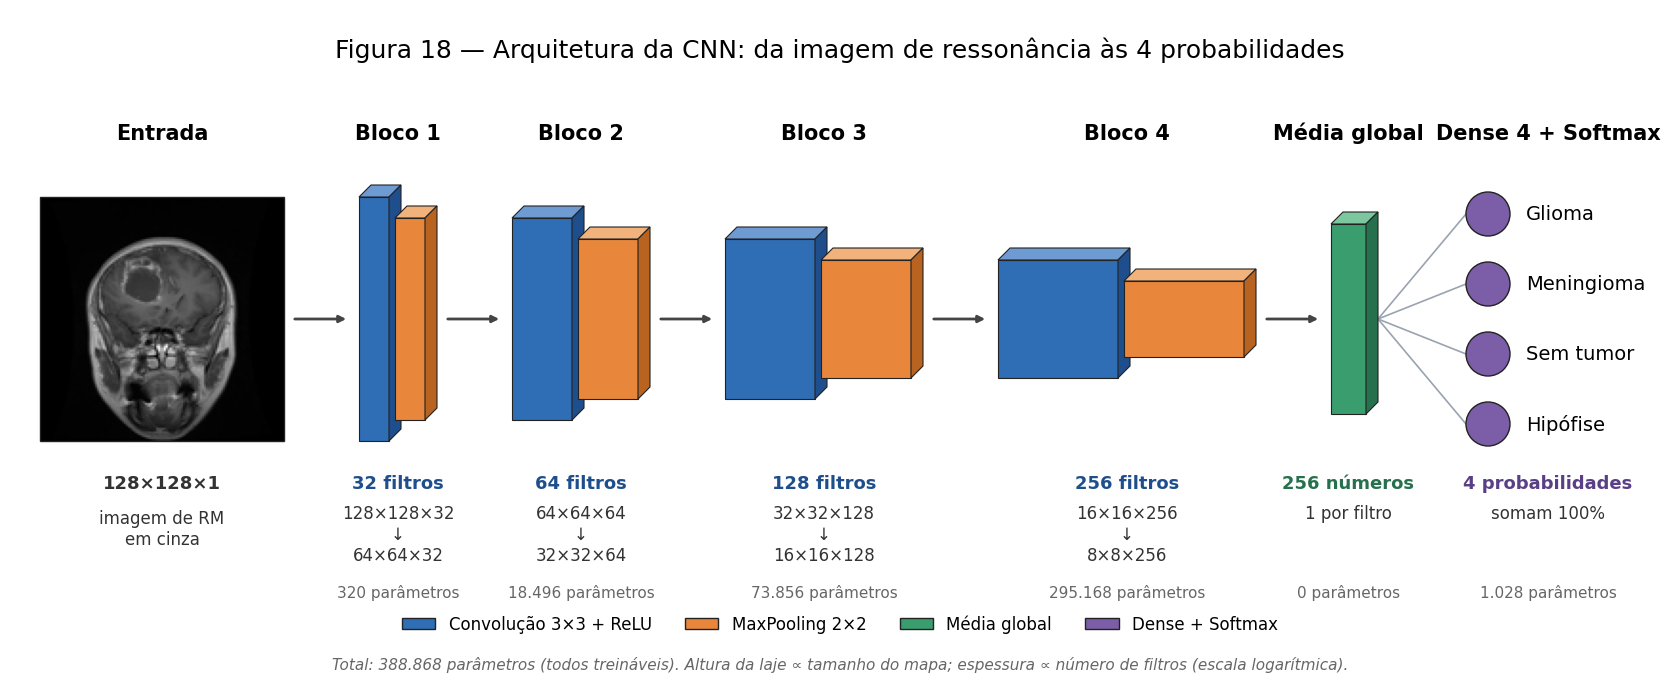

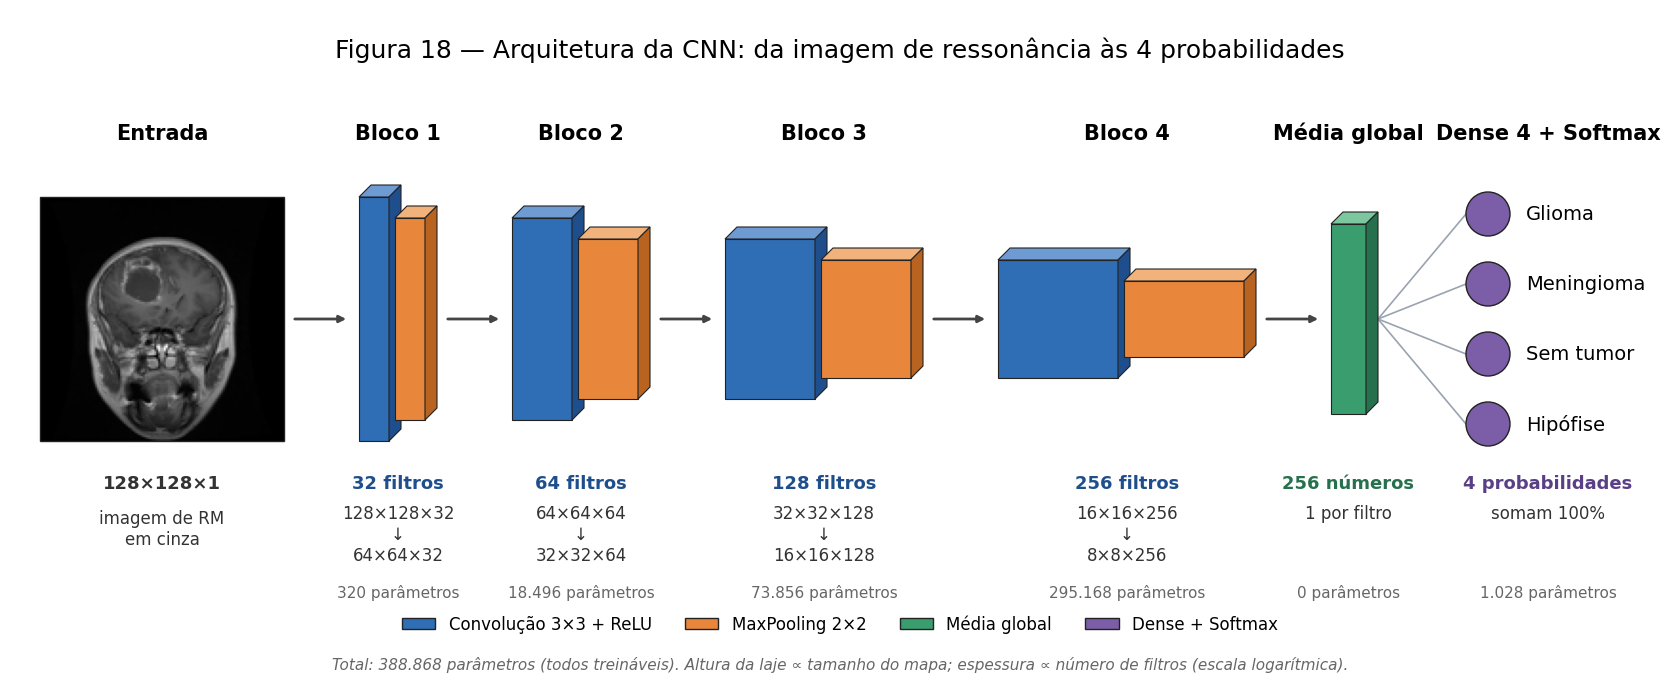

In [154]:
# Figura 18 — Arquitetura completa da CNN (do input às 4 probabilidades)
import math
from matplotlib.patches import Polygon, Circle, Rectangle, Patch

AZUL = ('#2F6DB5', '#6F9BD3', '#1F4E8C')
LARANJA = ('#E8873C', '#F2B27C', '#B8631F')
VERDE = ('#3A9D6E', '#7CC7A0', '#26704D')
ROXO = '#7B5EA7'
CLASSES_PT = ['Glioma', 'Meningioma', 'Sem tumor', 'Hipófise']

yc, dx, dy = 3.7, 0.12, 0.12
altura = lambda s: 0.42 * math.log2(s) - 0.5
milhar = lambda v: f'{v:,}'.replace(',', '.')

fig = plt.figure(figsize=(16.6, 6.8))
ax = fig.add_axes([0, 0, 1, 1])
ax.axis('off')

def laje(x, h, w, cores):
    frente, topo, lado = cores
    y0 = yc - h / 2
    for pontos, cor in [
        ([(x, y0), (x + w, y0), (x + w, y0 + h), (x, y0 + h)], frente),
        ([(x, y0 + h), (x + w, y0 + h), (x + w + dx, y0 + h + dy), (x + dx, y0 + h + dy)], topo),
        ([(x + w, y0), (x + w + dx, y0 + dy), (x + w + dx, y0 + h + dy), (x + w, y0 + h)], lado)]:
        ax.add_patch(Polygon(pontos, closed=True, fc=cor, ec='#222222', lw=0.8, zorder=3))

def seta(xa, xb):
    ax.annotate('', xy=(xb, yc), xytext=(xa, yc),
                arrowprops=dict(arrowstyle='-|>', lw=2, color='#444444'), zorder=4)

def cabecalho(x, texto):
    ax.text(x, 5.5, texto, ha='center', fontsize=15, fontweight='bold')

# entrada: imagem real
lado_img = altura(128)
x = 0.3
y0 = yc - lado_img / 2
ax.imshow(imagem[0, :, :, 0], cmap='gray', extent=(x, x + lado_img, y0, y0 + lado_img),
          aspect='auto', zorder=2)
ax.add_patch(Rectangle((x, y0), lado_img, lado_img, fill=False, ec='#222222', lw=1, zorder=3))
cabecalho(x + lado_img / 2, 'Entrada')
ax.text(x + lado_img / 2, 2.15, '128×128×1', ha='center', va='top', fontsize=13,
        fontweight='bold', color='#333333')
ax.text(x + lado_img / 2, 1.8, 'imagem de RM\nem cinza', ha='center', va='top',
        fontsize=12, color='#333333', linespacing=1.2)
fim_anterior = x + lado_img

# 4 blocos
x = fim_anterior + 0.75
FILTROS = [32, 64, 128, 256]
for k, n in enumerate(FILTROS):
    s = 128 // 2 ** k
    wc = 0.3 * math.log2(n / 16)
    seta(fim_anterior + 0.08, x - 0.1)
    laje(x, altura(s), wc, AZUL)
    laje(x + wc + 0.06, altura(s // 2), wc, LARANJA)
    largura = 2 * wc + 0.06 + dx
    centro = x + largura / 2
    cabecalho(centro, f'Bloco {k + 1}')
    ax.text(centro, 2.15, f'{n} filtros', ha='center', va='top', fontsize=13,
            fontweight='bold', color='#1F4E8C')
    ax.text(centro, 1.85, f'{s}×{s}×{n}\n↓\n{s // 2}×{s // 2}×{n}', ha='center', va='top',
            fontsize=12, color='#333333', linespacing=1.2)
    ax.text(centro, 1.05, f'{milhar(modelo.get_layer(f"conv{k + 1}").count_params())} parâmetros',
            ha='center', va='top', fontsize=11, color='#666666')
    fim_anterior = x + largura
    x = fim_anterior + 0.75

# média global
xg, wg, hg = x, 0.35, 1.9
seta(fim_anterior + 0.08, xg - 0.1)
laje(xg, hg, wg, VERDE)
cabecalho(xg + wg / 2, 'Média global')
ax.text(xg + wg / 2, 2.15, '256 números', ha='center', va='top', fontsize=13,
        fontweight='bold', color='#26704D')
ax.text(xg + wg / 2, 1.85, '1 por filtro', ha='center', va='top', fontsize=12, color='#333333')
ax.text(xg + wg / 2, 1.05, '0 parâmetros', ha='center', va='top', fontsize=11, color='#666666')

# saída: 4 neurônios com Softmax
xo = xg + wg + dx + 1.1
ys = [yc + 1.05, yc + 0.35, yc - 0.35, yc - 1.05]
for yy in ys:
    ax.plot([xg + wg + dx, xo - 0.22], [yc, yy], color='#9AA3AF', lw=1.2, zorder=1)
for yy, nome in zip(ys, CLASSES_PT):
    ax.add_patch(Circle((xo, yy), 0.22, fc=ROXO, ec='#222222', lw=1, zorder=3))
    ax.text(xo + 0.38, yy, nome, va='center', fontsize=14)
cabecalho(xo + 0.6, 'Dense 4 + Softmax')
ax.text(xo + 0.6, 2.15, '4 probabilidades', ha='center', va='top', fontsize=13,
        fontweight='bold', color='#5A3F86')
ax.text(xo + 0.6, 1.85, 'somam 100%', ha='center', va='top', fontsize=12, color='#333333')
ax.text(xo + 0.6, 1.05, f'{milhar(modelo.get_layer("saida").count_params())} parâmetros',
        ha='center', va='top', fontsize=11, color='#666666')

ax.text(8.3, 6.4, 'Figura 18 — Arquitetura da CNN: da imagem de ressonância às 4 probabilidades',
        ha='center', va='center', fontsize=18)

ax.legend(handles=[Patch(fc=AZUL[0], ec='#222222', label='Convolução 3×3 + ReLU'),
                   Patch(fc=LARANJA[0], ec='#222222', label='MaxPooling 2×2'),
                   Patch(fc=VERDE[0], ec='#222222', label='Média global'),
                   Patch(fc=ROXO, ec='#222222', label='Dense + Softmax')],
          loc='lower center', bbox_to_anchor=(0.5, 0.06), ncol=4, frameon=False, fontsize=12)
ax.text(8.3, 0.2, f'Total: {milhar(modelo.count_params())} parâmetros (todos treináveis). '
        'Altura da laje ∝ tamanho do mapa; espessura ∝ número de filtros (escala logarítmica).',
        ha='center', fontsize=11, style='italic', color='#666666')

ax.set_xlim(0, 16.6)
ax.set_ylim(0, 6.8)
fig.savefig(f'{RELATORIO_DIR}/fig18_arquitetura_cnn.png', dpi=200,
            bbox_inches='tight', facecolor='white')
plt.show()# Figura 18 — Arquitetura completa da CNN (do input às 4 probabilidades)
import math
from matplotlib.patches import Polygon, Circle, Rectangle, Patch

AZUL = ('#2F6DB5', '#6F9BD3', '#1F4E8C')
LARANJA = ('#E8873C', '#F2B27C', '#B8631F')
VERDE = ('#3A9D6E', '#7CC7A0', '#26704D')
ROXO = '#7B5EA7'
CLASSES_PT = ['Glioma', 'Meningioma', 'Sem tumor', 'Hipófise']

yc, dx, dy = 3.7, 0.12, 0.12
altura = lambda s: 0.42 * math.log2(s) - 0.5
milhar = lambda v: f'{v:,}'.replace(',', '.')

fig = plt.figure(figsize=(16.6, 6.8))
ax = fig.add_axes([0, 0, 1, 1])
ax.axis('off')

def laje(x, h, w, cores):
    frente, topo, lado = cores
    y0 = yc - h / 2
    for pontos, cor in [
        ([(x, y0), (x + w, y0), (x + w, y0 + h), (x, y0 + h)], frente),
        ([(x, y0 + h), (x + w, y0 + h), (x + w + dx, y0 + h + dy), (x + dx, y0 + h + dy)], topo),
        ([(x + w, y0), (x + w + dx, y0 + dy), (x + w + dx, y0 + h + dy), (x + w, y0 + h)], lado)]:
        ax.add_patch(Polygon(pontos, closed=True, fc=cor, ec='#222222', lw=0.8, zorder=3))

def seta(xa, xb):
    ax.annotate('', xy=(xb, yc), xytext=(xa, yc),
                arrowprops=dict(arrowstyle='-|>', lw=2, color='#444444'), zorder=4)

def cabecalho(x, texto):
    ax.text(x, 5.5, texto, ha='center', fontsize=15, fontweight='bold')

# entrada: imagem real
lado_img = altura(128)
x = 0.3
y0 = yc - lado_img / 2
ax.imshow(imagem[0, :, :, 0], cmap='gray', extent=(x, x + lado_img, y0, y0 + lado_img),
          aspect='auto', zorder=2)
ax.add_patch(Rectangle((x, y0), lado_img, lado_img, fill=False, ec='#222222', lw=1, zorder=3))
cabecalho(x + lado_img / 2, 'Entrada')
ax.text(x + lado_img / 2, 2.15, '128×128×1', ha='center', va='top', fontsize=13,
        fontweight='bold', color='#333333')
ax.text(x + lado_img / 2, 1.8, 'imagem de RM\nem cinza', ha='center', va='top',
        fontsize=12, color='#333333', linespacing=1.2)
fim_anterior = x + lado_img

# 4 blocos
x = fim_anterior + 0.75
FILTROS = [32, 64, 128, 256]
for k, n in enumerate(FILTROS):
    s = 128 // 2 ** k
    wc = 0.3 * math.log2(n / 16)
    seta(fim_anterior + 0.08, x - 0.1)
    laje(x, altura(s), wc, AZUL)
    laje(x + wc + 0.06, altura(s // 2), wc, LARANJA)
    largura = 2 * wc + 0.06 + dx
    centro = x + largura / 2
    cabecalho(centro, f'Bloco {k + 1}')
    ax.text(centro, 2.15, f'{n} filtros', ha='center', va='top', fontsize=13,
            fontweight='bold', color='#1F4E8C')
    ax.text(centro, 1.85, f'{s}×{s}×{n}\n↓\n{s // 2}×{s // 2}×{n}', ha='center', va='top',
            fontsize=12, color='#333333', linespacing=1.2)
    ax.text(centro, 1.05, f'{milhar(modelo.get_layer(f"conv{k + 1}").count_params())} parâmetros',
            ha='center', va='top', fontsize=11, color='#666666')
    fim_anterior = x + largura
    x = fim_anterior + 0.75

# média global
xg, wg, hg = x, 0.35, 1.9
seta(fim_anterior + 0.08, xg - 0.1)
laje(xg, hg, wg, VERDE)
cabecalho(xg + wg / 2, 'Média global')
ax.text(xg + wg / 2, 2.15, '256 números', ha='center', va='top', fontsize=13,
        fontweight='bold', color='#26704D')
ax.text(xg + wg / 2, 1.85, '1 por filtro', ha='center', va='top', fontsize=12, color='#333333')
ax.text(xg + wg / 2, 1.05, '0 parâmetros', ha='center', va='top', fontsize=11, color='#666666')

# saída: 4 neurônios com Softmax
xo = xg + wg + dx + 1.1
ys = [yc + 1.05, yc + 0.35, yc - 0.35, yc - 1.05]
for yy in ys:
    ax.plot([xg + wg + dx, xo - 0.22], [yc, yy], color='#9AA3AF', lw=1.2, zorder=1)
for yy, nome in zip(ys, CLASSES_PT):
    ax.add_patch(Circle((xo, yy), 0.22, fc=ROXO, ec='#222222', lw=1, zorder=3))
    ax.text(xo + 0.38, yy, nome, va='center', fontsize=14)
cabecalho(xo + 0.6, 'Dense 4 + Softmax')
ax.text(xo + 0.6, 2.15, '4 probabilidades', ha='center', va='top', fontsize=13,
        fontweight='bold', color='#5A3F86')
ax.text(xo + 0.6, 1.85, 'somam 100%', ha='center', va='top', fontsize=12, color='#333333')
ax.text(xo + 0.6, 1.05, f'{milhar(modelo.get_layer("saida").count_params())} parâmetros',
        ha='center', va='top', fontsize=11, color='#666666')

ax.text(8.3, 6.4, 'Figura 18 — Arquitetura da CNN: da imagem de ressonância às 4 probabilidades',
        ha='center', va='center', fontsize=18)

ax.legend(handles=[Patch(fc=AZUL[0], ec='#222222', label='Convolução 3×3 + ReLU'),
                   Patch(fc=LARANJA[0], ec='#222222', label='MaxPooling 2×2'),
                   Patch(fc=VERDE[0], ec='#222222', label='Média global'),
                   Patch(fc=ROXO, ec='#222222', label='Dense + Softmax')],
          loc='lower center', bbox_to_anchor=(0.5, 0.06), ncol=4, frameon=False, fontsize=12)
ax.text(8.3, 0.2, f'Total: {milhar(modelo.count_params())} parâmetros (todos treináveis). '
        'Altura da laje ∝ tamanho do mapa; espessura ∝ número de filtros (escala logarítmica).',
        ha='center', fontsize=11, style='italic', color='#666666')

ax.set_xlim(0, 16.6)
ax.set_ylim(0, 6.8)
fig.savefig(f'{RELATORIO_DIR}/fig18_arquitetura_cnn.png', dpi=200,
            bbox_inches='tight', facecolor='white')
plt.show()

**Observação — Passo 21 (diagrama da arquitetura)**

**A rede de ponta a ponta.** A imagem de entrada (128×128×1) atravessa quatro blocos de convolução 3×3 com ReLU (azul) seguida de MaxPooling 2×2 (laranja), com 32, 64, 128 e 256 filtros. A convolução mantém o tamanho do mapa e o pooling o reduz à metade (128 → 64, 64 → 32, 32 → 16, 16 → 8). A média global resume os 256 mapas finais em 256 números, e a camada Dense com Softmax devolve as 4 probabilidades: glioma, meningioma, sem tumor e hipófise.

**Parâmetros.** Os blocos têm 320, 18.496, 73.856 e 295.168 parâmetros; a média global não tem nenhum e a camada de saída tem 1.028, num total de 388.868 (todos treináveis). A altura de cada laje é proporcional ao tamanho do mapa e a espessura ao número de filtros, de modo que o diagrama mostra o "onde" se comprimindo (mapa de 128×128 a 8×8) enquanto o "o quê" se expande (de 1 a 256 canais).

**Fim da Fase 3.** A rede está construída, conferida (Passo 17) e configurada para o treino (Passos 18 a 20). A Fase 4 começa com o primeiro treino, usando o conjunto de treino para ajustar os pesos e o de validação para acompanhar o desempenho e escolher a melhor época, seguido dos experimentos de ajuste, um fator de cada vez.

**Observação — Passo 22 (como os blocos se conectam)**

**Convolução: todos com todos.** As linhas cruzadas da Figura 19 mostram que cada filtro de um bloco enxerga todos os mapas do bloco anterior. O número de kernels 3×3 por bloco é o produto entre os canais de entrada e os de saída: 1×32 = 32, 32×64 = 2.048, 64×128 = 8.192 e 128×256 = 32.768, ou seja, cerca de quatro vezes mais a cada bloco. Com 9 pesos por kernel mais um bias por filtro, isso reproduz exatamente os parâmetros do modelo: 32×9 + 32 = 320; 2.048×9 + 64 = 18.496; 8.192×9 + 128 = 73.856; e 32.768×9 + 256 = 295.168. Somando, são 43.040 kernels e 387.840 parâmetros nos blocos.

**Média global e saída.** Na média global as linhas são retas: cada mapa é resumido em um único número (nos 6 mapas desenhados, os valores ficaram entre cerca de 1,2 e 1,4), sem misturar mapas diferentes. A camada Dense então liga todos os 256 números a cada uma das 4 saídas, com 256×4 pesos mais 4 biases (1.028 parâmetros).

**Leitura.** O crescimento de quatro vezes por bloco explica por que a última convolução concentra 76% dos parâmetros da rede, e mostra de onde vem a capacidade do modelo: não de ter muitas camadas, mas de combinar, em cada bloco, todos os mapas do anterior. Os mapas desenhados são reais, mas a rede ainda não foi treinada.

**Fim da Fase 3.** A rede está construída, conferida (Passo 17), configurada para o treino (Passos 18 a 20) e documentada nos diagramas (Passos 21 e 22). A Fase 4 começa com o primeiro treino, usando o conjunto de treino para ajustar os pesos e o de validação para acompanhar o desempenho e escolher a melhor época, seguido dos experimentos de ajuste, um fator de cada vez.

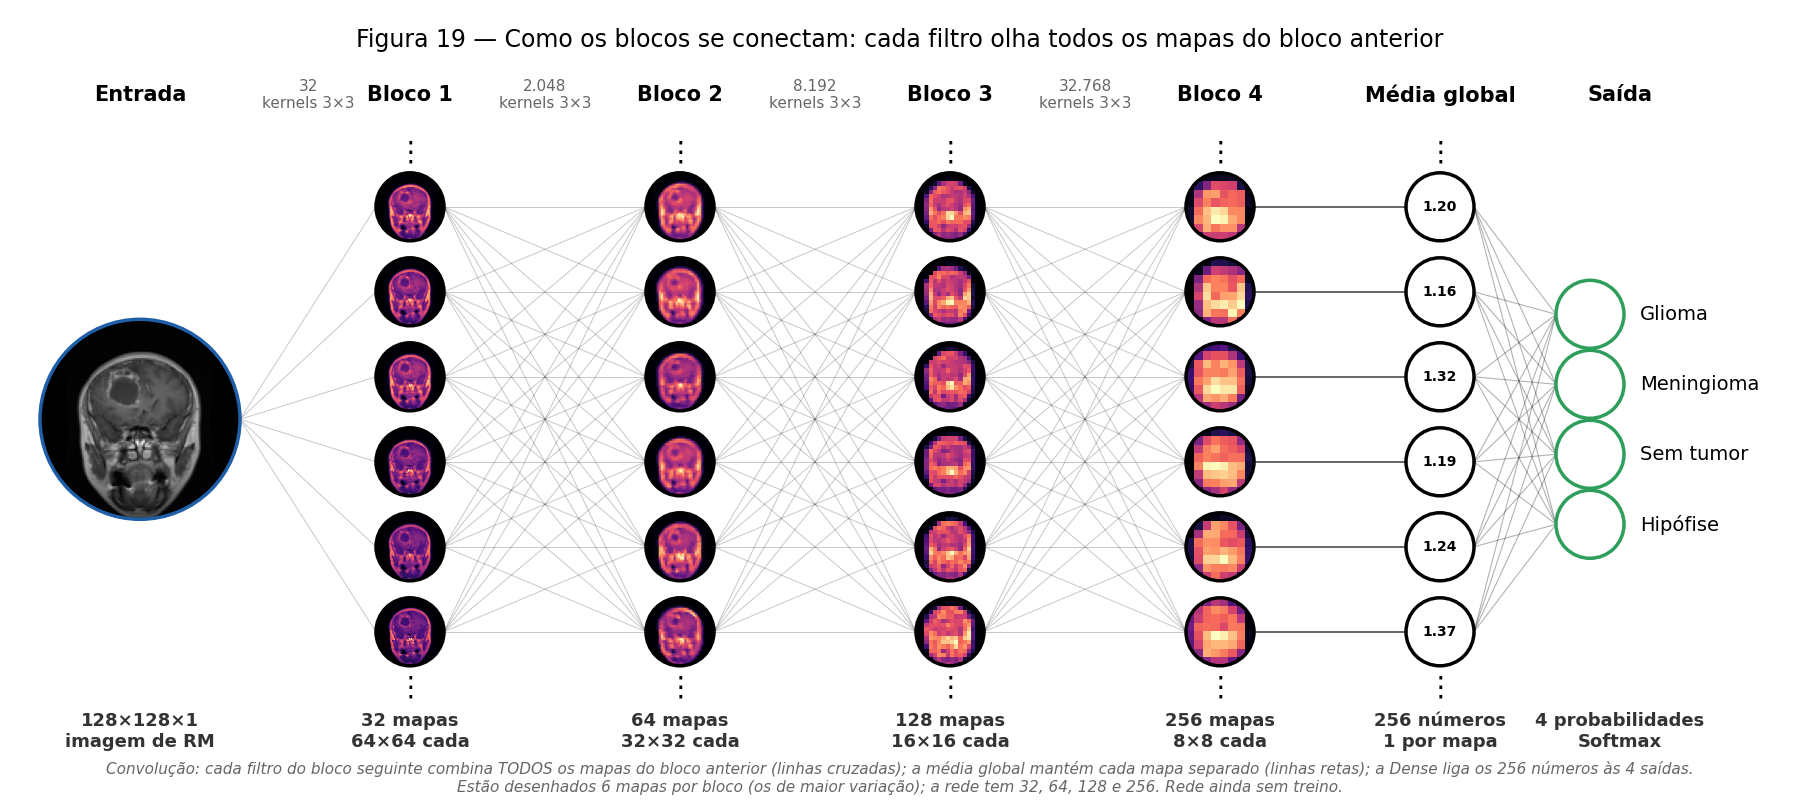

In [155]:
# Figura 19 — Como os blocos se conectam (estilo rede neural: círculos e ligações)
from matplotlib.patches import Circle

milhar = lambda v: f'{v:,}'.replace(',', '.')
AZUL, VERDE = '#1F5FA8', '#2E9E5B'
CLASSES_PT = ['Glioma', 'Meningioma', 'Sem tumor', 'Hipófise']
NOS, yc, r = 6, 3.7, 0.34
ys = yc + (np.arange(NOS) - (NOS - 1) / 2)[::-1] * 0.85       # de cima para baixo
FILTROS = [32, 64, 128, 256]
X_BLOCOS = [4.0, 6.7, 9.4, 12.1]

fig = plt.figure(figsize=(17.8, 7.8))
ax = fig.add_axes([0, 0, 1, 1])
ax.axis('off')

def no_mapa(x, yy, mapa, raio, cor, cmap='magma'):
    vmax = float(mapa.max()) if mapa.max() > 0 else 1.0
    im = ax.imshow(mapa, cmap=cmap, extent=(x - raio, x + raio, yy - raio, yy + raio),
                   aspect='auto', vmin=0, vmax=vmax, zorder=3)
    im.set_clip_path(Circle((x, yy), raio, transform=ax.transData))
    ax.add_patch(Circle((x, yy), raio, fill=False, ec=cor, lw=2.5, zorder=5))

def ligar(origem, destino, alpha=0.22, lw=0.7):
    for xa, ya in origem:
        for xb, yb in destino:
            ax.plot([xa, xb], [ya, yb], color='black', alpha=alpha, lw=lw, zorder=1)

def reticencias(x):
    ax.text(x, ys[0] + 0.55, '⋮', ha='center', va='center', fontsize=20, zorder=5)
    ax.text(x, ys[-1] - 0.55, '⋮', ha='center', va='center', fontsize=20, zorder=5)

# entrada
ax.text(1.3, 6.95, 'Entrada', ha='center', va='center', fontsize=15, fontweight='bold')
no_mapa(1.3, yc, imagem[0, :, :, 0], 1.0, AZUL, cmap='gray')
ax.text(1.3, 0.78, '128×128×1\nimagem de RM', ha='center', va='top', fontsize=13,
        fontweight='bold', color='#333333')
origem = [(2.3, yc)]

# blocos
escolhidos = []
for k, (xb, n) in enumerate(zip(X_BLOCOS, FILTROS)):
    mapa = mapas_blocos[k]
    ordem = np.argsort(-mapa.std(axis=(0, 1)))[:NOS]
    escolhidos.append(ordem)
    cin, cout = modelo.get_layer(f'conv{k + 1}').get_weights()[0].shape[2:]
    xm = (origem[0][0] + xb - r) / 2
    ax.text(xm, 6.95, f'{milhar(int(cin * cout))}\nkernels 3×3', ha='center', va='center',
            fontsize=11, color='#666666', linespacing=1.2)
    ligar(origem, [(xb - r, yy) for yy in ys])
    for yy, c in zip(ys, ordem):
        no_mapa(xb, yy, mapa[:, :, c], r, 'black')
    reticencias(xb)
    origem = [(xb + r, yy) for yy in ys]
    ax.text(xb, 6.95, f'Bloco {k + 1}', ha='center', va='center', fontsize=15, fontweight='bold')
    ax.text(xb, 0.78, f'{n} mapas\n{mapa.shape[0]}×{mapa.shape[1]} cada', ha='center', va='top',
            fontsize=13, fontweight='bold', color='#333333')

# média global: um mapa vira um número
xg = 14.3
for (xa, ya), yy, c in zip(origem, ys, escolhidos[3]):
    ax.plot([xa, xg - r], [ya, yy], color='black', alpha=0.6, lw=1.4, zorder=1)
    ax.add_patch(Circle((xg, yy), r, fc='white', ec='black', lw=2.5, zorder=4))
    ax.text(xg, yy, f'{mapas_blocos[3][:, :, c].mean():.2f}', ha='center', va='center',
            fontsize=10, fontweight='bold', zorder=5)
reticencias(xg)
ax.text(xg, 6.95, 'Média global', ha='center', va='center', fontsize=15, fontweight='bold')
ax.text(xg, 0.78, '256 números\n1 por mapa', ha='center', va='top', fontsize=13,
        fontweight='bold', color='#333333')

# saída: Dense com Softmax
xo = 15.8
yo = yc + np.array([1.05, 0.35, -0.35, -1.05])
ligar([(xg + r, yy) for yy in ys], [(xo - r, yy) for yy in yo], alpha=0.3, lw=0.8)
for yy, nome in zip(yo, CLASSES_PT):
    ax.add_patch(Circle((xo, yy), r, fc='white', ec=VERDE, lw=2.5, zorder=4))
    ax.text(xo + 0.5, yy, nome, va='center', fontsize=14)
ax.text(xo + 0.3, 6.95, 'Saída', ha='center', va='center', fontsize=15, fontweight='bold')
ax.text(xo + 0.3, 0.78, '4 probabilidades\nSoftmax', ha='center', va='top', fontsize=13,
        fontweight='bold', color='#333333')

ax.text(8.9, 7.5, 'Figura 19 — Como os blocos se conectam: cada filtro olha todos os mapas do bloco anterior',
        ha='center', va='center', fontsize=17)
ax.text(8.9, 0.12, 'Convolução: cada filtro do bloco seguinte combina TODOS os mapas do bloco anterior (linhas cruzadas); '
        'a média global mantém cada mapa separado (linhas retas); a Dense liga os 256 números às 4 saídas.\n'
        'Estão desenhados 6 mapas por bloco (os de maior variação); a rede tem 32, 64, 128 e 256. Rede ainda sem treino.',
        ha='center', va='center', fontsize=11, style='italic', color='#666666')

ax.set_xlim(0, 17.8)
ax.set_ylim(0, 7.8)
fig.savefig(f'{RELATORIO_DIR}/fig19_conexoes_entre_blocos.png', dpi=200,
            bbox_inches='tight', facecolor='white')
plt.show()

# Fase 4 — Treinamento, ajuste e avaliação

## Passo 23 — Primeiro treino (baseline)

Treinamos a rede exatamente como configurada no Passo 20 (Adam com taxa 0,001, lote de 32, até 30 épocas, melhor modelo pela acurácia de validação), sem nenhuma técnica extra de regularização nem aumento de dados. Este é o ponto de partida (baseline): todos os experimentos seguintes serão comparados com ele.

**Como ler as curvas de aprendizado** (perda e acurácia por época, no treino e na validação):
- **Treino e validação melhoram juntos:** a rede aprende de forma que generaliza.
- **O treino continua melhorando e a validação estaciona ou piora:** sobreajuste (overfitting), a rede começa a decorar o treino.
- **As duas ficam ruins e estacionadas:** subajuste (underfitting), falta capacidade ou tempo de treino.

A linha tracejada nas figuras marca a melhor época, cujo modelo fica guardado na pasta `modelos/`.

In [156]:
# Passo 23 — Primeiro treino (baseline): configuração do Passo 20, sem regularização
import time

x_tr, y_tr = X['treino'].astype('float32'), y['treino'].astype('int32')
x_va, y_va = X['validacao'].astype('float32'), y['validacao'].astype('int32')

modelo_base = compilar(construir_modelo())
inicio = time.time()
hist_base = modelo_base.fit(x_tr, y_tr, batch_size=CONFIG['batch'], epochs=CONFIG['epocas_max'],
                            validation_data=(x_va, y_va), callbacks=callbacks_padrao('baseline'),
                            shuffle=True, verbose=2)
print(f'\nTempo de treino: {(time.time() - inicio) / 60:.1f} min')

h = pd.DataFrame(hist_base.history)
h.index = h.index + 1
h.index.name = 'época'
ep_melhor = int(h['val_accuracy'].idxmax())
print(f'Melhor época (maior acurácia de validação): {ep_melhor}')
print(f'  treino:    acurácia {h.loc[ep_melhor, "accuracy"]:.3f} | perda {h.loc[ep_melhor, "loss"]:.3f}')
print(f'  validação: acurácia {h.loc[ep_melhor, "val_accuracy"]:.3f} | perda {h.loc[ep_melhor, "val_loss"]:.3f}')
h.to_csv(f'{RELATORIO_DIR}/hist_baseline.csv', encoding='utf-8-sig')

Epoch 1/30
123/123 - 13s - 108ms/step - accuracy: 0.5457 - loss: 1.0617 - val_accuracy: 0.6962 - val_loss: 0.7563
Epoch 2/30
123/123 - 3s - 24ms/step - accuracy: 0.7043 - loss: 0.7326 - val_accuracy: 0.7380 - val_loss: 0.6817
Epoch 3/30
123/123 - 3s - 23ms/step - accuracy: 0.7513 - loss: 0.6396 - val_accuracy: 0.7839 - val_loss: 0.6243
Epoch 4/30
123/123 - 3s - 23ms/step - accuracy: 0.7803 - loss: 0.5675 - val_accuracy: 0.7944 - val_loss: 0.6142
Epoch 5/30
123/123 - 3s - 24ms/step - accuracy: 0.8002 - loss: 0.5174 - val_accuracy: 0.8330 - val_loss: 0.4902
Epoch 6/30
123/123 - 3s - 24ms/step - accuracy: 0.8217 - loss: 0.4668 - val_accuracy: 0.8455 - val_loss: 0.4500
Epoch 7/30
123/123 - 5s - 41ms/step - accuracy: 0.8378 - loss: 0.4232 - val_accuracy: 0.8612 - val_loss: 0.4270
Epoch 8/30
123/123 - 3s - 23ms/step - accuracy: 0.8534 - loss: 0.3868 - val_accuracy: 0.8664 - val_loss: 0.4051
Epoch 9/30
123/123 - 3s - 24ms/step - accuracy: 0.8672 - loss: 0.3534 - val_accuracy: 0.8758 - val_los

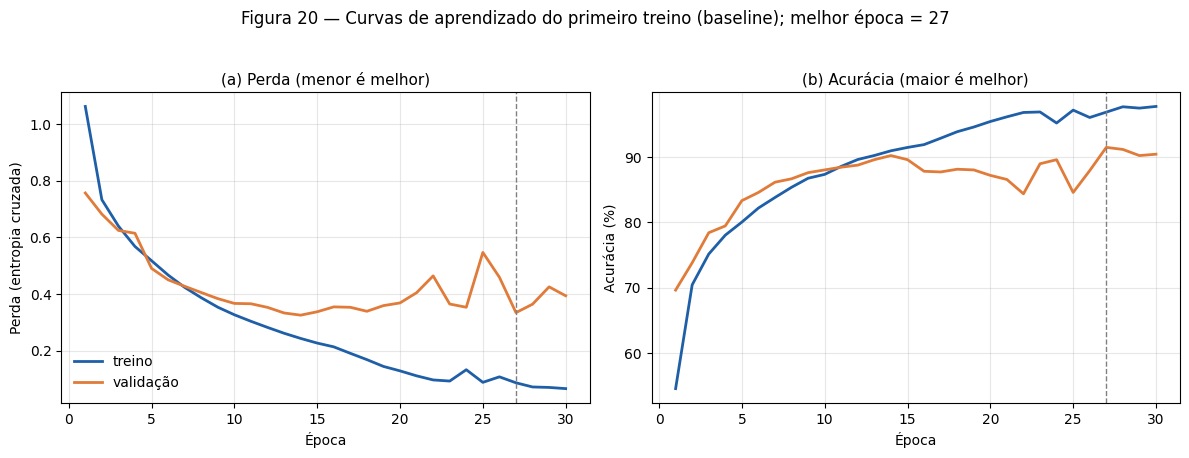

In [157]:
# Figura 20 — Curvas de aprendizado do baseline
ep = h.index
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))

ax1.plot(ep, h['loss'], color='#1F5FA8', lw=2, label='treino')
ax1.plot(ep, h['val_loss'], color='#E07B39', lw=2, label='validação')
ax1.set_title('(a) Perda (menor é melhor)', fontsize=11)
ax1.set_ylabel('Perda (entropia cruzada)')

ax2.plot(ep, 100 * h['accuracy'], color='#1F5FA8', lw=2, label='treino')
ax2.plot(ep, 100 * h['val_accuracy'], color='#E07B39', lw=2, label='validação')
ax2.set_title('(b) Acurácia (maior é melhor)', fontsize=11)
ax2.set_ylabel('Acurácia (%)')

for ax in (ax1, ax2):
    ax.axvline(ep_melhor, ls='--', color='gray', lw=1)
    ax.set_xlabel('Época')
    ax.grid(alpha=0.3)
ax1.legend(frameon=False)
fig.suptitle(f'Figura 20 — Curvas de aprendizado do primeiro treino (baseline); melhor época = {ep_melhor}',
             fontsize=12, y=1.03)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig20_curvas_baseline.png', dpi=200, bbox_inches='tight')
plt.show()

**Observação — Passo 23 (primeiro treino, baseline)**

**Resultado.** O treino de 30 épocas levou 1,7 minuto. A melhor época, pela acurácia de validação, foi a 27: acurácia de 96,8% no treino e 91,4% na validação, com perda de 0,087 no treino e 0,334 na validação. A rede aprende bem (a acurácia de validação parte de cerca de 70% na primeira época e passa de 90%), mas há uma diferença de cerca de 5 pontos entre treino e validação.

**Figura 20.** A perda de treino cai continuamente (até cerca de 0,07), enquanto a de validação atinge o mínimo (cerca de 0,33) entre as épocas 10 e 15 e depois oscila e sobe, sem acompanhar o treino. Esse afastamento é o sinal típico de sobreajuste (overfitting): a rede passa a decorar o treino. A acurácia de validação oscila entre cerca de 85% e 92% de uma época para outra.

**Ruído da medida.** Com 958 imagens de validação, a incerteza da acurácia é de aproximadamente ±0,9 ponto percentual (erro-padrão), e a escolha da melhor época entre valores oscilantes é levemente otimista. Por isso, nos experimentos seguintes cada configuração será treinada com três sementes e só diferenças claras serão interpretadas.

**Consequência.** O baseline é um bom ponto de partida, mas o sobreajuste justifica testar a taxa de aprendizado e técnicas de regularização (Dropout e aumento de dados), um fator de cada vez.

## Passo 24 — Experimento 1: taxa de aprendizado

Comparamos três taxas de aprendizado do Adam (0,01; 0,001, o baseline; e 0,0001), mantendo todo o resto igual. Como uma única execução depende do sorteio dos pesos iniciais, cada configuração é treinada com três sementes (42, 43 e 44) e comparamos as médias.

**Medidas por treino:** melhor acurácia de validação (e a época em que ocorreu), acurácia de validação na última época (menos sujeita à escolha da melhor época) e acurácia de treino na última época. Como a incerteza da validação é de cerca de ±0,9 ponto, só diferenças claras serão interpretadas.

Os resultados de todos os experimentos da Fase 4 são acumulados na lista `resultados`, que alimenta a tabela comparativa final.

In [158]:
# Passo 24 — Experimento 1: taxa de aprendizado, com 3 sementes cada
import time

resultados = []          # acumula todos os experimentos da Fase 4
curvas = {}              # curvas de cada treino

def treinar(nome, lr=1e-3, semente=SEED, epocas=CONFIG['epocas_max'], **kw):
    m_exp = compilar(construir_modelo(semente=semente), lr=lr)
    hist = m_exp.fit(x_tr, y_tr, batch_size=CONFIG['batch'], epochs=epocas,
                     validation_data=(x_va, y_va), shuffle=True, verbose=0, **kw)
    d = pd.DataFrame(hist.history)
    d.index = d.index + 1
    resultados.append({'experimento': nome, 'semente': semente,
                       'melhor_val_acc': 100 * d['val_accuracy'].max(),
                       'época_melhor': int(d['val_accuracy'].idxmax()),
                       'val_acc_final': 100 * d['val_accuracy'].iloc[-1],
                       'train_acc_final': 100 * d['accuracy'].iloc[-1]})
    curvas[(nome, semente)] = d
    return d

def resumo():
    r = pd.DataFrame(resultados)
    return r.groupby('experimento', sort=False).agg(
        melhor_val_acc=('melhor_val_acc', 'mean'), desvio=('melhor_val_acc', 'std'),
        val_acc_final=('val_acc_final', 'mean'),
        train_acc_final=('train_acc_final', 'mean')).round(2)

SEMENTES = [42, 43, 44]
for nome, lr in [('lr 0,01', 1e-2), ('lr 0,001 (baseline)', 1e-3), ('lr 0,0001', 1e-4)]:
    for s in SEMENTES:
        t0 = time.time()
        d = treinar(nome, lr=lr, semente=s)
        print(f'{nome} | semente {s}: melhor val acc {100 * d["val_accuracy"].max():.1f}% '
              f'| {(time.time() - t0) / 60:.1f} min')

tab_lr = resumo()
display(tab_lr)
tab_lr.to_csv(f'{RELATORIO_DIR}/tab11_experimento_lr.csv', encoding='utf-8-sig')

lr 0,01 | semente 42: melhor val acc 84.7% | 1.6 min
lr 0,01 | semente 43: melhor val acc 86.6% | 1.6 min
lr 0,01 | semente 44: melhor val acc 87.5% | 1.6 min
lr 0,001 (baseline) | semente 42: melhor val acc 91.3% | 1.6 min
lr 0,001 (baseline) | semente 43: melhor val acc 91.9% | 1.7 min
lr 0,001 (baseline) | semente 44: melhor val acc 92.0% | 1.6 min
lr 0,0001 | semente 42: melhor val acc 83.6% | 1.6 min
lr 0,0001 | semente 43: melhor val acc 80.7% | 1.7 min
lr 0,0001 | semente 44: melhor val acc 83.8% | 1.7 min


,melhor_val_acc,desvio,val_acc_final,train_acc_final
experimento,,,,
"lr 0,01",86.26,1.45,82.36,90.88
"lr 0,001 (baseline)",91.72,0.34,88.73,97.40
"lr 0,0001",82.71,1.75,82.71,83.40


**Observação — Passo 24 (taxa de aprendizado)**

**Resultados.** Em média de três sementes, a melhor acurácia de validação foi de 86,3% com taxa 0,01 (desvio 1,45), 91,7% com 0,001 (desvio 0,34, o baseline) e 82,7% com 0,0001 (desvio 1,75). A diferença do baseline para as outras duas (5,5 e 9,0 pontos) é muito maior que a incerteza da medida (cerca de ±0,9 ponto), e portanto é clara.

**Leitura.** Com 0,01 o passo é grande demais: a acurácia de treino na última época foi de apenas 90,9% e a de validação oscilou (82,4% na última época contra 86,3% na melhor), sinal de treino instável. Com 0,0001 o passo é pequeno demais para 30 épocas: treino e validação terminam juntos, em cerca de 83%, o que caracteriza subajuste (a rede ainda não aprendeu o suficiente; com muito mais épocas talvez melhorasse, mas custaria tempo). Com 0,001, o treino chega a 97,4% e a validação a 91,7% (melhor época) e 88,7% (última época); a diferença entre treino e validação e a oscilação entre a melhor época e a última confirmam o sobreajuste já visto no baseline.

**Estabilidade.** Com três sementes diferentes, o baseline ficou entre 91,3% e 92,0%, o que mostra que o resultado do Passo 23 não foi sorte.

**Decisão.** Manter a taxa de aprendizado 0,001. Os próximos experimentos atacam o sobreajuste.

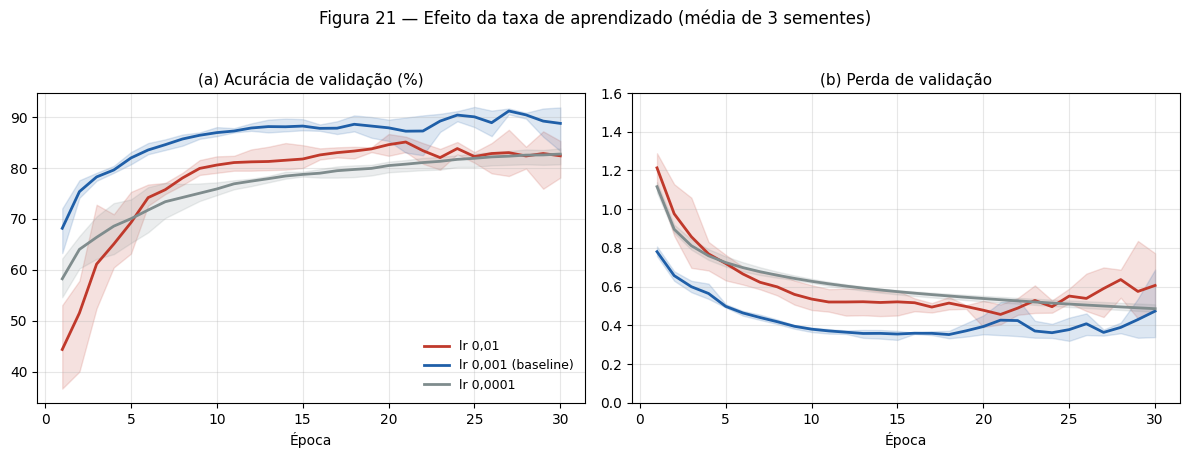

In [159]:
# Figura 21 — Taxa de aprendizado: média de 3 sementes (faixa = mínimo e máximo)
confs = [('lr 0,01', '#C0392B'), ('lr 0,001 (baseline)', '#1F5FA8'), ('lr 0,0001', '#7F8C8D')]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
for nome, cor in confs:
    va = np.array([100 * curvas[(nome, s)]['val_accuracy'].values for s in SEMENTES])
    vl = np.array([curvas[(nome, s)]['val_loss'].values for s in SEMENTES])
    ep = np.arange(1, va.shape[1] + 1)
    ax1.plot(ep, va.mean(axis=0), color=cor, lw=2, label=nome)
    ax1.fill_between(ep, va.min(axis=0), va.max(axis=0), color=cor, alpha=0.15)
    ax2.plot(ep, vl.mean(axis=0), color=cor, lw=2, label=nome)
    ax2.fill_between(ep, vl.min(axis=0), vl.max(axis=0), color=cor, alpha=0.15)
ax1.set_title('(a) Acurácia de validação (%)', fontsize=11)
ax2.set_title('(b) Perda de validação', fontsize=11)
ax2.set_ylim(0, 1.6)
for ax in (ax1, ax2):
    ax.set_xlabel('Época')
    ax.grid(alpha=0.3)
ax1.legend(frameon=False, loc='lower right', fontsize=9)
fig.suptitle('Figura 21 — Efeito da taxa de aprendizado (média de 3 sementes)', fontsize=12, y=1.03)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig21_taxa_aprendizado_exp.png', dpi=200, bbox_inches='tight')
plt.show()

**Curvas (Figura 21).** Com taxa 0,01, a acurácia de validação sobe devagar e oscila bastante, e a faixa entre a melhor e a pior semente é larga; a perda de validação chega a subir no final. Com 0,0001, a curva sobe de forma suave, mas fica abaixo das demais e a perda ainda cai bem devagar ao final das 30 épocas. Com 0,001, a acurácia sobe mais rápido e termina mais alta, e a perda é a menor das três. Nas últimas épocas, porém, a perda do baseline volta a subir um pouco, mais um sinal de sobreajuste (o que vamos atacar a partir do Passo 25).

## Passo 25 — Experimento 2: Dropout

O Dropout desliga ao acaso uma fração dos valores durante o treino (e fica totalmente desligado na validação e no teste). Assim, a rede não pode depender de um caminho específico e aprende pistas mais redundantes e robustas, o que combate o sobreajuste observado nos Passos 23 e 24. Não adiciona parâmetros.

**Variantes testadas** (taxa de aprendizado 0,001, três sementes cada, comparadas ao baseline do Passo 24):
1. Dropout de 0,3 apenas na saída (após a média global).
2. Dropout de 0,2 após cada bloco convolucional mais 0,3 na saída.

Para este e os experimentos seguintes, a função `construir_modelo_reg` monta a mesma arquitetura com opções de Dropout e de aumento de dados, e `treinar_reg` registra cada treino na lista `resultados`.

In [160]:
# Passo 25 — Experimento 2: Dropout (3 sementes cada)
import time

def construir_modelo_reg(filtros=(32, 64, 128, 256), dropout_blocos=0.0, dropout_saida=0.0,
                         aumento=None, semente=SEED):
    keras.utils.set_random_seed(semente)
    entrada = keras.Input(shape=(128, 128, 1), name='imagem')
    x = entrada
    if aumento is not None:
        x = aumento(x)                       # só atua durante o treino
    x = layers.Rescaling(1.0 / 255)(x)
    for n in filtros:
        x = layers.Conv2D(n, 3, padding='same', kernel_initializer='he_normal')(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D(2)(x)
        if dropout_blocos > 0:
            x = layers.Dropout(dropout_blocos)(x)
    x = layers.GlobalAveragePooling2D()(x)
    if dropout_saida > 0:
        x = layers.Dropout(dropout_saida)(x)
    saida = layers.Dense(4, activation='softmax')(x)
    return keras.Model(entrada, saida)

def treinar_reg(nome, semente=SEED, lr=1e-3, epocas=CONFIG['epocas_max'], pesos_classe=None, **opcoes):
    m_exp = compilar(construir_modelo_reg(semente=semente, **opcoes), lr=lr)
    hist = m_exp.fit(x_tr, y_tr, batch_size=CONFIG['batch'], epochs=epocas,
                     validation_data=(x_va, y_va), shuffle=True, verbose=0,
                     class_weight=pesos_classe)
    d = pd.DataFrame(hist.history)
    d.index = d.index + 1
    resultados.append({'experimento': nome, 'semente': semente,
                       'melhor_val_acc': 100 * d['val_accuracy'].max(),
                       'época_melhor': int(d['val_accuracy'].idxmax()),
                       'val_acc_final': 100 * d['val_accuracy'].iloc[-1],
                       'train_acc_final': 100 * d['accuracy'].iloc[-1]})
    curvas[(nome, semente)] = d
    return d

variantes = [('Dropout 0,3 (saída)', dict(dropout_saida=0.3)),
             ('Dropout 0,2 (blocos) + 0,3 (saída)', dict(dropout_blocos=0.2, dropout_saida=0.3))]
for nome, op in variantes:
    for s in SEMENTES:
        t0 = time.time()
        d = treinar_reg(nome, semente=s, **op)
        print(f'{nome} | semente {s}: melhor val acc {100 * d["val_accuracy"].max():.1f}% '
              f'| {(time.time() - t0) / 60:.1f} min')

tab_exp = resumo()
display(tab_exp)
tab_exp.to_csv(f'{RELATORIO_DIR}/tab12_experimentos_parcial.csv', encoding='utf-8-sig')

Dropout 0,3 (saída) | semente 42: melhor val acc 90.6% | 1.6 min
Dropout 0,3 (saída) | semente 43: melhor val acc 91.9% | 1.6 min
Dropout 0,3 (saída) | semente 44: melhor val acc 92.3% | 1.6 min


KeyboardInterrupt: 

In [161]:
# Continuação do Passo 25 — só a variante 2 (a variante 1 já está pronta)
nome, op = 'Dropout 0,2 (blocos) + 0,3 (saída)', dict(dropout_blocos=0.2, dropout_saida=0.3)
for s in SEMENTES:
    t0 = time.time()
    d = treinar_reg(nome, semente=s, **op)
    print(f'{nome} | semente {s}: melhor val acc {100 * d["val_accuracy"].max():.1f}% '
          f'| {(time.time() - t0) / 60:.1f} min')

tab_exp = resumo()
display(tab_exp)
tab_exp.to_csv(f'{RELATORIO_DIR}/tab12_experimentos_parcial.csv', encoding='utf-8-sig')

Dropout 0,2 (blocos) + 0,3 (saída) | semente 42: melhor val acc 88.6% | 1.8 min
Dropout 0,2 (blocos) + 0,3 (saída) | semente 43: melhor val acc 91.2% | 1.8 min
Dropout 0,2 (blocos) + 0,3 (saída) | semente 44: melhor val acc 91.9% | 1.7 min


,melhor_val_acc,desvio,val_acc_final,train_acc_final
experimento,,,,
"lr 0,01",86.26,1.45,82.36,90.88
"lr 0,001 (baseline)",91.72,0.34,88.73,97.40
"lr 0,0001",82.71,1.75,82.71,83.40
"Dropout 0,3 (saída)",91.58,0.87,90.99,95.86
"Dropout 0,2 (blocos) + 0,3 (saída)",90.57,1.72,89.42,92.92


**Observação — Passo 25 (Dropout)**

**Resultados.** Em média de três sementes, a melhor acurácia de validação foi de 91,72% no baseline, 91,58% com Dropout 0,3 na saída (desvio 0,87) e 90,57% com Dropout 0,2 nos blocos mais 0,3 na saída (desvio 1,72). As diferenças na melhor época são menores que a incerteza da medida (cerca de ±0,9 ponto) e, portanto, não permitem apontar um vencedor.

**Estabilidade ao final do treino.** Na última época, a acurácia de validação foi de 88,73% no baseline e de 90,99% com Dropout na saída, e a diferença entre treino e validação caiu de 8,7 para 4,9 pontos. O Dropout na saída não elevou o melhor resultado, mas reduziu a piora observada nas últimas épocas, ou seja, deixou o modelo menos dependente da escolha da melhor época.

**Dropout nos blocos.** A variante com Dropout também após cada bloco teve a pior média (90,57%) e a maior variação entre sementes (88,6%, 91,2% e 91,9%); a acurácia de treino ficou em 92,9%. Com apenas 30 épocas, essa regularização forte parece dificultar o aprendizado sem trazer ganho.

**Decisão.** Manter o Dropout de 0,3 na saída como candidato ao modelo final (pelo ganho de estabilidade, sem custo na melhor época) e descartar a variante com Dropout nos blocos. Seguimos com aumento de dados.

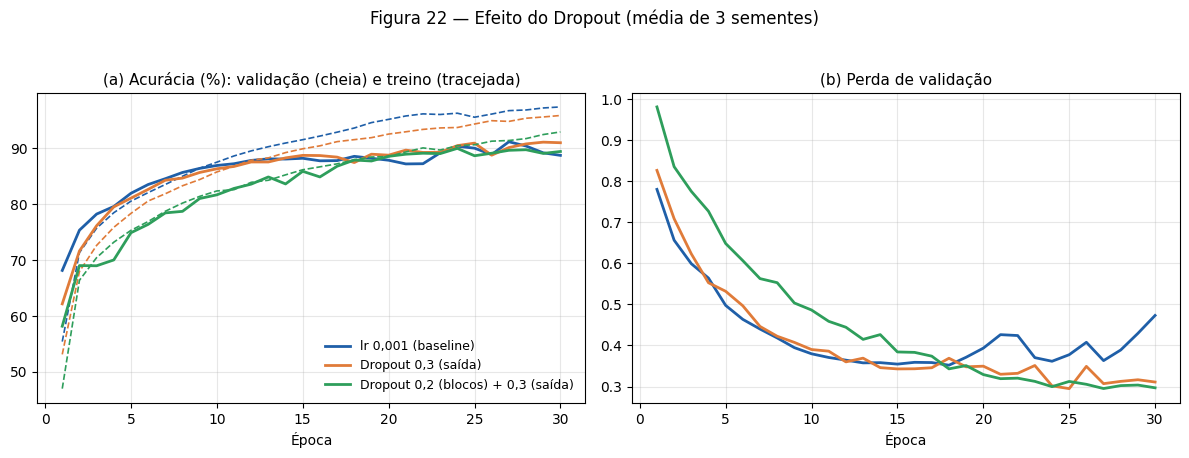

In [162]:
# Figura 22 — Dropout: médias de 3 sementes (linha cheia = validação; tracejada = treino)
confs = [('lr 0,001 (baseline)', '#1F5FA8'), ('Dropout 0,3 (saída)', '#E07B39'),
         ('Dropout 0,2 (blocos) + 0,3 (saída)', '#2E9E5B')]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
for nome, cor in confs:
    tr = np.array([100 * curvas[(nome, s)]['accuracy'].values for s in SEMENTES]).mean(axis=0)
    va = np.array([100 * curvas[(nome, s)]['val_accuracy'].values for s in SEMENTES]).mean(axis=0)
    vl = np.array([curvas[(nome, s)]['val_loss'].values for s in SEMENTES]).mean(axis=0)
    ep = np.arange(1, len(va) + 1)
    ax1.plot(ep, va, color=cor, lw=2, label=nome)
    ax1.plot(ep, tr, color=cor, lw=1.2, ls='--')
    ax2.plot(ep, vl, color=cor, lw=2, label=nome)
ax1.set_title('(a) Acurácia (%): validação (cheia) e treino (tracejada)', fontsize=11)
ax2.set_title('(b) Perda de validação', fontsize=11)
for ax in (ax1, ax2):
    ax.set_xlabel('Época')
    ax.grid(alpha=0.3)
ax1.legend(frameon=False, loc='lower right', fontsize=9)
fig.suptitle('Figura 22 — Efeito do Dropout (média de 3 sementes)', fontsize=12, y=1.03)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig22_dropout.png', dpi=200, bbox_inches='tight')
plt.show()

**Observação — Passo 25 (Dropout)**

**Resultados.** Em média de três sementes, a melhor acurácia de validação foi de 91,72% no baseline, 91,58% com Dropout 0,3 na saída (desvio 0,87) e 90,57% com Dropout 0,2 nos blocos mais 0,3 na saída (desvio 1,72). As diferenças na melhor época são menores que a incerteza da medida (cerca de ±0,9 ponto) e, portanto, não permitem apontar um vencedor.

**Estabilidade ao final do treino.** Na última época, a acurácia de validação foi de 88,73% no baseline e de 90,99% com Dropout na saída, e a diferença entre treino e validação caiu de 8,7 para 4,9 pontos. A Figura 22 mostra a mesma história na perda de validação: no baseline ela cai até cerca de 0,35 e volta a subir nas últimas épocas (sobreajuste), enquanto com Dropout na saída ela se estabiliza em torno de 0,3. O Dropout na saída não elevou o melhor resultado, mas deixou o modelo menos dependente da escolha da melhor época.

**Dropout nos blocos.** A variante com Dropout também após cada bloco aprende mais devagar: a acurácia de treino terminou em 92,9% e a perda de validação ainda caía na época 30, chegando ao menor valor das três. Ainda assim, teve a pior média de acurácia (90,57%) e a maior variação entre sementes (88,6%, 91,2% e 91,9%). Com apenas 30 épocas, essa regularização forte não rendeu ganho de acurácia.

**Decisão.** Manter o Dropout de 0,3 na saída como candidato ao modelo final, pelo ganho de estabilidade sem custo na melhor época. A variante com Dropout nos blocos fica de fora por ora, e voltaremos a ela só se o treino final usar mais épocas. Seguimos com o aumento de dados.

## Passo 26 — Experimento 3: aumento de dados

No aumento de dados, a cada época cada imagem de treino chega à rede levemente modificada (rotação, zoom e deslocamento pequenos), sem mudar o rótulo. Assim, a rede não vê duas vezes exatamente a mesma imagem e aprende a reconhecer a estrutura, e não a posição ou o enquadramento. As transformações atuam apenas durante o treino; a validação e o teste usam as imagens originais. A técnica não adiciona parâmetros.

**Transformações usadas:** rotação de até cerca de ±11°, zoom de ±10% e deslocamento de ±5% da imagem, com preenchimento preto nas bordas (compatível com o fundo das imagens). Não usamos espelhamento horizontal: como o conjunto mistura cortes de planos diferentes, não é possível garantir que o espelhamento preserve a anatomia; fica registrado como limitação.

**Variantes testadas** (taxa de aprendizado 0,001, três sementes cada):
1. Aumento suave.
2. Aumento suave + Dropout de 0,3 na saída.

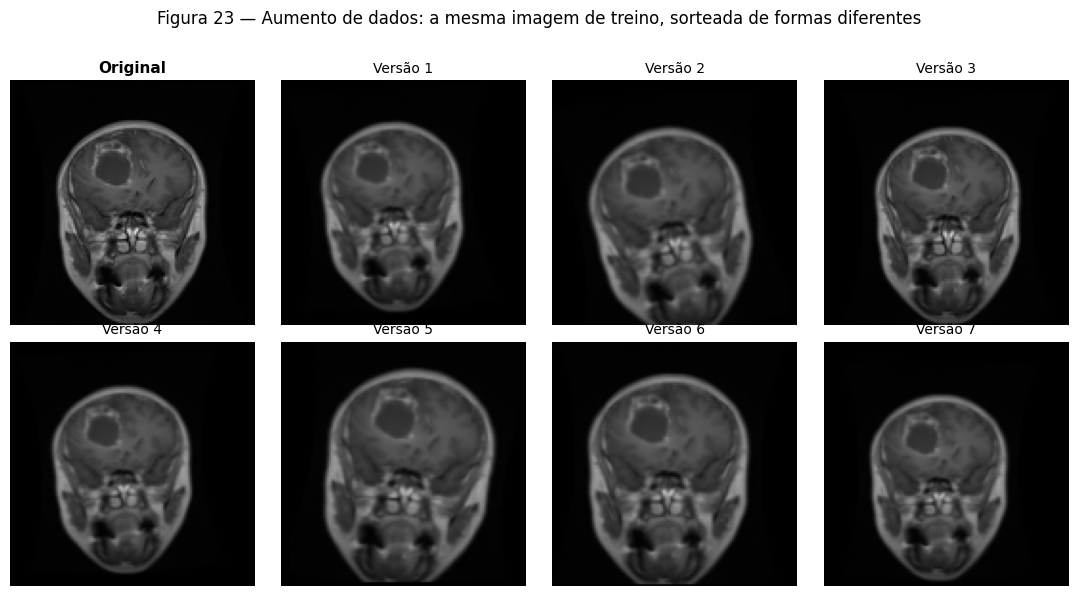

In [163]:
# Figura 23 — Exemplos de aumento de dados (mesma imagem de treino, 7 versões sorteadas)
def criar_aumento():
    return keras.Sequential([
        layers.RandomRotation(0.03, fill_mode='constant', fill_value=0.0),
        layers.RandomZoom(0.1, fill_mode='constant', fill_value=0.0),
        layers.RandomTranslation(0.05, 0.05, fill_mode='constant', fill_value=0.0),
    ], name='aumento')

base = x_tr[348:349]                      # a mesma imagem de treino usada antes (glioma)
aug_demo = criar_aumento()
fig, axes = plt.subplots(2, 4, figsize=(11, 5.8))
axes[0, 0].imshow(base[0, :, :, 0], cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title('Original', fontsize=11, fontweight='bold')
for k, eixo in enumerate(axes.flat[1:], start=1):
    keras.utils.set_random_seed(k)
    versao = aug_demo(base, training=True).numpy()
    eixo.imshow(versao[0, :, :, 0], cmap='gray', vmin=0, vmax=255)
    eixo.set_title(f'Versão {k}', fontsize=10)
for eixo in axes.flat:
    eixo.axis('off')
fig.suptitle('Figura 23 — Aumento de dados: a mesma imagem de treino, sorteada de formas diferentes',
             fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig23_aumento_exemplos.png', dpi=200, bbox_inches='tight')
plt.show()

In [164]:
# Passo 26 — Experimento 3: aumento de dados (3 sementes cada)
variantes_aug = [
    ('Aumento suave', dict(aumento=lambda t: criar_aumento()(t))),
    ('Aumento suave + Dropout 0,3 (saída)', dict(aumento=lambda t: criar_aumento()(t), dropout_saida=0.3)),
]
for nome, op in variantes_aug:
    for s in SEMENTES:
        t0 = time.time()
        d = treinar_reg(nome, semente=s, **op)
        print(f'{nome} | semente {s}: melhor val acc {100 * d["val_accuracy"].max():.1f}% '
              f'| {(time.time() - t0) / 60:.1f} min')

tab_exp = resumo()
display(tab_exp)
tab_exp.to_csv(f'{RELATORIO_DIR}/tab13_experimentos_aumento.csv', encoding='utf-8-sig')

Aumento suave | semente 42: melhor val acc 87.9% | 1.7 min
Aumento suave | semente 43: melhor val acc 89.8% | 1.7 min
Aumento suave | semente 44: melhor val acc 79.3% | 1.6 min
Aumento suave + Dropout 0,3 (saída) | semente 42: melhor val acc 84.7% | 1.5 min
Aumento suave + Dropout 0,3 (saída) | semente 43: melhor val acc 87.8% | 1.5 min
Aumento suave + Dropout 0,3 (saída) | semente 44: melhor val acc 75.1% | 1.5 min


,melhor_val_acc,desvio,val_acc_final,train_acc_final
experimento,,,,
"lr 0,01",86.26,1.45,82.36,90.88
"lr 0,001 (baseline)",91.72,0.34,88.73,97.40
"lr 0,0001",82.71,1.75,82.71,83.40
"Dropout 0,3 (saída)",91.58,0.87,90.99,95.86
"Dropout 0,2 (blocos) + 0,3 (saída)",90.57,1.72,89.42,92.92
Aumento suave,85.66,5.56,79.75,92.10
"Aumento suave + Dropout 0,3 (saída)",82.50,6.64,79.40,90.82


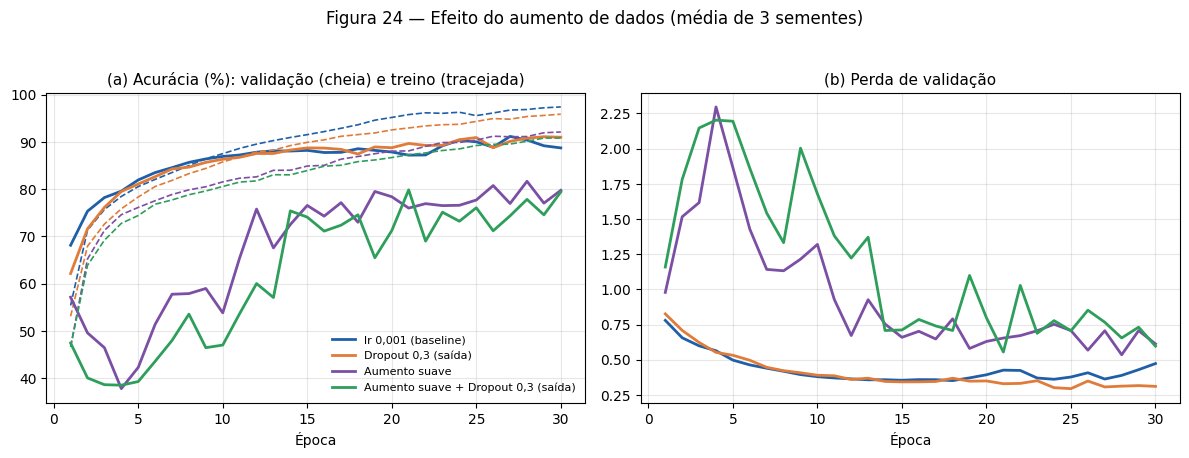

In [165]:
# Figura 24 — Aumento de dados: médias de 3 sementes (cheia = validação; tracejada = treino)
confs = [('lr 0,001 (baseline)', '#1F5FA8'), ('Dropout 0,3 (saída)', '#E07B39'),
         ('Aumento suave', '#7B4FA3'), ('Aumento suave + Dropout 0,3 (saída)', '#2E9E5B')]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
for nome, cor in confs:
    tr = np.array([100 * curvas[(nome, s)]['accuracy'].values for s in SEMENTES]).mean(axis=0)
    va = np.array([100 * curvas[(nome, s)]['val_accuracy'].values for s in SEMENTES]).mean(axis=0)
    vl = np.array([curvas[(nome, s)]['val_loss'].values for s in SEMENTES]).mean(axis=0)
    ep = np.arange(1, len(va) + 1)
    ax1.plot(ep, va, color=cor, lw=2, label=nome)
    ax1.plot(ep, tr, color=cor, lw=1.2, ls='--')
    ax2.plot(ep, vl, color=cor, lw=2, label=nome)
ax1.set_title('(a) Acurácia (%): validação (cheia) e treino (tracejada)', fontsize=11)
ax2.set_title('(b) Perda de validação', fontsize=11)
for ax in (ax1, ax2):
    ax.set_xlabel('Época')
    ax.grid(alpha=0.3)
ax1.legend(frameon=False, loc='lower right', fontsize=8)
fig.suptitle('Figura 24 — Efeito do aumento de dados (média de 3 sementes)', fontsize=12, y=1.03)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig24_aumento_dados.png', dpi=200, bbox_inches='tight')
plt.show()

In [166]:
# Passo 26 (tentativa 2) — aumento LEVE (3 sementes)
def criar_aumento_leve():
    return keras.Sequential([
        layers.RandomRotation(0.01, fill_mode='constant', fill_value=0.0),
        layers.RandomZoom(0.05, fill_mode='constant', fill_value=0.0),
        layers.RandomTranslation(0.03, 0.03, fill_mode='constant', fill_value=0.0),
    ], name='aumento_leve')

for s in SEMENTES:
    t0 = time.time()
    d = treinar_reg('Aumento leve', semente=s, aumento=lambda t: criar_aumento_leve()(t))
    print(f'Aumento leve | semente {s}: melhor val acc {100 * d["val_accuracy"].max():.1f}% '
          f'| {(time.time() - t0) / 60:.1f} min')

tab_exp = resumo()
display(tab_exp)
tab_exp.to_csv(f'{RELATORIO_DIR}/tab13_experimentos_aumento.csv', encoding='utf-8-sig')

Aumento leve | semente 42: melhor val acc 88.5% | 1.6 min
Aumento leve | semente 43: melhor val acc 87.9% | 1.5 min
Aumento leve | semente 44: melhor val acc 90.6% | 1.6 min


,melhor_val_acc,desvio,val_acc_final,train_acc_final
experimento,,,,
"lr 0,01",86.26,1.45,82.36,90.88
"lr 0,001 (baseline)",91.72,0.34,88.73,97.40
"lr 0,0001",82.71,1.75,82.71,83.40
"Dropout 0,3 (saída)",91.58,0.87,90.99,95.86
"Dropout 0,2 (blocos) + 0,3 (saída)",90.57,1.72,89.42,92.92
Aumento suave,85.66,5.56,79.75,92.10
"Aumento suave + Dropout 0,3 (saída)",82.50,6.64,79.40,90.82
Aumento leve,89.00,1.42,81.80,93.48


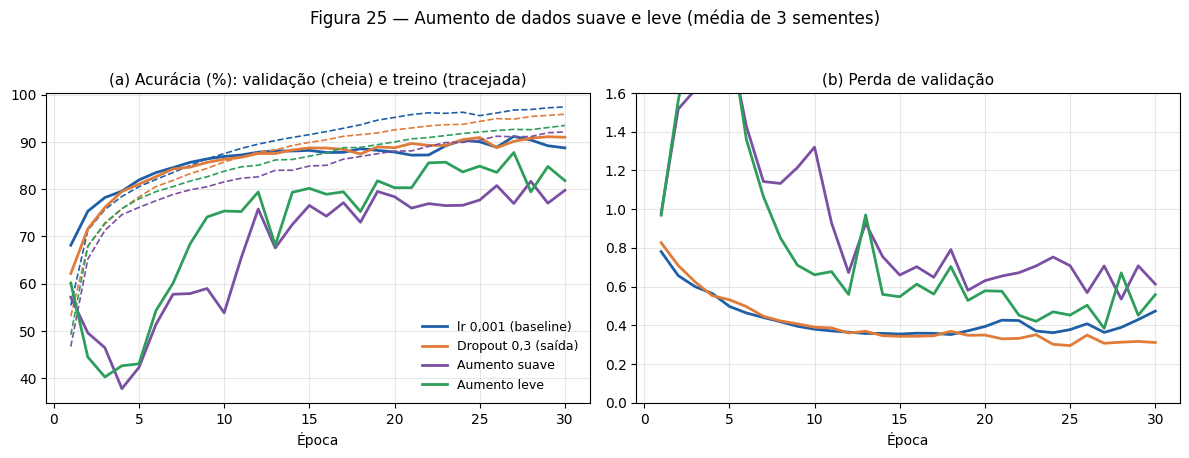

In [167]:
# Figura 25 — Aumento de dados: suave x leve (médias de 3 sementes)
confs = [('lr 0,001 (baseline)', '#1F5FA8'), ('Dropout 0,3 (saída)', '#E07B39'),
         ('Aumento suave', '#7B4FA3'), ('Aumento leve', '#2E9E5B')]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
for nome, cor in confs:
    tr = np.array([100 * curvas[(nome, s)]['accuracy'].values for s in SEMENTES]).mean(axis=0)
    va = np.array([100 * curvas[(nome, s)]['val_accuracy'].values for s in SEMENTES]).mean(axis=0)
    vl = np.array([curvas[(nome, s)]['val_loss'].values for s in SEMENTES]).mean(axis=0)
    ep = np.arange(1, len(va) + 1)
    ax1.plot(ep, va, color=cor, lw=2, label=nome)
    ax1.plot(ep, tr, color=cor, lw=1.2, ls='--')
    ax2.plot(ep, vl, color=cor, lw=2, label=nome)
ax1.set_title('(a) Acurácia (%): validação (cheia) e treino (tracejada)', fontsize=11)
ax2.set_title('(b) Perda de validação', fontsize=11)
ax2.set_ylim(0, 1.6)
for ax in (ax1, ax2):
    ax.set_xlabel('Época')
    ax.grid(alpha=0.3)
ax1.legend(frameon=False, loc='lower right', fontsize=9)
fig.suptitle('Figura 25 — Aumento de dados suave e leve (média de 3 sementes)', fontsize=12, y=1.03)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig25_aumento_leve.png', dpi=200, bbox_inches='tight')
plt.show()

**Observação — Passo 26 (aumento de dados)**

**Resultados.** Em média de três sementes, a melhor acurácia de validação foi de 85,66% com o aumento suave (desvio 5,56), 82,5% com o aumento suave mais Dropout 0,3 na saída (sementes: 84,7%, 87,8% e 75,1%) e 89,0% com o aumento leve (sementes: 88,5%, 87,9% e 90,6%), contra 91,72% do baseline e 91,58% do Dropout na saída. Todas as variantes com aumento ficaram abaixo, e as diferenças são maiores que a incerteza da medida (cerca de ±0,9 ponto).

**Curvas (Figura 25).** Com aumento de dados, a acurácia de validação cai para perto de 40% nas primeiras épocas e a perda de validação apresenta picos, e só depois a rede se recupera. O baseline e o Dropout não mostram esse comportamento. Mesmo no aumento leve a curva continua oscilante e termina abaixo das demais. No aumento suave, a acurácia de treino chegou a 92,1% contra 79,8% na última época de validação, o que indica que a rede aprendeu as imagens modificadas, mas transferiu mal para as imagens originais.

**Interpretação.** Uma explicação plausível, que não foi testada, é a diferença entre as imagens de treino, reamostradas pelas transformações (levemente borradas e com cantos pretos), e as imagens de validação, nítidas e sem alteração; uma rede sem camadas de normalização tende a ser sensível a essa diferença. Outra possibilidade é que 30 épocas sejam poucas para a rede aprender com imagens variadas a cada época.

**Decisão.** Descartar o aumento de dados nesta configuração. O modelo final usará o Dropout de 0,3 na saída, com taxa de aprendizado 0,001. Registramos como limitação e trabalho futuro o uso de normalização, mais épocas e outras transformações (inclusive o espelhamento).

## Passo 27 — Modelo final

Com base nos experimentos (Passos 23 a 26), o modelo final usa a arquitetura de quatro blocos, Dropout de 0,3 na saída, taxa de aprendizado 0,001, lotes de 32 e até 30 épocas, sem aumento de dados. Treinamos com a semente 42, definida desde o início do trabalho, sem escolher a melhor semente a posteriori; o desempenho esperado da configuração é a média das três sementes (91,6% de melhor acurácia de validação). O melhor ponto do treino (maior acurácia de validação) é salvo e recarregado. Em seguida, avaliamos a validação por classe (precisão, revocação e F1) e a matriz de confusão. O conjunto de teste continua intocado.

In [168]:
# Passo 27 — Modelo final: Dropout 0,3 (saída), semente 42
modelo_final = compilar(construir_modelo_reg(dropout_saida=0.3, semente=SEED))
hist_final = modelo_final.fit(x_tr, y_tr, batch_size=CONFIG['batch'], epochs=CONFIG['epocas_max'],
                              validation_data=(x_va, y_va), callbacks=callbacks_padrao('final'),
                              shuffle=True, verbose=2)

h_final = pd.DataFrame(hist_final.history)
h_final.index = h_final.index + 1
ep_final = int(h_final['val_accuracy'].idxmax())
print(f'\nMelhor época: {ep_final} | val acc {100 * h_final["val_accuracy"].max():.2f}%')
h_final.to_csv(f'{RELATORIO_DIR}/hist_final.csv', encoding='utf-8-sig')

# recarrega o melhor ponto salvo pelo checkpoint
modelo_final = keras.models.load_model(f'{PASTA_MODELOS}/final.keras')
perda_va, acc_va = modelo_final.evaluate(x_va, y_va, verbose=0)
print(f'Modelo recarregado | validação: perda {perda_va:.3f} | acurácia {100 * acc_va:.2f}%')

Epoch 1/30
123/123 - 13s - 109ms/step - accuracy: 0.5226 - loss: 1.1217 - val_accuracy: 0.6482 - val_loss: 0.8032
Epoch 2/30
123/123 - 3s - 23ms/step - accuracy: 0.6723 - loss: 0.7742 - val_accuracy: 0.6754 - val_loss: 0.7547
Epoch 3/30
123/123 - 3s - 23ms/step - accuracy: 0.7214 - loss: 0.6925 - val_accuracy: 0.7620 - val_loss: 0.6450
Epoch 4/30
123/123 - 3s - 25ms/step - accuracy: 0.7449 - loss: 0.6350 - val_accuracy: 0.7902 - val_loss: 0.5701
Epoch 5/30
123/123 - 3s - 23ms/step - accuracy: 0.7710 - loss: 0.5681 - val_accuracy: 0.8132 - val_loss: 0.5536
Epoch 6/30
123/123 - 3s - 23ms/step - accuracy: 0.7994 - loss: 0.5233 - val_accuracy: 0.8205 - val_loss: 0.5310
Epoch 7/30
123/123 - 3s - 23ms/step - accuracy: 0.8092 - loss: 0.4828 - val_accuracy: 0.8486 - val_loss: 0.4607
Epoch 8/30
123/123 - 3s - 24ms/step - accuracy: 0.8317 - loss: 0.4403 - val_accuracy: 0.8528 - val_loss: 0.4297
Epoch 9/30
123/123 - 3s - 25ms/step - accuracy: 0.8386 - loss: 0.4174 - val_accuracy: 0.8612 - val_los

,precision,recall,f1-score,support
glioma,0.923,0.909,0.916,276.000
meningioma,0.868,0.868,0.868,258.000
notumor,0.964,0.905,0.934,148.000
pituitary,0.913,0.957,0.935,276.000
accuracy,0.911,0.911,0.911,0.911
macro avg,0.917,0.910,0.913,958.000
weighted avg,0.912,0.911,0.911,958.000


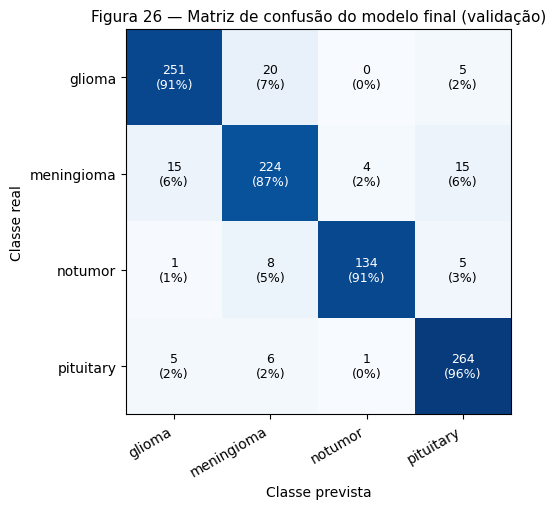

In [169]:
# Métricas por classe na VALIDAÇÃO + Figura 26 (matriz de confusão)
from sklearn.metrics import classification_report, confusion_matrix

prob_va = modelo_final.predict(x_va, verbose=0)
pred_va = prob_va.argmax(axis=1)

rel = classification_report(y_va, pred_va, target_names=CLASSES, digits=3, output_dict=True)
tab_rel = pd.DataFrame(rel).T.round(3)
display(tab_rel)
tab_rel.to_csv(f'{RELATORIO_DIR}/tab14_metricas_validacao.csv', encoding='utf-8-sig')

cm = confusion_matrix(y_va, pred_va)
cm_pct = 100 * cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5.2))
ax.imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(4)); ax.set_xticklabels(CLASSES, rotation=30, ha='right')
ax.set_yticks(range(4)); ax.set_yticklabels(CLASSES)
for lin in range(4):
    for col in range(4):
        ax.text(col, lin, f'{cm[lin, col]}\n({cm_pct[lin, col]:.0f}%)', ha='center', va='center',
                color='white' if cm_pct[lin, col] > 50 else 'black', fontsize=9)
ax.set_xlabel('Classe prevista')
ax.set_ylabel('Classe real')
ax.set_title('Figura 26 — Matriz de confusão do modelo final (validação)', fontsize=11)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig26_matriz_confusao_validacao.png', dpi=200, bbox_inches='tight')
plt.show()

**Observação — Passo 27 (modelo final, validação)**

**Resultados.** O modelo final acertou 873 das 958 imagens de validação (91,1%), dentro da faixa das três sementes do Passo 25 (90,6% a 92,3%). A revocação por classe foi de 95,7% para pituitária, 90,9% para glioma, 90,5% para notumor e 86,8% para meningioma; a precisão foi de 96,4% para notumor, 92,3% para glioma, 91,3% para pituitária e 86,8% para meningioma (valores calculados a partir da matriz de confusão da Figura 26).

**Erros mais frequentes.** A principal confusão ocorre entre glioma e meningioma: 20 gliomas foram previstos como meningioma e 15 meningiomas como glioma. O meningioma também foi previsto como pituitária em 15 casos. Os tumores de pituitária foram os mais bem reconhecidos.

**Leitura binária (tumor versus sem tumor).** Das 810 imagens com tumor, 5 foram classificadas como "notumor" (sensibilidade de 99,4%); das 148 imagens sem tumor, 14 foram classificadas como tumor (90,5% de acerto). Os erros se concentram, portanto, em alarmes falsos, e não em tumores não detectados.

**Classe "notumor".** Embora tenha menos imagens no treino, sua revocação (90,5%) é semelhante à das demais classes; por isso, não realizamos o experimento de pesos por classe.

**Ressalva.** A validação foi usada para escolher a configuração e a época do modelo, de modo que essas métricas são ligeiramente otimistas. A avaliação no conjunto de teste, intocado até aqui, mostrará o desempenho em dados realmente novos.

**Fim da Fase 4.**

In [170]:
# Inventário das matrizes carregadas (apenas leitura; não altera nada)
for nm, vv in list(globals().items()):
    if isinstance(vv, np.ndarray) and vv.size > 1000:
        print(f'{nm:15s} forma={vv.shape}  tipo={vv.dtype}')

base            forma=(1, 128, 128, 1)  tipo=float32
X_tr            forma=(5600, 2304)  tipo=float32
X_te            forma=(1600, 2304)  tipo=float32
C               forma=(1600, 5600)  tipo=float32
melhor          forma=(1600,)  tipo=int64
V_a             forma=(24, 2304)  tipo=float32
V_b             forma=(18, 2304)  tipo=float32
manter          forma=(5600,)  tipo=bool
X_tr_limpo      forma=(4867, 2304)  tipo=float32
C_tr            forma=(4867, 4867)  tipo=float32
rotulo_grupo    forma=(4867,)  tipo=int32
idx_tr          forma=(3909,)  tipo=int64
perm            forma=(4867,)  tipo=int64
tr_a            forma=(3909,)  tipo=int64
mapa            forma=(8, 8, 256)  tipo=float32
amostra         forma=(128, 128, 1)  tipo=uint8
mapas           forma=(128, 128, 32)  tipo=float32
lote            forma=(64, 128, 128, 1)  tipo=float32
saida_antes     forma=(1, 128, 128, 32)  tipo=float32
saida_depois    forma=(1, 128, 128, 32)  tipo=float32
m_antes         forma=(128, 128, 32)  tipo=float

In [171]:
# Inventário 2 (apenas leitura): variáveis que não são matrizes + funções de carga
import types, inspect
print('--- variáveis (não matrizes) ---')
for nm, vv in list(globals().items()):
    if nm.startswith('_') or isinstance(vv, (types.ModuleType, type, np.ndarray)):
        continue
    if isinstance(vv, types.FunctionType):
        continue
    tam = len(vv) if hasattr(vv, '__len__') else ''
    txt = vv if isinstance(vv, str) and len(vv) < 120 else ''
    print(f'{nm:20s} {type(vv).__name__:16s} {tam} {txt}')

print('\n--- funções definidas no notebook ---')
for nm, vv in list(globals().items()):
    if isinstance(vv, types.FunctionType) and vv.__module__ == '__main__':
        print(nm)

print('\n--- código das funções de carga ---')
for nm, vv in list(globals().items()):
    if isinstance(vv, types.FunctionType) and vv.__module__ == '__main__' \
            and any(p in nm.lower() for p in ('carreg', 'load', 'ler', 'imagem', 'dataset', 'pasta')):
        try:
            print(inspect.getsource(vv))
        except Exception as erro:
            print(nm, '-> não foi possível ler o código:', erro)

--- variáveis (não matrizes) ---
In                   list             172 
Out                  dict             0 
get_ipython          method            
exit                 ZMQExitAutocall   
quit                 ZMQExitAutocall   
ZIP_DRIVE            str              71 /content/drive/MyDrive/BRAIN TUMOR MRI - by Euripedes Gomes/archive.zip
PASTA_PROJETO        str              59 /content/drive/MyDrive/BRAIN TUMOR MRI - by Euripedes Gomes
RELATORIO_DIR        str              69 /content/drive/MyDrive/BRAIN TUMOR MRI - by Euripedes Gomes/relatorio
ZIP_LOCAL            str              20 /content/archive.zip
DATA_DIR             str              13 /content/data
TRAIN_DIR            str              22 /content/data/Training
TEST_DIR             str              21 /content/data/Testing
CLASSES              list             4 
SEED                 int               
SUBSETS              dict             2 
linhas               list             4 
nome                 str       

In [172]:
# Inventário 3 (apenas leitura): como as imagens foram carregadas e redimensionadas
import re
padrao = re.compile(r'resize|convert\(|Image\.open|imread|load_img|image_dataset|uint8|reshape')
contador = 0
for k, cel in enumerate(In):
    if 'TRAIN_DIR' in cel or 'TEST_DIR' in cel or 'resize' in cel:
        for lin in cel.splitlines():
            if padrao.search(lin) and contador < 40:
                print(k, '|', lin.strip()[:110])
                contador += 1
print('\nSUBSETS =', SUBSETS)

9 | with Image.open(caminho) as img:
9 | a = np.asarray(img.convert('L').resize((48, 48), Image.BILINEAR), dtype=np.float32).ravel()
18 | with Image.open(caminho) as img:
18 | img = img.convert('L')                                  # tons de cinza
18 | return np.asarray(quadrada.resize((TAM, TAM), Image.LANCZOS), dtype=np.uint8)
50 | with Image.open(caminho) as img:
50 | a = np.asarray(img.convert('L').resize((48, 48), Image.BILINEAR), dtype=np.float32).ravel()
59 | with Image.open(caminho) as img:
59 | img = img.convert('L')                                  # tons de cinza
59 | return np.asarray(quadrada.resize((TAM, TAM), Image.LANCZOS), dtype=np.uint8)
89 | with Image.open(caminho) as img:
89 | a = np.asarray(img.convert('L').resize((48, 48), Image.BILINEAR), dtype=np.float32).ravel()
98 | with Image.open(caminho) as img:
98 | img = img.convert('L')                                  # tons de cinza
98 | return np.asarray(quadrada.resize((TAM, TAM), Image.LANCZOS), dtype=np.uint8)
127

In [173]:
# Inventário 4 (apenas leitura): célula completa que define o carregamento 128x128
print(In[136])

# Passo 10 (parte 2) — Conversão: tons de cinza + bordas pretas até ficar quadrada + redução para 128x128
TAM = 128

def preparar(caminho):
    with Image.open(caminho) as img:
        img = img.convert('L')                                  # tons de cinza
        w, h = img.size
        lado = max(w, h)
        quadrada = Image.new('L', (lado, lado), 0)              # fundo preto
        quadrada.paste(img, ((lado - w) // 2, (lado - h) // 2)) # imagem centralizada
        return np.asarray(quadrada.resize((TAM, TAM), Image.LANCZOS), dtype=np.uint8)

mapa = {c: i for i, c in enumerate(CLASSES)}                    # glioma=0, meningioma=1, notumor=2, pituitary=3
conjuntos = {
    'treino':    tr_limpo[tr_limpo['particao'] == 'treino'],
    'validacao': tr_limpo[tr_limpo['particao'] == 'validacao'],
    'teste':     te,
}

X, y = {}, {}
for nome, d in conjuntos.items():
    X[nome] = np.stack([preparar(c) for c in d['caminho']])[..., np.newaxis]   # (n, 128, 128, 1)
    y[nome] = d['clas

## Fase 5 — Avaliação final no conjunto de teste

## Passo 28 — Avaliação única no teste

O conjunto de teste (1.600 imagens, 400 por classe) foi separado desde o início, não participou do treino nem da escolha de configuração, época ou semente. Ele é avaliado uma única vez, com o modelo final já definido no Passo 27 (melhor ponto salvo pelo checkpoint). Qualquer resultado será reportado como obtido, sem novos ajustes. As imagens de teste foram preparadas pela mesma função de pré-processamento do treino e da validação (tons de cinza, imagem quadrada, 128×128). Como o teste vem de outra pasta do conjunto e passou pela remoção de imagens quase duplicadas, é esperado um desempenho ligeiramente inferior ao da validação.

teste: (1600, 128, 128, 1) float32 | rótulos: (1600,)
imagens por classe: {'glioma': 400, 'meningioma': 400, 'notumor': 400, 'pituitary': 400}
treino idêntico ao pré-processamento original:   True
validação idêntica ao pré-processamento original: True

ACURÁCIA NO TESTE: 81.38%  |  perda: 1.396


,precision,recall,f1-score,support
glioma,0.877,0.710,0.785,400.000
meningioma,0.820,0.615,0.703,400.000
notumor,0.700,0.985,0.818,400.000
pituitary,0.915,0.945,0.930,400.000
accuracy,0.814,0.814,0.814,0.814
macro avg,0.828,0.814,0.809,1600.000
weighted avg,0.828,0.814,0.809,1600.000


,validação,teste
Acurácia (%),91.13,81.38
F1 médio (%),91.31,80.89
Perda,0.33,1.40


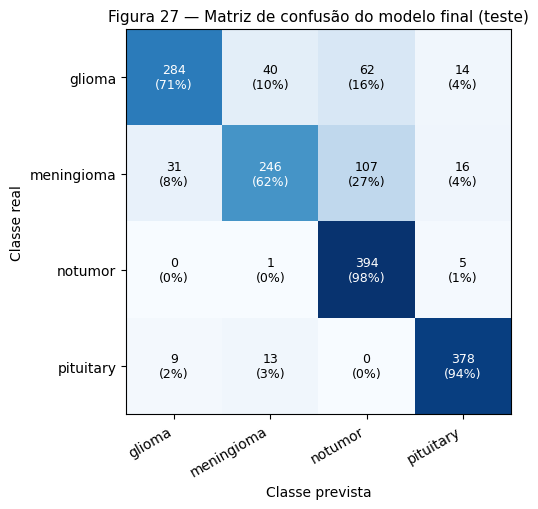

,validação,teste
Imagens com tumor,810.0,1200.0
Tumor classificado como notumor (falso negativo),5.0,169.0
Sensibilidade (%),99.4,85.9
Imagens sem tumor,148.0,400.0
Sem tumor classificado como tumor (falso positivo),14.0,6.0
Especificidade (%),90.5,98.5


In [175]:
# Passo 28 — Avaliação ÚNICA no TESTE (modelo final do Passo 27)
from sklearn.metrics import classification_report

x_te = X['teste'].astype('float32')
y_te = y['teste'].astype('int32')

# Conferências antes de avaliar
print('teste:', x_te.shape, x_te.dtype, '| rótulos:', y_te.shape)
print('imagens por classe:', {c: int(n) for c, n in zip(CLASSES, np.bincount(y_te, minlength=4))})
print('treino idêntico ao pré-processamento original:  ', np.array_equal(x_tr, X['treino'].astype('float32')))
print('validação idêntica ao pré-processamento original:', np.array_equal(x_va, X['validacao'].astype('float32')))

# Avaliação (o modelo não é alterado)
perda_te, acc_te = modelo_final.evaluate(x_te, y_te, verbose=0)
prob_te = modelo_final.predict(x_te, verbose=0)
pred_te = prob_te.argmax(axis=1)
print(f'\nACURÁCIA NO TESTE: {100 * acc_te:.2f}%  |  perda: {perda_te:.3f}')

rel_te = classification_report(y_te, pred_te, target_names=CLASSES, digits=3, output_dict=True)
tab_te = pd.DataFrame(rel_te).T.round(3)
display(tab_te)
tab_te.to_csv(f'{RELATORIO_DIR}/tab15_metricas_teste.csv', encoding='utf-8-sig')

# Validação x teste
comp = pd.DataFrame({
    'validação': [100 * acc_va, 100 * rel['macro avg']['f1-score'], perda_va],
    'teste':     [100 * acc_te, 100 * rel_te['macro avg']['f1-score'], perda_te]},
    index=['Acurácia (%)', 'F1 médio (%)', 'Perda']).round(2)
display(comp)
comp.to_csv(f'{RELATORIO_DIR}/tab16_validacao_vs_teste.csv', encoding='utf-8-sig')# Passo 29 — Matriz de confusão no TESTE (Figura 27) e leitura binária
from sklearn.metrics import confusion_matrix

cm_te = confusion_matrix(y_te, pred_te)
cm_te_pct = 100 * cm_te / cm_te.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5.2))
ax.imshow(cm_te_pct, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(4)); ax.set_xticklabels(CLASSES, rotation=30, ha='right')
ax.set_yticks(range(4)); ax.set_yticklabels(CLASSES)
for lin in range(4):
    for col in range(4):
        ax.text(col, lin, f'{cm_te[lin, col]}\n({cm_te_pct[lin, col]:.0f}%)', ha='center', va='center',
                color='white' if cm_te_pct[lin, col] > 50 else 'black', fontsize=9)
ax.set_xlabel('Classe prevista')
ax.set_ylabel('Classe real')
ax.set_title('Figura 27 — Matriz de confusão do modelo final (teste)', fontsize=11)
fig.tight_layout()
fig.savefig(f'{RELATORIO_DIR}/fig27_matriz_confusao_teste.png', dpi=200, bbox_inches='tight')
plt.show()

def leitura_binaria(rotulos, previsoes):
    ic = CLASSES.index('notumor')
    real_t = rotulos != ic
    prev_t = previsoes != ic
    return {'Imagens com tumor': int(real_t.sum()),
            'Tumor classificado como notumor (falso negativo)': int((real_t & ~prev_t).sum()),
            'Sensibilidade (%)': 100 * (real_t & prev_t).sum() / real_t.sum(),
            'Imagens sem tumor': int((~real_t).sum()),
            'Sem tumor classificado como tumor (falso positivo)': int((~real_t & prev_t).sum()),
            'Especificidade (%)': 100 * (~real_t & ~prev_t).sum() / (~real_t).sum()}

tab_bin = pd.DataFrame({'validação': leitura_binaria(y_va, pred_va),
                        'teste': leitura_binaria(y_te, pred_te)}).round(1)
display(tab_bin)
tab_bin.to_csv(f'{RELATORIO_DIR}/tab17_leitura_binaria.csv', encoding='utf-8-sig')

## Passo 29 — Matriz de confusão no teste e leitura binária

A matriz de confusão mostra, para cada classe real, para quais classes as imagens foram previstas. Complementamos com a leitura binária (tem tumor versus não tem tumor), que separa os erros mais graves (tumor classificado como "notumor") dos alarmes falsos, e a comparamos com a validação.

**Observação — Passos 28 e 29 (avaliação no teste)**

**Resultado geral.** No conjunto de teste (1.600 imagens, 400 por classe), o modelo final obteve acurácia de 81,38%, F1 médio de 80,89% e perda de 1,40, contra 91,13%, 91,31% e 0,33 na validação. Com 1.600 imagens, o erro-padrão da acurácia é de cerca de ±1,0 ponto; portanto, a queda de aproximadamente 10 pontos não é atribuível ao acaso.

**Por classe.** A pituitária manteve bom desempenho (precisão 0,915, revocação 0,945, F1 0,930). O glioma teve revocação de 0,710 e precisão de 0,877 (F1 0,785), o meningioma teve revocação de 0,615 e precisão de 0,820 (F1 0,703), e a classe sem tumor teve revocação de 0,985, mas precisão de apenas 0,700 (F1 0,818).

**Natureza dos erros (Figura 27).** Dos 400 meningiomas, 107 foram classificados como "notumor" e 31 como glioma; dos 400 gliomas, 62 foram classificados como "notumor" e 40 como meningioma. Na leitura binária, 169 dos 1.200 tumores (14,1%) foram classificados como "notumor" (sensibilidade de 85,9%, contra 99,4% na validação), enquanto apenas 6 das 400 imagens sem tumor foram classificadas como tumor (especificidade de 98,5%, contra 90,5% na validação). Assim, o tipo de erro predominante se inverteu: na validação, a rede errava mais por alarme falso; no teste, ela deixa passar tumores, que é o erro mais grave em uma aplicação de triagem.

**Interpretação.** O modelo generalizou pior para o teste do que a validação indicava. A validação foi retirada da mesma pasta do treino (dividida por grupos de imagens semelhantes), enquanto o teste vem de outra pasta do conjunto, o que sugere diferenças de enquadramento, contraste ou aparelho entre as imagens. Essas hipóteses não foram verificadas nesta etapa e são investigadas a seguir, sem alterar o modelo.

**Decisão.** O resultado do teste é reportado como obtido, sem novos ajustes na rede.

## Passo 30 — Por que o teste é mais difícil? (diagnóstico, sem alterar o modelo)

Para entender a queda de desempenho, comparamos o treino, a validação e o teste quanto ao formato original das imagens (quadradas ou não) e ao brilho médio, e verificamos como o modelo se comporta no teste em cada formato. Nenhuma dessas análises altera o modelo nem é usada para novos ajustes.

In [176]:
# Passo 30 — Diagnóstico: formato original, brilho e desempenho por formato (sem alterar o modelo)
from PIL import Image

def eh_quadrada(caminhos):
    saida = []
    for cam in caminhos:
        with Image.open(cam) as img:
            saida.append(img.size[0] == img.size[1])
    return np.array(saida)

dtr = tr_limpo[tr_limpo['particao'] == 'treino']
dva = tr_limpo[tr_limpo['particao'] == 'validacao']
grupos = {'treino': (dtr, x_tr, y_tr), 'validação': (dva, x_va, y_va), 'teste': (te, x_te, y_te)}
quad = {nm: eh_quadrada(g[0]['caminho']) for nm, g in grupos.items()}

linhas_q, linhas_b = {}, {}
for nm, (dd, xx, rot) in grupos.items():
    brilho = xx.mean(axis=(1, 2, 3))
    linhas_q[nm] = {c: 100 * quad[nm][rot == i].mean() for i, c in enumerate(CLASSES)}
    linhas_b[nm] = {c: brilho[rot == i].mean() for i, c in enumerate(CLASSES)}

tab_quad = pd.DataFrame(linhas_q).round(1)
tab_bri = pd.DataFrame(linhas_b).round(1)
print('% de imagens originais QUADRADAS, por classe e conjunto')
display(tab_quad)
print('Brilho médio (0 a 255), por classe e conjunto')
display(tab_bri)
tab_quad.to_csv(f'{RELATORIO_DIR}/tab18_pct_quadradas.csv', encoding='utf-8-sig')
tab_bri.to_csv(f'{RELATORIO_DIR}/tab19_brilho_medio.csv', encoding='utf-8-sig')

# Desempenho no TESTE por formato da imagem original
acerto = (pred_te == y_te)
linhas = []
for forma, mascara in [('quadrada', quad['teste']), ('não quadrada', ~quad['teste'])]:
    linha = {'forma': forma, 'imagens': int(mascara.sum()), 'acurácia (%)': 100 * acerto[mascara].mean()}
    for i, c in enumerate(CLASSES):
        m = mascara & (y_te == i)
        linha[f'n {c}'] = int(m.sum())
        linha[f'revocação {c} (%)'] = 100 * acerto[m].mean() if m.sum() > 0 else np.nan
    linhas.append(linha)
tab_forma = pd.DataFrame(linhas).set_index('forma').round(1)
print('Desempenho no teste por formato da imagem original')
display(tab_forma)
tab_forma.to_csv(f'{RELATORIO_DIR}/tab20_teste_por_formato.csv', encoding='utf-8-sig')

% de imagens originais QUADRADAS, por classe e conjunto


,treino,validação,teste
glioma,100.0,100.0,83.8
meningioma,98.1,97.7,75.5
notumor,29.9,41.2,30.0
pituitary,97.0,99.6,100.0


Brilho médio (0 a 255), por classe e conjunto


,treino,validação,teste
glioma,33.099998,33.000000,39.099998
meningioma,40.700001,40.900002,47.200001
notumor,57.700001,56.799999,54.000000
pituitary,49.299999,49.599998,49.200001


Desempenho no teste por formato da imagem original


,imagens,acurácia (%),n glioma,revocação glioma (%),n meningioma,revocação meningioma (%),n notumor,revocação notumor (%),n pituitary,revocação pituitary (%)
forma,,,,,,,,,,
quadrada,1157,88.3,335,84.8,302,79.8,120,99.2,400,94.5
não quadrada,443,63.2,65,0.0,98,5.1,280,98.2,0,NaN


In [177]:
# Passo 30 (continuação) — impressão compacta para leitura (apenas leitura)
print('% de imagens originais QUADRADAS (linhas = classe; colunas = conjunto)')
print(tab_quad.to_string())
print('\nBrilho médio (0 a 255)')
print(tab_bri.to_string())
print('\nTeste por formato (transposta)')
print(tab_forma.T.to_string())

ns = ~quad['teste']
real_ns = pd.Series(y_te[ns]).map(dict(enumerate(CLASSES)))
prev_ns = pd.Series(pred_te[ns]).map(dict(enumerate(CLASSES)))
print('\nIMAGENS NÃO QUADRADAS DO TESTE: classe real (linhas) x classe prevista (colunas)')
print(pd.crosstab(real_ns, prev_ns, rownames=['real'], colnames=['previsto']).to_string())

% de imagens originais QUADRADAS (linhas = classe; colunas = conjunto)
            treino  validação  teste
glioma       100.0      100.0   83.8
meningioma    98.1       97.7   75.5
notumor       29.9       41.2   30.0
pituitary     97.0       99.6  100.0

Brilho médio (0 a 255)
               treino  validação      teste
glioma      33.099998  33.000000  39.099998
meningioma  40.700001  40.900002  47.200001
notumor     57.700001  56.799999  54.000000
pituitary   49.299999  49.599998  49.200001

Teste por formato (transposta)
forma                     quadrada  não quadrada
imagens                     1157.0         443.0
acurácia (%)                  88.3          63.2
n glioma                     335.0          65.0
revocação glioma (%)          84.8           0.0
n meningioma                 302.0          98.0
revocação meningioma (%)      79.8           5.1
n notumor                    120.0         280.0
revocação notumor (%)         99.2          98.2
n pituitary                

**Observação — Passo 30 (diagnóstico do desempenho no teste)**

**Desempenho por formato.** No teste, a acurácia foi de 88,3% nas 1.157 imagens originalmente quadradas e de apenas 63,2% nas 443 não quadradas (que recebem faixas pretas de preenchimento ao serem convertidas em quadradas). Nas imagens quadradas, a revocação foi de 84,8% para glioma, 79,8% para meningioma, 99,2% para notumor e 94,5% para pituitária. Nas não quadradas, a revocação foi de 0,0% para glioma (65 imagens), 5,1% para meningioma (98 imagens) e 98,2% para notumor (280 imagens); todas as 400 imagens de pituitária do teste são quadradas.

**Para onde vão os erros.** Entre as imagens não quadradas, 54 dos 65 gliomas e 84 dos 98 meningiomas foram classificados como "notumor". Esses 138 casos correspondem a cerca de 82% dos 169 tumores classificados como "notumor" no teste (Passo 29).

**Brilho.** O brilho médio (0 a 255) difere menos que o formato: glioma 33,1 (treino), 33,0 (validação) e 39,1 (teste); meningioma 40,7, 40,9 e 47,2; notumor 57,7, 56,8 e 54,0; pituitária 49,3, 49,6 e 49,2.

**Interpretação.** O padrão é compatível com um atalho: a rede parece ter associado imagens com faixas pretas de preenchimento à classe "notumor", em vez de basear a decisão apenas no tecido cerebral. No teste, 70% das imagens "notumor" (280 de 400) são não quadradas, e os tumores não quadrados são classificados como "notumor". Como a validação foi extraída da mesma pasta do treino, ela não revelou esse problema, e a acurácia de 91,1% superestimou o desempenho em dados novos. O resultado do teste (81,4%) é o número a ser reportado.

**Trabalho futuro.** Remover ou padronizar as faixas de preenchimento (por exemplo, recortar as bordas pretas ou redimensionar sem preencher), avaliar a validação separadamente por formato e testar o aumento de dados com imagens de formatos variados.

**Fim da Fase 5.**

In [178]:
# Só leitura: % de imagens originais QUADRADAS por classe e conjunto
print(tab_quad.to_string())

            treino  validação  teste
glioma       100.0      100.0   83.8
meningioma    98.1       97.7   75.5
notumor       29.9       41.2   30.0
pituitary     97.0       99.6  100.0


**Origem do atalho.** A proporção de imagens originais quadradas por classe (treino, validação e teste) foi de 100,0%, 100,0% e 83,8% para glioma; 98,1%, 97,7% e 75,5% para meningioma; 29,9%, 41,2% e 30,0% para notumor; e 97,0%, 99,6% e 100,0% para pituitária. No treino, portanto, quase todos os tumores eram quadrados e cerca de 70% das imagens sem tumor não eram; uma imagem com faixas de preenchimento quase sempre significava "sem tumor". No teste, 16% dos gliomas e 24,5% dos meningiomas são não quadrados, uma situação praticamente ausente no treino, e esses casos foram classificados como "notumor". A coincidência entre a distribuição do treino e o padrão de erro no teste sustenta a explicação, mas não a prova de forma causal: isso exigiria retreinar sem as faixas de preenchimento, o que não foi feito.